In [1]:
import pandas as pd




def generate_spf_summary_table(filepathgb, filepathde):
    
    # 1. Daten laden 
    df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
    df_de = pd.read_csv(filepathde, sep=';', low_memory=False)

    #Bereiningung
    df_de['region'] = df_de['region'].replace({'Baden-Wüttemberg': 'Baden-Württemberg'})

    # 2. Grundlegende Filterung: Nur Datensätze mit validem Ergebnis
    df_valid_gb = df_gb[df_gb['aggDomainAntiSpoofingMetadata_isValid'] == True].copy()

    # 2. Grundlegende Filterung: Nur Datensätze mit validem Ergebnis
    df_valid_de = df_de[df_de['aggDomainAntiSpoofingMetadata_isValid'] == True].copy()

    
    # Prozentzahlen
    def get_share(df, column):
        return (df[column].value_counts(normalize=True, dropna=False) * 100).round(2)
 
    # Beispiel DMARC-Durchsetzung:
    print(get_share(df_valid_de, 'generalDMARCData_policyMode'))    
    


    #Kreuztabellen
    cross_tab = pd.crosstab(
    df_valid_de['region'], 
    df_valid_de['generalDMARCData_policyMode'].fillna('Kein DMARC'), 
    normalize='index'
    ) * 100
    print(cross_tab)
    
    # 3. Segmente (Spalten) definieren 
    segments = {
        'Alle GB': df_valid_gb,
        'Unitary (GB)': df_valid_gb[df_valid_gb['tier_id'] == 3],
        'County (E)': df_valid_gb[df_valid_gb['tier_id'] == 1],
        'District (E)': df_valid_gb[df_valid_gb['tier_id'] == 2],

        'Alle DE' : df_valid_de,
        'Kr Stadt' : df_valid_de[df_valid_de['code'].fillna('').astype(str).str.endswith("000") & df_valid_de['tier_id'].isna()],
        'Landkreis' : df_valid_de[df_valid_de['tier_id'] == "Landkreis"],
        'Gemeinde' : df_valid_de[~df_valid_de['code'].fillna('').astype(str).str.endswith("000") & df_valid_de['tier_id'].isna()]
        }

    # Hilfsfunktion für die Formatierung: "XX.XX% (Absolut)"
    def format_cell(count, total):
        if total == 0:
            return "0.00% (0)"
        pct = (count / total) * 100
        return f"{pct:.1f}% ({count})"

    results = {}

    # 4. Iteration über alle definierten Segmente (Spalten)
    for col_name, subset in segments.items():
        total_valid = len(subset)

        # Zeile 1: SPF-Nutzen (errorType beginnt NICHT mit "An SPF record does not exist")
        spf_nutzen_mask = ~subset['spfGeneralData_errorType'].fillna('').astype(str).str.startswith("An SPF record does not exist")
        spf_nutzen_count = spf_nutzen_mask.sum()

        # Zeile 2: Fehlerhafte SPF-Records
        fehlerhaft_count = (subset['spfGeneralData_valid'] == False).sum()

        # Zeile 3: Valide, aber mit Warnungen
        # FIX: Berücksichtigt jetzt auch "[]" als KEINE Warnung
        warnungen_mask = (
            (subset['spfGeneralData_valid'] == True) & 
            (subset['spfGeneralData_warnings'].notna()) & 
            (subset['spfGeneralData_warnings'].astype(str).str.strip() != '') &
            (subset['spfGeneralData_warnings'].astype(str).str.strip() != '[]') 
        )
        warnungen_count = warnungen_mask.sum()

        # Zeilen 4-7: All Qualifier
        pass_count = (subset['spfGeneralData_allQualifier'] == 'pass').sum()
        neutral_count = (subset['spfGeneralData_allQualifier'] == 'neutral').sum()
        softfail_count = (subset['spfGeneralData_allQualifier'] == 'softfail').sum()
        fail_count = (subset['spfGeneralData_allQualifier'] == 'fail').sum()

        # Ergebnisse speichern
        results[col_name] = {
            'Nutzen SPF': format_cell(spf_nutzen_count, total_valid),
            'Fehlerhaft': format_cell(fehlerhaft_count, total_valid),
            'Warnungen': format_cell(warnungen_count, total_valid),
            '+all (pass)': format_cell(pass_count, total_valid),
            '?all (neutral)': format_cell(neutral_count, total_valid),
            '~all (softfail)': format_cell(softfail_count, total_valid),
            '-all (fail)': format_cell(fail_count, total_valid),
            'Gesamt (n)': f"{total_valid}"
        }

    # 5. DataFrame erstellen und sortieren
    df_results = pd.DataFrame(results)

    row_order = [
        'Nutzen SPF',
        'Fehlerhaft',
        'Warnungen',
        '+all (pass)',
        '?all (neutral)',
        '~all (softfail)',
        '-all (fail)',
        'Gesamt (n)'
    ]


    
    
    return df_results.reindex(row_order)

# Ausführen der Funktion
result_df = generate_spf_summary_table('security_gb/antispoofing_data.csv', 'security_de/antispoofing_data.csv')
result_df

FileNotFoundError: [Errno 2] No such file or directory: 'security_gb/antispoofing_data.csv'

In [1]:
from pathlib import Path
from typing import Callable, Union
import pandas as pd

# ==============================================================================
# 1. GENERISCHE KERN-ENGINE
# ==============================================================================

def format_metric_cell(count: int, total: int, mode: str = "pct_count") -> str:
    """Formatiert Zellenwerte nach wissenschaftlichem Standard."""
    if total == 0:
        return "0.0% (0)" if mode == "pct_count" else ("0.0%" if mode == "pct" else "0")
    pct = (count / total) * 100
    
    if mode == "pct_count":
        return f"{pct:.1f}% ({count})"
    elif mode == "pct":
        return f"{pct:.1f}%"
    elif mode == "count":
        return f"{count}"
    return f"{pct:.1f}%"


def calculate_generic_table(
    segments: dict[str, pd.DataFrame], 
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]],
    mode: str = "pct_count"
) -> pd.DataFrame:
    """
    Universeller Berechner:
    - Segmente bilden die ZEILEN (Index)
    - Metriken bilden die SPALTEN
    """
    rows = []
    for segment_name, subset in segments.items():
        total = len(subset)
        row_data = {"Segment": segment_name, "Gesamt (n)": total}
        
        for metric_name, condition_fn in metrics.items():
            if total == 0:
                row_data[metric_name] = format_metric_cell(0, 0, mode)
            else:
                # Ausführen der übergebenen Lambda-Bedingung
                mask = condition_fn(subset)
                count = int(mask.fillna(False).sum())
                row_data[metric_name] = format_metric_cell(count, total, mode)
                
        rows.append(row_data)
        
    return pd.DataFrame(rows).set_index("Segment")


def _prepare_df(data: Union[str, Path, pd.DataFrame], filter_valid: bool = True) -> pd.DataFrame:
    """Hilfsfunktion: Lädt CSV, bereinigt Tippfehler und filtert ungültige Scans."""
    if data is None:
        return None
    if isinstance(data, (str, Path)):
        df = pd.read_csv(data, sep=';', decimal=',', low_memory=False)
    else:
        df = data.copy()

    # Typische Tippfehler in Bundesländern vereinheitlichen
    if 'region' in df.columns:
        df['region'] = df['region'].replace({'Baden-Wüttemberg': 'Baden-Württemberg'})

    # Automatische Filterung auf valide Scan-Ergebnisse (für Anti-Spoofing oder Transport)
    if filter_valid:
        for valid_col in ['aggDomainAntiSpoofingMetadata_isValid', 'aggDataTransportMetadata_isValid']:
            if valid_col in df.columns:
                df = df[df[valid_col] == True].copy()
                break
                
    return df


# ==============================================================================
# 2. FUNKTION 1: ZEILEN = ADMINISTRATIVE EBENEN (DE & GB)
# ==============================================================================

def generate_tier_summary(
    df_de: Union[str, Path, pd.DataFrame] = None,
    df_gb: Union[str, Path, pd.DataFrame] = None,
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    mode: str = "pct_count",
    filter_valid: bool = True
) -> pd.DataFrame:
    """
    Erstellt eine Vergleichstabelle nach administrativen Ebenen.
    Zeilen: Alle GB, Unitary, County, District, Alle DE, Krfr. Städte, Landkreise, Gemeinden.
    """
    df_de = _prepare_df(df_de, filter_valid)
    df_gb = _prepare_df(df_gb, filter_valid)
    segments = {}

    # GB Tiers
    if df_gb is not None and not df_gb.empty:
        tier_num = pd.to_numeric(df_gb['tier_id'], errors='coerce')
        segments['Alle GB'] = df_gb
        segments['Unitary (GB)'] = df_gb[tier_num == 3]
        segments['County (E)'] = df_gb[tier_num == 1]
        segments['District (E)'] = df_gb[tier_num == 2]

    # DE Tiers
    if df_de is not None and not df_de.empty:
        code_str = df_de['code'].fillna('').astype(str).str.strip()
        is_kr_stadt = code_str.str.endswith("000") & df_de['tier_id'].isna()
        is_landkreis = df_de['tier_id'].astype(str).str.lower().str.contains("landkreis|kreis", na=False)
        is_gemeinde = ~code_str.str.endswith("000") & df_de['tier_id'].isna()

        segments['Alle DE'] = df_de
        segments['Krfr. Stadt (DE)'] = df_de[is_kr_stadt]
        segments['Landkreis (DE)'] = df_de[is_landkreis]
        segments['Gemeinde (DE)'] = df_de[is_gemeinde]

    return calculate_generic_table(segments, metrics or {}, mode=mode)


# ==============================================================================
# 2. FUNKTION 1: ZEILEN = ADMINISTRATIVE EBENEN (DE & GB)
# ==============================================================================

from typing import Union, Callable
from pathlib import Path
import pandas as pd

def generate_tier_summary(
    df_de: Union[str, Path, pd.DataFrame] = None,
    df_gb: Union[str, Path, pd.DataFrame] = None,
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    mode: str = "pct_count",
    filter_valid: bool = True,
    base_filter: Callable[[pd.DataFrame], pd.Series] = None,  # Globaler Vorab-Filter
    breakdown_de: bool = True,  # Schalter für die Unterteilung der DE-Verwaltungseinheiten
    breakdown_gb: bool = True   # Schalter für die Unterteilung der GB-Verwaltungseinheiten
) -> pd.DataFrame:
    """
    Erstellt eine Vergleichstabelle nach administrativen Ebenen.
    Zeilen: Alle GB, Unitary, County, District (falls breakdown_gb=True), 
            Alle DE, Krfr. Städte, Landkreise, Gemeinden (falls breakdown_de=True).
    """
    df_de = _prepare_df(df_de, filter_valid)
    df_gb = _prepare_df(df_gb, filter_valid)
    
    # Anwenden des Vorab-Filters
    if base_filter is not None:
        if df_de is not None and not df_de.empty:
            df_de = df_de[base_filter(df_de)].copy()
        if df_gb is not None and not df_gb.empty:
            df_gb = df_gb[base_filter(df_gb)].copy()
    # --------------------------------------------------------------------

    segments = {}

    # GB Tiers
    if df_gb is not None and not df_gb.empty:
        segments['Alle GB'] = df_gb
        
        # Unterteilung nur hinzufügen, wenn breakdown_gb True ist
        if breakdown_gb:
            tier_num = pd.to_numeric(df_gb['tier_id'], errors='coerce')
            segments['Unitary (GB)'] = df_gb[tier_num == 3]
            segments['County (E)'] = df_gb[tier_num == 1]
            segments['District (E)'] = df_gb[tier_num == 2]

    # DE Tiers
    if df_de is not None and not df_de.empty:
        segments['Alle DE'] = df_de
        
        # Unterteilung nur hinzufügen, wenn breakdown_de True ist
        if breakdown_de:
            code_str = df_de['code'].fillna('').astype(str).str.strip()
            is_kr_stadt = code_str.str.endswith("000") & df_de['tier_id'].isna()
            is_landkreis = df_de['tier_id'].astype(str).str.lower().str.contains("landkreis|kreis", na=False)
            is_gemeinde = ~code_str.str.endswith("000") & df_de['tier_id'].isna()

            segments['Krfr. Stadt (DE)'] = df_de[is_kr_stadt]
            segments['Landkreis (DE)'] = df_de[is_landkreis]
            segments['Gemeinde (DE)'] = df_de[is_gemeinde]

    return calculate_generic_table(segments, metrics or {}, mode=mode)
# ==============================================================================
# 3. FUNKTION 2: ZEILEN = FLÄCHENLÄNDER (DE) & LANDESTEILE (GB)
# ==============================================================================

def generate_region_summary(
    df_de: Union[str, Path, pd.DataFrame] = None,
    df_gb: Union[str, Path, pd.DataFrame] = None,
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    exclude_city_states: bool = True,
    add_totals: bool = True,
    mode: str = "pct_count",
    filter_valid: bool = True
) -> pd.DataFrame:
    """
    Erstellt eine Vergleichstabelle nach Regionen:
    1. 13 deutsche Flächenländer (ohne Berlin, Hamburg, Bremen) [+ Gesamt DE]
    2. Die 4 Landesteile von GB: England, Wales, Schottland, Nordirland [+ Gesamt GB]
    """
    city_states = {'Berlin', 'Hamburg', 'Bremen'} if exclude_city_states else set()
    
    df_de = _prepare_df(df_de, filter_valid)
    df_gb = _prepare_df(df_gb, filter_valid)
    
    segments = {}

    # --------------------------------------------------------------------------
    # 1. Deutsche Flächenländer
    # --------------------------------------------------------------------------
    if df_de is not None and not df_de.empty:
        de_regions = sorted([
            r for r in df_de['region'].dropna().unique() 
            if str(r).strip() != '' and r not in city_states
        ])
        for reg in de_regions:
            segments[reg] = df_de[df_de['region'] == reg]
            
        if add_totals:
            segments['Gesamt DE'] = df_de

    # --------------------------------------------------------------------------
    # 2. Landesteile des Vereinigten Königreichs (GB)
    # --------------------------------------------------------------------------
    if df_gb is not None and not df_gb.empty:
        # Feste Reihenfolge und deutsche Übersetzung der UK-Nationen
        gb_order = {
            'England': 'England',
            'Wales': 'Wales',
            'Scotland': 'Schottland',
            'Northern Ireland': 'Nordirland'
        }
        
        for raw_gb, label_de in gb_order.items():
            sub = df_gb[df_gb['region'].astype(str).str.strip().str.lower() == raw_gb.lower()]
            segments[label_de] = sub
            
        if add_totals:
            segments['Gesamt GB'] = df_gb

    return calculate_generic_table(segments, metrics or {}, mode=mode)




from typing import Union, Callable
from pathlib import Path
import pandas as pd

def generate_region_summary(
    df_de: Union[str, Path, pd.DataFrame] = None,
    df_gb: Union[str, Path, pd.DataFrame] = None,
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    exclude_city_states: bool = True,
    add_totals: bool = True,
    mode: str = "pct_count",
    filter_valid: bool = True,
    abbreviations: dict[str, str] = None,
    breakdown_de: bool = True,  # <-- Schalter für deutsche Bundesländer
    breakdown_gb: bool = True   # <-- Schalter für britische Landesteile
) -> pd.DataFrame:
    """
    Erstellt eine Vergleichstabelle nach Regionen:
    1. 13 deutsche Flächenländer (falls breakdown_de=True) [+ Gesamt DE]
    2. Die 4 Landesteile von GB: England, Wales, Schottland, Nordirland (falls breakdown_gb=True) [+ Gesamt GB]
    """
    city_states = {'Berlin', 'Hamburg', 'Bremen'} if exclude_city_states else set()
    
    # Standard-Abkürzungen für lange Namen, falls keine übergeben werden
    if abbreviations is None:
        abbreviations = {
            "Baden-Württemberg": "Baden-Württ.",
            "Nordrhein-Westfalen": "Nordr.-Westf.",
            "Mecklenburg-Vorpommern": "Meckl.-Vorp.",
            "Schleswig-Holstein": "Schles.-Holst.",
            "Rheinland-Pfalz": "Rheinl.-Pfalz",
            "Sachsen-Anhalt": "Sachsen-An.",
            "Niedersachsen" : "Niedersachs."
        }
        
    df_de = _prepare_df(df_de, filter_valid)
    df_gb = _prepare_df(df_gb, filter_valid)
    
    segments = {}

    # --------------------------------------------------------------------------
    # 1. Deutsche Flächenländer
    # --------------------------------------------------------------------------
    if df_de is not None and not df_de.empty:
        # Aufschlüsselung nach Bundesländern nur, wenn breakdown_de = True
        if breakdown_de:
            de_regions = sorted([
                r for r in df_de['region'].dropna().unique() 
                if str(r).strip() != '' and r not in city_states
            ])
            for reg in de_regions:
                display_name = abbreviations.get(reg, reg) 
                segments[display_name] = df_de[df_de['region'] == reg]
                
        # Gesamt DE unabhängig von der Aufschlüsselung hinzufügen
        if add_totals:
            segments['Gesamt DE'] = df_de

    # --------------------------------------------------------------------------
    # 2. Landesteile des Vereinigten Königreichs (GB)
    # --------------------------------------------------------------------------
    if df_gb is not None and not df_gb.empty:
        # Aufschlüsselung nach Landesteilen nur, wenn breakdown_gb = True
        if breakdown_gb:
            # Feste Reihenfolge und deutsche Übersetzung der UK-Nationen
            gb_order = {
                'England': 'England',
                'Wales': 'Wales',
                'Scotland': 'Schottland',
                'Northern Ireland': 'Nordirland'
            }
            
            for raw_gb, label_de in gb_order.items():
                sub = df_gb[df_gb['region'].astype(str).str.strip().str.lower() == raw_gb.lower()]
                segments[label_de] = sub
                
        # Gesamt GB unabhängig von der Aufschlüsselung hinzufügen
        if add_totals:
            segments['Gesamt GB'] = df_gb

    return calculate_generic_table(segments, metrics or {}, mode=mode)




from pathlib import Path
from typing import Callable, Optional, Union
import pandas as pd


def generate_region_summary_all(
    df_de: Union[str, Path, pd.DataFrame] = None,
    df_gb: Union[str, Path, pd.DataFrame] = None,
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    exclude_city_states: bool = True,
    include_state_totals: bool = True,
    add_national_totals: bool = True,
    skip_empty_subtiers: bool = True,
    as_multiindex: bool = False,
    mode: str = "pct_count",
    filter_valid: bool = True,
) -> pd.DataFrame:
    """Erstellt eine detaillierte Übersichtstabelle für explorative Analysen:

    - DE: Jedes Flächenland unterteilt in Krfr. Stadt, Landkreis, Gemeinde
    - GB: England unterteilt in Unitary, County, District; Wales, Schottland,
    Nordirland als Unitary
    - as_multiindex=True erzeugt einen 2-stufigen Index (Region, Ebene) für
    Pandas-Filterung.
    """
    city_states = (
        {"Berlin", "Hamburg", "Bremen"} if exclude_city_states else set()
    )
    df_de = _prepare_df(df_de, filter_valid)
    df_gb = _prepare_df(df_gb, filter_valid)

    # Struktur: (Hauptregion, Unterebene) -> DataFrame-Subset
    raw_segments = {}

    # --------------------------------------------------------------------------
    # 1. DEUTSCHE BUNDESLÄNDER MIT HIERARCHIE-UNTERTEILUNG
    # --------------------------------------------------------------------------
    if df_de is not None and not df_de.empty:
        de_regions = sorted([
            r
            for r in df_de["region"].dropna().unique()
            if str(r).strip() != "" and r not in city_states
        ])

        for reg in de_regions:
            df_reg = df_de[df_de["region"] == reg]

            # Gesamtzeile des Bundeslandes
            if include_state_totals:
                raw_segments[(reg, "Gesamt")] = df_reg

            # Subtiers berechnen
            code_str = df_reg["code"].fillna("").astype(str).str.strip()
            is_kr_stadt = code_str.str.endswith("000") & df_reg["tier_id"].isna()
            is_landkreis = (
                df_reg["tier_id"]
                .astype(str)
                .str.lower()
                .str.contains("landkreis|kreis", na=False)
            )
            is_gemeinde = (
                ~code_str.str.endswith("000") & df_reg["tier_id"].isna()
            )

            subtiers = {
                "Kreisfreie Stadt": df_reg[is_kr_stadt],
                "Landkreis": df_reg[is_landkreis],
                "Gemeinde": df_reg[is_gemeinde],
            }

            for sub_name, sub_df in subtiers.items():
                if skip_empty_subtiers and len(sub_df) == 0:
                    continue
                raw_segments[(reg, sub_name)] = sub_df

        if add_national_totals:
            raw_segments[("Gesamt DE", "Alle")] = df_de

    # --------------------------------------------------------------------------
    # 2. VEREINIGTES KÖNIGREICH MIT ENGLAND-UNTERTEILUNG
    # --------------------------------------------------------------------------
    if df_gb is not None and not df_gb.empty:
        df_eng = df_gb[
            df_gb["region"].astype(str).str.strip().str.lower() == "england"
        ]
        if not df_eng.empty:
            if include_state_totals:
                raw_segments[("England", "Gesamt")] = df_eng

            tier_num = pd.to_numeric(df_eng["tier_id"], errors="coerce")
            eng_subtiers = {
                "Unitary": df_eng[tier_num == 3],
                "County": df_eng[tier_num == 1],
                "District": df_eng[tier_num == 2],
            }
            for sub_name, sub_df in eng_subtiers.items():
                if skip_empty_subtiers and len(sub_df) == 0:
                    continue
                raw_segments[("England", sub_name)] = sub_df

        # Wales, Schottland und Nordirland (alle rein Unitary)
        other_nations = {
            "Wales": "Wales",
            "Scotland": "Schottland",
            "Northern Ireland": "Nordirland",
        }
        for raw_name, label in other_nations.items():
            sub = df_gb[
                df_gb["region"].astype(str).str.strip().str.lower()
                == raw_name.lower()
            ]
            if not sub.empty:
                raw_segments[(label, "Unitary")] = sub

        if add_national_totals:
            raw_segments[("Gesamt GB", "Alle")] = df_gb

    # --------------------------------------------------------------------------
    # 3. KERNBERECHNUNG & INDEX-FORMATIERUNG
    # --------------------------------------------------------------------------
    rows = []
    index_tuples = []
    flat_index = []

    for (reg, sub_name), subset in raw_segments.items():
        total = len(subset) if subset is not None else 0
        row_data = {"Gesamt (n)": total}

        for metric_name, condition_fn in (metrics or {}).items():
            if total == 0:
                row_data[metric_name] = format_metric_cell(0, 0, mode)
            else:
                mask = condition_fn(subset)
                count = int(mask.fillna(False).sum())
                row_data[metric_name] = format_metric_cell(count, total, mode)

        rows.append(row_data)
        index_tuples.append((reg, sub_name))

        # Flacher Einrückungs-Index
        if sub_name in ("Gesamt", "Alle"):
            flat_index.append(f"{reg}")
        elif reg in ("Wales", "Schottland", "Nordirland"):
            flat_index.append(f"{reg}")
        else:
            flat_index.append(f"  {reg} - {sub_name}")

    df_res = pd.DataFrame(rows)

    if as_multiindex:
        df_res.index = pd.MultiIndex.from_tuples(
            index_tuples, names=["Region", "Ebene"]
        )
    else:
        df_res.index = pd.Index(flat_index, name="Region / Ebene")

    return df_res





# Beliebge Übersicht (z.B. für DMARC-Reporte
def generate_custom_summary(
    df: Union[str, Path, pd.DataFrame],
    row_segments: dict[str, Callable[[pd.DataFrame], pd.Series]],
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    mode: str = "pct_count",
    filter_valid: bool = True,
    base_filter: Callable[[pd.DataFrame], pd.Series] = None
) -> pd.DataFrame:
    """
    Erstellt eine komplett flexible Tabelle.
    Zeilen (Segmente) und Spalten (Metriken) werden als Dictionaries mit Lambda-Bedingungen übergeben.
    
    Parameter:
    - row_segments: Dict mit Zeilennamen (Key) und Filter-Bedingung (Value). 
                    Wird 'None' als Bedingung übergeben, wird das gesamte Set genutzt.
    """
    df_prepared = _prepare_df(df, filter_valid)
    
    if df_prepared is None or df_prepared.empty:
        return pd.DataFrame()

    # --- Globaler Vorab-Filter (Grundgesamtheit einschränken) ---
    if base_filter is not None:
        df_prepared = df_prepared[base_filter(df_prepared)].copy()

    segments = {}
    
    # --- Dynamische Segmente (Zeilen) bilden ---
    for segment_name, condition_fn in row_segments.items():
        if condition_fn is None:
            # None signalisiert, dass wir alle Daten dieser Grundgesamtheit wollen
            segments[segment_name] = df_prepared
        else:
            # Ausführen der übergebenen Lambda-Bedingung für die Zeile
            mask = condition_fn(df_prepared)
            segments[segment_name] = df_prepared[mask.fillna(False)]

    return calculate_generic_table(segments, metrics or {}, mode=mode)





def generate_custom_summary_multi(
    df_1: Union[str, Path, pd.DataFrame] = None,
    df_2: Union[str, Path, pd.DataFrame] = None,
    row_segments: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    metrics: dict[str, Callable[[pd.DataFrame], pd.Series]] = None,
    mode: str = "pct_count",
    filter_valid: bool = True,
    base_filter: Callable[[pd.DataFrame], pd.Series] = None
) -> pd.DataFrame:
    """
    Erstellt eine komplett flexible Tabelle aus bis zu zwei Datensätzen.
    Zeilen (Segmente) und Spalten (Metriken) werden als Dictionaries mit Lambda-Bedingungen übergeben.
    
    Die Datensätze werden intern verkettet. Du kannst in den Lambda-Bedingungen auf 
    die Hilfsspalte '_source_dataset' ('df_1' oder 'df_2') zugreifen, um spezifisch zu filtern.
    """
    
    # 1. Daten laden und vorbereiten
    df1_prepared = _prepare_df(df_1, filter_valid)
    df2_prepared = _prepare_df(df_2, filter_valid)
    
    frames_to_concat = []
    
    # 2. Hilfsspalte hinzufügen, um die Herkunft identifizierbar zu machen
    if df1_prepared is not None and not df1_prepared.empty:
        df1_prepared['_source_dataset'] = 'df_1'
        frames_to_concat.append(df1_prepared)
        
    if df2_prepared is not None and not df2_prepared.empty:
        df2_prepared['_source_dataset'] = 'df_2'
        frames_to_concat.append(df2_prepared)
        
    if not frames_to_concat:
         return pd.DataFrame()

    # 3. Datensätze verketten (ignoriert den Index, um Duplikate zu vermeiden)
    combined_df = pd.concat(frames_to_concat, ignore_index=True)

    # 4. Globalen Vorab-Filter anwenden (wirkt auf beide Sets gemeinsam)
    if base_filter is not None:
        combined_df = combined_df[base_filter(combined_df)].copy()

    segments = {}
    row_segments = row_segments or {}
    
    # 5. Dynamische Segmente (Zeilen) bilden
    for segment_name, condition_fn in row_segments.items():
        if condition_fn is None:
            # None = Komplettes verkettetes (und basis-gefiltertes) Set
            segments[segment_name] = combined_df
        else:
            mask = condition_fn(combined_df)
            segments[segment_name] = combined_df[mask.fillna(False)]

    return calculate_generic_table(segments, metrics or {}, mode=mode)


## Hilfsfunktion zur Bestimmung von Top X Provider bei externen Abhängigkeiten

In [2]:
from typing import Optional, Union, Callable, List
import pandas as pd

def get_top_frequencies_old(
    df: pd.DataFrame,
    target_col: str,
    top_n: int = 5,
    row_filter: Optional[Union[Callable[[pd.DataFrame], pd.Series], str, pd.Series]] = None,
    unique_filter_col: Optional[Union[str, List[str]]] = None,
    additional_cols: Optional[List[str]] = None,
    include_na: bool = True,
    pct_base_col: Optional[str] = None
) -> pd.DataFrame:
    """
    Ermittelt die Top-N häufigsten Werte einer Spalte mit Prozentanteil.
    
    Parameter:
    - df: Eingabe-DataFrame
    - target_col: Zu analysierende Spalte (z. B. 'domain')
    - top_n: Anzahl der Top-Werte (Standard: 5)
    - row_filter: Zeilenfilter als Lambda-Funktion (lambda d: ...), 
                  Query-String (z. B. "dependencyType == '...'") oder boolesche Series
    - unique_filter_col: Spalte(n), nach der dedupliziert wird (String oder Liste)
    - additional_cols: Liste weiterer Spalten, deren erster Wert angehängt werden soll
    - include_na: Ob NaN-Werte in der Häufigkeitsverteilung berücksichtigt werden
    - pct_base_col: Die Anzahl der einzigartigen Zeilen dieser Spalte ist der Basiswert für Prozentrechnung
    """
    data = df.copy()

    # 1. Zeilenweise Filterung (vor der Aggregation)
    if row_filter is not None:
        if callable(row_filter):
            mask = row_filter(data)
            data = data[mask.fillna(False)]
        elif isinstance(row_filter, str):
            data = data.query(row_filter)
        elif isinstance(row_filter, pd.Series):
            data = data[row_filter.fillna(False)]

    # 2. Eindeutige Werte filtern (Deduplizierung)
    if unique_filter_col:
        cols = [unique_filter_col] if isinstance(unique_filter_col, str) else list(unique_filter_col)
        valid_subset = [c for c in cols if c in data.columns]
        if valid_subset:
            data = data.drop_duplicates(subset=valid_subset, keep='first')

    # 3. Häufigkeiten und relative Anteile berechnen
    counts = data[target_col].value_counts(dropna=not include_na)

    # BERECHNUNG DES ANTEILS:
    if pct_base_col and pct_base_col in data.columns:
        total_basis = data[pct_base_col].nunique()
        pcts = (counts / total_basis) * 100
    else:
        # Bisheriges Standardverhalten (Summe der Zeilen = 100 %)
        pcts = data[target_col].value_counts(normalize=True, dropna=not include_na) * 100

    top_counts = counts.head(top_n)
    top_pcts = pcts.loc[top_counts.index]

    # Basis-Ergebnis zusammensetzen
    result = pd.DataFrame({
        target_col: top_counts.index,
        'Anzahl (n)': top_counts.values,
        'Anteil (%)': [f"{p:.1f}%" for p in top_pcts.values],
    })

    # 4. Optionale Zusatzspalten anfügen (z. B. Ländercode)
    if additional_cols:
        valid_cols = [c for c in additional_cols if c in data.columns and c != target_col]
        if valid_cols:
            subset_top = data[data[target_col].isin(top_counts.index)]
            first_vals = (
                subset_top.groupby(target_col, observed=False, dropna=False)[valid_cols]
                .first()
                .reset_index()
            )
            result = pd.merge(result, first_vals, on=target_col, how='left')

    return result

In [3]:
from typing import Optional, Union, Callable, List, Dict, Any
import pandas as pd

def get_top_frequencies(
    df: pd.DataFrame,
    target_col: str,
    top_n: Optional[int] = 5,
    row_filter: Optional[Union[Callable[[pd.DataFrame], pd.Series], str, pd.Series]] = None,
    unique_filter_col: Optional[Union[str, List[str]]] = None,
    additional_cols: Optional[List[str]] = None,
    include_na: bool = True,
    pct_base_col: Optional[str] = None,
    keep_total_basis: bool = False,      # total_basis vor row_filter-Filterung
    value_aliases: Optional[Dict[Any, Any]] = None,
    col_name_aliases: Optional[Dict[str, str]] = None
) -> pd.DataFrame:
    """
    Ermittelt die Top-N häufigsten Werte einer Spalte mit Prozentanteil.
    """
    data = df.copy()

    # Spalten für Deduplizierung vorab bestimmen
    valid_subset = []
    if unique_filter_col:
        cols = [unique_filter_col] if isinstance(unique_filter_col, str) else list(unique_filter_col)
        valid_subset = [c for c in cols if c in data.columns]

    # Wenn keep_total_basis=True: Datenstand VOR dem row_filter (inkl. Deduplizierung) für die Basis sichern
    if keep_total_basis:
        base_data = data.drop_duplicates(subset=valid_subset, keep='first') if valid_subset else data

    # 1. Zeilenweise Filterung (vor der Aggregation)
    if row_filter is not None:
        if callable(row_filter):
            mask = row_filter(data)
            data = data[mask.fillna(False)]
        elif isinstance(row_filter, str):
            data = data.query(row_filter)
        elif isinstance(row_filter, pd.Series):
            data = data[row_filter.fillna(False)]

    # 2. Eindeutige Werte filtern (Deduplizierung)
    if valid_subset:
        data = data.drop_duplicates(subset=valid_subset, keep='first')

    # Standardverhalten (keep_total_basis=False): Basis bezieht sich auf die gefilterten Daten
    if not keep_total_basis:
        base_data = data

    # 3. Häufigkeiten und relative Anteile berechnen
    counts = data[target_col].value_counts(dropna=not include_na)

    # BERECHNUNG DES ANTEILS UND DES BASISWERTS FÜR DIE GESAMTZEILE:
    if pct_base_col and pct_base_col in data.columns:
        total_basis = base_data[pct_base_col].nunique()
    else:
        total_basis = base_data[target_col].value_counts(dropna=not include_na).sum()

    pcts = (counts / total_basis) * 100 if total_basis > 0 else counts * 0.0

    top_counts = counts.head(top_n)
    top_pcts = pcts.loc[top_counts.index]

    # Basis-Ergebnis zusammensetzen
    result = pd.DataFrame({
        target_col: top_counts.index,
        'Anzahl (n)': top_counts.values,
        'Anteil (%)': [f"{p:.1f}%" for p in top_pcts.values],
    })

    # 4. Optionale Zusatzspalten anfügen
    valid_cols = []
    if additional_cols:
        valid_cols = [c for c in additional_cols if c in data.columns and c != target_col]
        if valid_cols:
            subset_top = data[data[target_col].isin(top_counts.index)]
            first_vals = (
                subset_top.groupby(target_col, observed=False, dropna=False)[valid_cols]
                .first()
                .reset_index()
            )
            result = pd.merge(result, first_vals, on=target_col, how='left')

    # 5. Gesamt-Zeile anfügen
    total_row = {
        target_col: 'Gesamt',        
        'Anzahl (n)': total_basis,        
        'Anteil (%)': '100.0%'           
    }
    
    for col in valid_cols:
        total_row[col] = ''

    result = pd.concat([result, pd.DataFrame([total_row])], ignore_index=True)

    # 6. Abkürzungen für Spalteninhalte (Werte) anwenden
    if value_aliases:
        result = result.replace(value_aliases)

    # 7. Abkürzungen für Spaltennamen (Header) anwenden
    if col_name_aliases:
        result = result.rename(columns=col_name_aliases)

    return result

## Statische Breite Vis

In [4]:
from pathlib import Path
import re
from typing import List, Optional, Union
import matplotlib.pyplot as plt
import pandas as pd

# ==============================================================================
# 1. HILFSFUNKTION: PROZENTWERT EXTRAHIEREN
# ==============================================================================

def extract_percentage(val) -> float:
    """Extrahiert den Prozentwert aus Strings wie '87.5% (9974)', '12.1%' oder '87.5'."""
    if pd.isna(val):
        return 0.0
    s = str(val).strip()

    # 1. Sucht nach Zahlen vor einem Prozentzeichen (z. B. '87.5%')
    match = re.search(r"([\d\.,]+)%", s)
    if match:
        return float(match.group(1).replace(",", "."))

    # 2. Reiner Zahlenwert
    match_num = re.search(r"^[\d\.,]+$", s)
    if match_num:
        try:
            return float(s.replace(",", "."))
        except ValueError:
            return 0.0
    return 0.0


# ==============================================================================
# 2. GENERISCHER TABELLEN-RENDERER (HEATMAP + BOOKTABS)
# ==============================================================================

def render_table_to_image(
    df_input: pd.DataFrame,
    filename: str = "tabelle_bachelorarbeit.png",
    dpi: int = 800,
    red_keywords: Optional[List[str]] = None,
    divider_rows: Optional[List[int]] = None,
    divider_cols: Optional[List[int]] = None,
    font_size: int = 14,
    caption: Optional[str] = None,          # Der Text für den Untertitel
    caption_fontsize: Optional[int] = 14,
    caption_pos: Optional[float] = -0.05,
    index_header: Optional[str] = None, 
    row_labels: Optional[List[str]] = None,
    hide_index: bool = False,
    exclude_color_cols: Optional[List[str]] = None,
    bold_rows: Optional[List[int]] = None,             # NEU: Liste der zu fettenden Zeilen-Indizes (0-basiert)
    bold_cols: Optional[List[Union[str, int]]] = None  # NEU: Liste der zu fettenden Spalten (Namen oder Indizes)
):
    """Rendert einen DataFrame als hochauflösendes Bild im wissenschaftlichen Booktabs-Look
    mit 2-Ebenen-Heatmap (Blau für Standard, Rot für Warnungen/Fehler).
    """
    
    # Standardmäßig rot zu schattierende Spalten
    if red_keywords is None:
        red_keywords = [
            "fehler",
            "warnung",
            "nodkim",
        ]
    red_keywords = [kw.lower() for kw in red_keywords]

    if exclude_color_cols is None:
        exclude_color_cols = []
    exclude_color_cols = [kw.lower() for kw in exclude_color_cols]
    
    # Vertikale Trennlinien
    if divider_cols is None:
        divider_cols = [0] if hide_index else [0, 1]
    
    # Matplotlib LaTeX / Serif Setup
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["DejaVu Serif", "Arial", "Times New Roman"]
    plt.rcParams["mathtext.fontset"] = "cm"

    df_plot = df_input.copy() # Kopie, um das Original nicht zu verändern
    
    # Eigene Zeilennamen setzen (falls übergeben)
    if row_labels is not None:
        if len(row_labels) == len(df_plot):
            df_plot.index = row_labels
        else:
            raise ValueError(f"Anzahl der row_labels ({len(row_labels)}) passt nicht zur Zeilenanzahl ({len(df_plot)}).")

    if not hide_index:
        df_plot = df_plot.reset_index()
        final_header_name = index_header if index_header else (df_input.index.name if df_input.index.name else "Segment")
        old_index_col_name = df_plot.columns[0]
        df_plot.rename(columns={old_index_col_name: final_header_name}, inplace=True)
        
        index_col_idx = 0 # Der Index ist in Spalte 0
    else:
        # Index wird weggelassen. df_plot.values nutzt automatisch nur die Daten-Spalten
        index_col_idx = -1 # Markiert, dass wir keinen sichtbaren Index haben

    num_rows, num_cols = df_plot.shape

    # Automatische Skalierung der Bildabmessungen
    fig_width = max(7.0, num_cols * 1.9 + 0.5)
    fig_height = max(2.8, num_rows * 0.48 + 1.2)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis("off")

    # ==========================================================================
    # LAYER 1: HINTERGRUND (Heatmap-Farben)
    # ==========================================================================
    table_bg = ax.table(
        cellText=df_plot.values,
        colLabels=df_plot.columns,
        loc="center",
        cellLoc="center",
    )
    table_bg.auto_set_font_size(False)
    table_bg.set_fontsize(font_size)
    table_bg.scale(0.9, 2.0)

    # Erkennt Zwischensummen wie 'Gesamt DE' automatisch und zieht dort eine Midrule
    if divider_rows is None:
        divider_rows = [
            r_idx for r_idx, val in enumerate(df_plot.iloc[:, 0], start=1) 
            if any(k in str(val).lower() for k in ['gesamt', 'alle', 'anzahl']) and r_idx != num_rows
        ]
    
    for (row, col), cell in table_bg.get_celld().items():
        cell.set_edgecolor("none")  # Keine Ränder in Layer 1
        cell.get_text().set_text("")  # Text leeren

        col_name = str(df_plot.columns[col]).lower()

        # Prüfen, ob Spalte auf der Ausnahmen-Liste steht
        is_excluded = any(kw in col_name for kw in exclude_color_cols)
        
        # Header (row 0), Spalte 0 (Labels) und Gesamtspalten bleiben weiß
        if (
            row == 0
            or col == 0
            or "gesamt" in col_name
            or "total" in col_name
            or "(n)" in col_name
            or is_excluded
        ):
            cell.set_facecolor("white")
        else:
            text_value = df_plot.iloc[row - 1, col]
            pct = extract_percentage(text_value)

            # Prüfen, ob die Spalte negativ besetzt ist -> Red Colormap
            is_red = any(kw in col_name for kw in red_keywords)
            cmap = plt.colormaps["Reds" if is_red else "Blues"]

            # Intensität: Skalierung anpassen, damit Schrift gut lesbar bleibt
            max_intensity = 0.5 if is_red else 0.4
            intensity = min(1.0, (pct / 100.0) * max_intensity)
            cell.set_facecolor(cmap(intensity))

    # ==========================================================================
    # LAYER 2: VORDERGRUND (Text & Booktabs-Ränder)
    # ==========================================================================
    table_fg = ax.table(
        cellText=df_plot.values,
        colLabels=df_plot.columns,
        loc="center",
        cellLoc="center",
    )
    table_fg.auto_set_font_size(False)
    table_fg.set_fontsize(font_size)
    table_fg.scale(0.9, 2.0)

    # ==========================================================================
    # NEU: Spalten-Indizes für bold_cols ermitteln (erlaubt Strings und Ints)
    # ==========================================================================
    bold_col_indices = []
    if bold_cols is not None:
        for b_col in bold_cols:
            if isinstance(b_col, int) and b_col < len(df_plot.columns):
                bold_col_indices.append(b_col)
            elif isinstance(b_col, str) and b_col in df_plot.columns:
                bold_col_indices.append(list(df_plot.columns).index(b_col))
                
    if bold_rows is None:
        bold_rows = []
    # ==========================================================================

    for (row, col), cell in table_fg.get_celld().items():
        cell.set_facecolor("none")  # Transparent
        cell.set_linewidth(1.0)

        edges = ""

        # Header: Oben und unten doppelte/starke Linie (Toprule / Midrule)
        if row == 0:
            edges += "BT"
            cell.set_linewidth(1.4)
            cell.get_text().set_fontweight("bold")
        # Letzte Tabellenzeile: Abschlusslinie unten (Bottomrule)
        elif row == num_rows:
            edges += "B"
            cell.set_linewidth(1.4)

        # Benutzerdefinierte horizontale Trennlinien (z. B. zwischen GB und DE)
        if divider_rows and row in divider_rows:
            edges += "B"

        # Trennlinien vertikal
        if divider_cols and col in divider_cols:
            edges += "R"
        
        # Vertikale Trennlinien nach Spalte 0 (Segment) und Spalte 1 (Gesamt N)
        if (col == 0 or col == 1) and not divider_cols:
            edges += "R"

        # Ausrichtung & Typografie
        if col == 0:
            # Spalte 0 immer linksbündig
            cell.set_text_props(ha="left")
            if row > 0:
                # Summen- / Übergeordnete Zeilen (z. B. 'Alle DE', 'Gesamt') automatisch fetten
                val_str = str(df_plot.iloc[row - 1, 0]).lower()
                if any(k in val_str for k in ["alle", "gesamt", "total"]):
                    cell.get_text().set_fontweight("bold")

        # ==========================================================================
        # NEU: Zusätzliches Fetten von bestimmten Zeilen und Spalten
        # (row > 0 überspringt den Header, row - 1 ist der 0-basierte Daten-Index)
        # ==========================================================================
        if (row > 0 and (row - 1) in bold_rows) or (col in bold_col_indices):
            cell.get_text().set_fontweight("bold")

        cell.visible_edges = edges

    # ==========================================================================
    # LAYER 3: UNTERTITEL (CAPTION / FOOTNOTE)
    # ==========================================================================
    if caption:
        if caption_fontsize is None:
            caption_fontsize = max(8, font_size - 4) # Standardmäßig etwas kleiner als Tabellentext
        if caption_pos is None:
            caption_pos = -0.05
        
        plt.figtext(
            0.05, caption_pos,            # x, y Position (linksbündig, leicht unterhalb des Bildrandes)
            caption, 
            ha="left",                    # Links ausgerichtet (alternativ "center" und x=0.5)
            fontsize=caption_fontsize, 
            style="italic",               # Kursiv sieht für wissenschaftliche Untertitel oft gut aus
            wrap=True                     # Erlaubt Zeilenumbrüche, falls der Text sehr lang ist
        )

    # WICHTIG: pad_inches hinzufügen, damit der Text unten nicht abgeschnitten wird!
    plt.tight_layout()
    plt.savefig(filename, dpi=dpi, bbox_inches="tight", pad_inches=0.15) 
    plt.show()
    plt.close()
    print(f"Tabelle erfolgreich gespeichert unter: {filename}")

## Dynamisch

In [5]:
from pathlib import Path
import re
from typing import List, Optional, Union
import matplotlib.pyplot as plt
import pandas as pd

# ==============================================================================
# 1. HILFSFUNKTION: PROZENTWERT EXTRAHIEREN
# ==============================================================================

def extract_percentage(val) -> float:
    """Extrahiert den Prozentwert aus Strings wie '87.5% (9974)', '12.1%' oder '87.5'."""
    if pd.isna(val):
        return 0.0
    s = str(val).strip()

    # 1. Sucht nach Zahlen vor einem Prozentzeichen (z. B. '87.5%')
    match = re.search(r"([\d\.,]+)%", s)
    if match:
        return float(match.group(1).replace(",", "."))

    # 2. Reiner Zahlenwert
    match_num = re.search(r"^[\d\.,]+$", s)
    if match_num:
        try:
            return float(s.replace(",", "."))
        except ValueError:
            return 0.0
    return 0.0


# ==============================================================================
# 2. GENERISCHER TABELLEN-RENDERER (HEATMAP + BOOKTABS)
# ==============================================================================

def render_table_to_image_dyn(
    df_input: pd.DataFrame,
    filename: str = "tabelle_bachelorarbeit.png",
    dpi: int = 800,
    red_keywords: Optional[List[str]] = None,
    divider_rows: Optional[List[int]] = None,
    divider_cols: Optional[List[int]] = None,
    font_size: int = 14,
    caption: Optional[str] = None,          # Der Text für den Untertitel
    caption_fontsize: Optional[int] = 14,
    caption_pos: Optional[float] = -0.05,
    index_header: Optional[str] = None, 
    row_labels: Optional[List[str]] = None,
    hide_index: bool = False,
    exclude_color_cols: Optional[List[str]] = None,
    bold_rows: Optional[List[int]] = None,             # NEU: Liste der zu fettenden Zeilen-Indizes (0-basiert)
    bold_cols: Optional[List[Union[str, int]]] = None, # NEU: Liste der zu fettenden Spalten (Namen oder Indizes)
    disable_colors: bool = False                       # NEU: Schaltet die Heatmap-Einfärbung komplett aus
):
    """Rendert einen DataFrame als hochauflösendes Bild im wissenschaftlichen Booktabs-Look
    mit 2-Ebenen-Heatmap (Blau für Standard, Rot für Warnungen/Fehler).
    """
    
    # Standardmäßig rot zu schattierende Spalten
    if red_keywords is None:
        red_keywords = [
            "fehler",
            "warnung",
            "nodkim",
        ]
    red_keywords = [kw.lower() for kw in red_keywords]

    if exclude_color_cols is None:
        exclude_color_cols = []
    exclude_color_cols = [kw.lower() for kw in exclude_color_cols]
    
    # Vertikale Trennlinien
    if divider_cols is None:
        divider_cols = [0] if hide_index else [0, 1]
    
    # Matplotlib LaTeX / Serif Setup
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["DejaVu Serif", "Arial", "Times New Roman"]
    plt.rcParams["mathtext.fontset"] = "cm"

    df_plot = df_input.copy() # Kopie, um das Original nicht zu verändern
    
    # Eigene Zeilennamen setzen (falls übergeben)
    if row_labels is not None:
        if len(row_labels) == len(df_plot):
            df_plot.index = row_labels
        else:
            raise ValueError(f"Anzahl der row_labels ({len(row_labels)}) passt nicht zur Zeilenanzahl ({len(df_plot)}).")

    if not hide_index:
        df_plot = df_plot.reset_index()
        final_header_name = index_header if index_header else (df_input.index.name if df_input.index.name else "Segment")
        old_index_col_name = df_plot.columns[0]
        df_plot.rename(columns={old_index_col_name: final_header_name}, inplace=True)
        
        index_col_idx = 0 # Der Index ist in Spalte 0
    else:
        # Index wird weggelassen. df_plot.values nutzt automatisch nur die Daten-Spalten
        index_col_idx = -1 # Markiert, dass wir keinen sichtbaren Index haben

    num_rows, num_cols = df_plot.shape

    # ==========================================================================
    # DYNAMISCHE SPALTENBREITEN BERECHNEN (Platzsparend)
    # ==========================================================================
    # Wir messen die Länge des Textes im Header und in allen Zeilen pro Spalte
    col_widths = []
    for col in df_plot.columns:
        # Finde den längsten String (Header oder Inhalt)
        max_len = max([len(str(x)) for x in df_plot[col].values] + [len(str(col))])
        # Skalierungsfaktor für die Breite (0.015 bis 0.025 ist meist passend für Matplotlib)
        col_widths.append(max_len * 0.018 + 0.03) 

    # Automatische Skalierung der Bildabmessungen basierend auf den exakten Spaltenbreiten
    fig_width = sum(col_widths) * 10 + 1.0 # *10 als Skalierungsfaktor der Figur, +1.0 Margin
    fig_height = max(2.8, num_rows * 0.48 + 1.2)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis("off")

    # ==========================================================================
    # LAYER 1: HINTERGRUND (Heatmap-Farben)
    # ==========================================================================
    # Nur ausführen, wenn Farben nicht deaktiviert sind
    if not disable_colors:
        table_bg = ax.table(
            cellText=df_plot.values,
            colLabels=df_plot.columns,
            loc="center",
            cellLoc="center",
            colWidths=col_widths # NEU: Angepasste Spaltenbreiten
        )
        table_bg.auto_set_font_size(False)
        table_bg.set_fontsize(font_size)
        table_bg.scale(0.9, 2.0)

        # Erkennt Zwischensummen wie 'Gesamt DE' automatisch und zieht dort eine Midrule
        if divider_rows is None:
            divider_rows = [
                r_idx for r_idx, val in enumerate(df_plot.iloc[:, 0], start=1) 
                if any(k in str(val).lower() for k in ['gesamt', 'alle', 'anzahl', 'total']) and r_idx != num_rows
            ]
        
        for (row, col), cell in table_bg.get_celld().items():
            cell.set_edgecolor("none")  # Keine Ränder in Layer 1
            cell.get_text().set_text("")  # Text leeren

            col_name = str(df_plot.columns[col]).lower()

            # Prüfen, ob Spalte auf der Ausnahmen-Liste steht
            is_excluded = any(kw in col_name for kw in exclude_color_cols)
            
            # Header (row 0), Spalte 0 (Labels) und Gesamtspalten bleiben weiß
            if (
                row == 0
                or col == 0
                or "gesamt" in col_name
                or "total" in col_name
                or "(n)" in col_name
                or is_excluded
            ):
                cell.set_facecolor("white")
            else:
                text_value = df_plot.iloc[row - 1, col]
                pct = extract_percentage(text_value)

                # Prüfen, ob die Spalte negativ besetzt ist -> Red Colormap
                is_red = any(kw in col_name for kw in red_keywords)
                cmap = plt.colormaps["Reds" if is_red else "Blues"]

                # Intensität: Skalierung anpassen, damit Schrift gut lesbar bleibt
                max_intensity = 0.5 if is_red else 0.4
                intensity = min(1.0, (pct / 100.0) * max_intensity)
                cell.set_facecolor(cmap(intensity))

    # ==========================================================================
    # LAYER 2: VORDERGRUND (Text & Booktabs-Ränder)
    # ==========================================================================
    table_fg = ax.table(
        cellText=df_plot.values,
        colLabels=df_plot.columns,
        loc="center",
        cellLoc="center",
        colWidths=col_widths # NEU: Angepasste Spaltenbreiten
    )
    table_fg.auto_set_font_size(False)
    table_fg.set_fontsize(font_size)
    table_fg.scale(0.9, 2.0)

    # Wenn divider_rows noch nicht gesetzt wurde (weil Farben deaktiviert waren), hole es nach
    if divider_rows is None:
        divider_rows = [
            r_idx for r_idx, val in enumerate(df_plot.iloc[:, 0], start=1) 
            if any(k in str(val).lower() for k in ['gesamt', 'alle', 'anzahl', 'total']) and r_idx != num_rows
        ]

    # ==========================================================================
    # NEU: Spalten-Indizes für bold_cols ermitteln (erlaubt Strings und Ints)
    # ==========================================================================
    bold_col_indices = []
    if bold_cols is not None:
        for b_col in bold_cols:
            if isinstance(b_col, int) and b_col < len(df_plot.columns):
                bold_col_indices.append(b_col)
            elif isinstance(b_col, str) and b_col in df_plot.columns:
                bold_col_indices.append(list(df_plot.columns).index(b_col))
                
    if bold_rows is None:
        bold_rows = []
    # ==========================================================================

    for (row, col), cell in table_fg.get_celld().items():
        cell.set_facecolor("none")  # Transparent
        cell.set_linewidth(1.0)

        edges = ""

        # Header: Oben und unten doppelte/starke Linie (Toprule / Midrule)
        if row == 0:
            edges += "BT"
            cell.set_linewidth(1.4)
            cell.get_text().set_fontweight("bold")
        # Letzte Tabellenzeile: Abschlusslinie unten (Bottomrule)
        elif row == num_rows:
            edges += "B"
            cell.set_linewidth(1.4)

        # Benutzerdefinierte horizontale Trennlinien (z. B. zwischen GB und DE)
        if divider_rows and row in divider_rows:
            edges += "B"

        # Trennlinien vertikal
        if divider_cols and col in divider_cols:
            edges += "R"
        
        # Vertikale Trennlinien nach Spalte 0 (Segment) und Spalte 1 (Gesamt N)
        if (col == 0 or col == 1) and not divider_cols:
            edges += "R"

        # Ausrichtung & Typografie
        if col == 0:
            # Spalte 0 immer linksbündig
            cell.set_text_props(ha="left")
            if row > 0:
                # Summen- / Übergeordnete Zeilen (z. B. 'Alle DE', 'Gesamt') automatisch fetten
                val_str = str(df_plot.iloc[row - 1, 0]).lower()
                if any(k in val_str for k in ["alle", "gesamt", "total"]):
                    cell.get_text().set_fontweight("bold")

        # ==========================================================================
        # Zusätzliches Fetten von bestimmten Zeilen und Spalten
        # (row > 0 überspringt den Header, row - 1 ist der 0-basierte Daten-Index)
        # ==========================================================================
        if (row > 0 and (row - 1) in bold_rows) or (col in bold_col_indices):
            cell.get_text().set_fontweight("bold")

        cell.visible_edges = edges

    # ==========================================================================
    # LAYER 3: UNTERTITEL (CAPTION / FOOTNOTE)
    # ==========================================================================
    if caption:
        if caption_fontsize is None:
            caption_fontsize = max(8, font_size - 4) # Standardmäßig etwas kleiner als Tabellentext
        if caption_pos is None:
            caption_pos = -0.05
        
        plt.figtext(
            0.05, caption_pos,            # x, y Position (linksbündig, leicht unterhalb des Bildrandes)
            caption, 
            ha="left",                    # Links ausgerichtet (alternativ "center" und x=0.5)
            fontsize=caption_fontsize, 
            style="italic",               # Kursiv sieht für wissenschaftliche Untertitel oft gut aus
            wrap=True                     # Erlaubt Zeilenumbrüche, falls der Text sehr lang ist
        )

    # WICHTIG: pad_inches hinzufügen, damit der Text unten nicht abgeschnitten wird!
    plt.tight_layout()
    plt.savefig(filename, dpi=dpi, bbox_inches="tight", pad_inches=0.15) 
    plt.show()
    plt.close()
    print(f"Tabelle erfolgreich gespeichert unter: {filename}")

## SPF

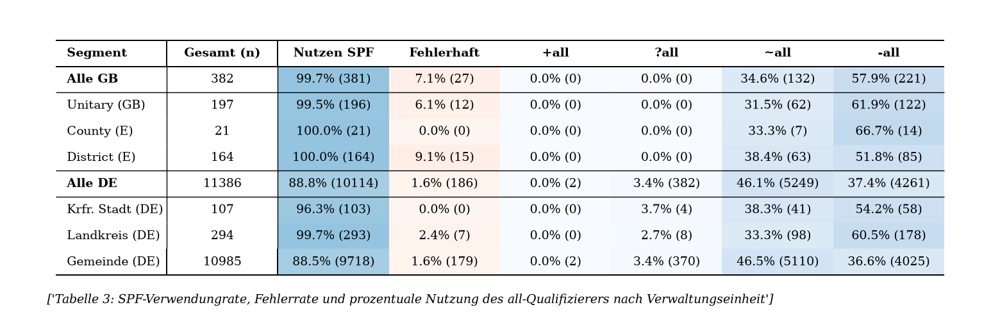

Tabelle erfolgreich gespeichert unter: abbildung_spf_administrative_ebenen.png


In [33]:

metrics_spf = {
    'Nutzen SPF': lambda df: ~df['spfGeneralData_errorType'].fillna('').astype(str).str.startswith("An SPF record does not exist"),
    'Fehlerhaft': lambda df: ((df['spfGeneralData_valid'] == False) & (~df['spfGeneralData_errorType'].fillna('').astype(str).str.startswith("An SPF record does not exist"))
                             & (~df['spfGeneralData_errorType'].fillna('').astype(str).str.contains("The resolution lifetime expired after"))
                              & ( ~df['spfGeneralData_errorType'].fillna('').astype(str).str.contains("All nameservers failed to answer"))  
                             ),
 #   'Warnungen': lambda df: (
 #       (df['spfGeneralData_valid'] == True) & 
 #       (df['spfGeneralData_warnings'].notna()) & 
 #       (df['spfGeneralData_warnings'].astype(str).str.strip() != '') & 
 #       (df['spfGeneralData_warnings'].astype(str).str.strip() != '[]')
 #   ),
    '+all': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'pass')),
    '?all': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'neutral')),
    '~all': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'softfail')),
    '-all': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'fail'))
}

# Berechnung über die vorherige Funktion:
tbl_tiers = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_spf
)

# Zeile 4 ist 'District (E)' -> hier wird die Trennlinie zu 'Alle DE' gezogen:
render_table_to_image(
    tbl_tiers,
    filename="abbildung_spf_administrative_ebenen.png",
    divider_rows=[1,4,5],  # Trennstrich nach District (E)
    dpi=800,
    caption= ["Tabelle 3: SPF-Verwendungrate, Fehlerrate und prozentuale Nutzung des all-Qualifizierers nach Verwaltungseinheit"],
    caption_pos = 0.05
)

In [ ]:
# 2. Tabelle für DE (Flächenländer) + GB (Nationen) generieren
tbl_laender_gb = generate_region_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_spf,
    exclude_city_states=True,  # Filtert Berlin, Hamburg, Bremen heraus
    add_totals=True  
)

# 3. Als hochauflösendes Heatmap-Bild speichern
render_table_to_image(tbl_laender_gb, "tabelle_spf_region.png", dpi=800 ,
    caption= ["Tabelle 4: SPF-Verwendungrate, Fehlerrate und prozentuale Nutzung des all-Qualifizierers nach Region"],caption_pos = 0.05)

In [ ]:
tbl_multi = generate_region_summary_all(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_spf,
    as_multiindex=True,
    
)
render_table_to_image(tbl_multi, "tabelle_multi.png", dpi=800)


### SPF ExternalDependency

### Deutschland

In [34]:
import pandas as pd
from typing import List, Optional, Callable, Union


In [35]:
#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
df_de_external = pd.read_csv('security/data/de/external_dependencies..csv', sep=';', low_memory=False)

top_spfA_cc = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfA',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfA_cc)


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_spfMx_cc = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfMx',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfMx_cc)


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_spfInclude_cc = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfInclude',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfInclude_cc)

#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_spfRedirect_cname = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfRedirect',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfRedirect_cname)

                     domain  Anzahl (n) Anteil (%)
0              cm-system.de          77       8.2%
1                geocms.net          34       3.6%
2  ferienprogramm-online.de          31       3.3%
3     t-systems-service.com          28       3.0%
4          managed-otrs.com          26       2.8%
5                    Gesamt         938     100.0%
                      domain  Anzahl (n) Anteil (%)
0             indivsurvey.de           6      15.8%
1  dingelstaedt-eichsfeld.de           5      13.2%
2                  amt-ks.de           4      10.5%
3           mail-redirect.de           2       5.3%
4                   iacd.net           2       5.3%
5                     Gesamt          38     100.0%
        domain  Anzahl (n) Anteil (%)
0    ionos.com         937      12.0%
1     kvnbw.de         835      10.7%
2  outlook.com         686       8.8%
3    bayern.de         360       4.6%
4    ekom21.de         348       4.4%
5       Gesamt        7832     100.0%
            d

## Externe Abhängigkeiten GB

In [36]:
#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
df_de_external = pd.read_csv('security/data/gb/external_dependencies..csv', sep=';', low_memory=False)

top_spfA_cc_gb = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfA',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfA_cc_gb)


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_spfMx_cc_gb = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfMx',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfMx_cc_gb)


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_spfInclude_cc_gb = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfInclude',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfInclude_cc_gb)

#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_spfRedirect_cname = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'spfRedirect',
    unique_filter_col=['code'],
    pct_base_col = "code"
    #additional_cols=['ipCountryCode']
)
print(top_spfRedirect_cname)

             domain  Anzahl (n) Anteil (%)
0   rocktimeweb.net           3       9.4%
1  civicaepay.co.uk           2       6.2%
2    clearswift.net           2       6.2%
3       outlook.com           2       6.2%
4   midlandhr.co.uk           2       6.2%
5            Gesamt          32     100.0%
   domain  Anzahl (n) Anteil (%)
0  Gesamt           0     100.0%
         domain  Anzahl (n) Anteil (%)
0   outlook.com         146      45.1%
1  mimecast.com          24       7.4%
2      mcsv.net          11       3.4%
3   ondmarc.com          10       3.1%
4   mailjet.com           7       2.2%
5        Gesamt         324     100.0%
           domain  Anzahl (n) Anteil (%)
0      sdmarc.net           5      45.5%
1          mim.ec           4      36.4%
2  spf-report.com           2      18.2%
3          Gesamt          11     100.0%


## SPF Fehler

In [9]:
import pandas as pd

# 1. Daten mit extremen Unterschieden erstellen
import pandas as pd

# 1. Daten erstellen
daten = {
    'Fehlertyp (GB)': ['Lookup-Limit', 'Include-Fehler', 'Syntax Error', 'Sonstige'],
    'Anzahl (GB)': [15, 11, 1, 0],
    'Fehlertyp (DE)': ['Include-Fehler', 'Lookup-Limit', 'Mehrere SPF', 'Sonstige'], 
    'Anzahl (DE)': [85, 53, 24, 24]
}
df_l = pd.DataFrame(daten)

# 2. Summen berechnen
summe_gb = df_l['Anzahl (GB)'].sum()
summe_de = df_l['Anzahl (DE)'].sum()

# 3. Summenzeile hinzufügen (Genau 4 Werte für 4 Spalten!)
df_l.loc[len(df_l)] = ['Summe (GB)', summe_gb, 'Summe (DE)', summe_de]

df_l

,Fehlertyp (GB),Anzahl (GB),Fehlertyp (DE),Anzahl (DE)
0,Lookup-Limit,15,Include-Fehler,85
1,Include-Fehler,11,Lookup-Limit,53
2,Syntax Error,1,Mehrere SPF,24
3,Sonstige,0,Sonstige,24
4,Summe (GB),27,Summe (DE),186


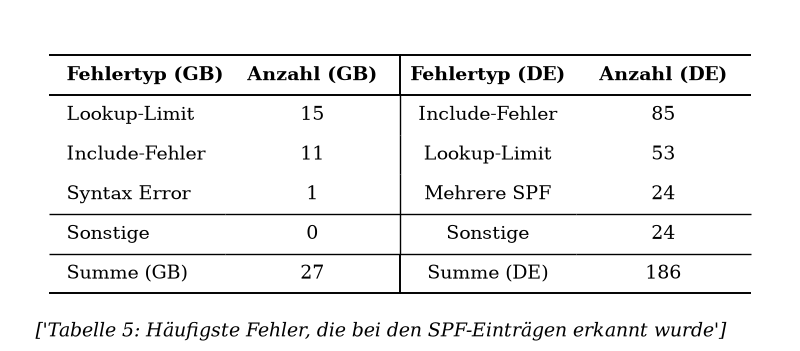

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_policy_administrative_ebenen.png


In [10]:
# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    df_l,
    filename="abbildung_dmarc_policy_administrative_ebenen.png",
    divider_rows=[3,4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    divider_cols=[1],
    row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den SPF-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "Fehlertyp (DE)","Fehlertyp (GB)"],
    hide_index = True
    

)

## DMARC Klassen

In [11]:


import pandas as pd


def get_dmarc_masks(df: pd.DataFrame) -> dict[str, pd.Series]:
    """Bereitet DMARC-Tags auf und liefert atomare, sauber typisierte Masken

    für die Stufen A1 bis A4 (mece: überschneidungsfrei und vollständig).
    """
    # 1. Grundlegende Validität
    has_policy = df["generalDMARCData_hasPolicy"] == True
    has_error = df["generalDMARCData_errorType"].notna()
    is_valid = has_policy & ~has_error

    # Relevante Tags normalisieren
    p = df["dmarcTagValues_p"].fillna("").astype(str).str.lower()
    # Falls sp/np nicht explizit gesetzt sind, erben sie im DMARC-Standard den Wert von p
    sp = df["dmarcTagValues_sp"].fillna(p).astype(str).str.lower()
    # NEU: np-Tag
    np_tag = df["dmarcTagValues_np"].fillna(sp).astype(str).str.lower()

    # pct numerisch parsen (RFC-Standard: fehlt pct, gilt 100 %)
    pct = pd.to_numeric(df["dmarcTagValues_pct"], errors="coerce").fillna(100)

    # NEU: Test-Modus t=y
    t = df["dmarcTagValues_t"].fillna("n").astype(str).str.lower()
    is_testing = t.isin(["y"])


    has_none = (p == "none") | (sp == "none") | (np_tag == "none")
    is_full_reject = (p == "reject") & (sp == "reject") & (np_tag == "reject")
    is_quarantine_level = ~has_none & ~is_full_reject


    #4: reject auf jeder Ebene
    req_4 = is_valid & is_full_reject & (pct == 100) & ~is_testing

    #3: Voll-Quarantäne (pct=100, t=n) ODER Teil-Reject (reject mit pct < 100 oder t=y)
    req_3 = is_valid & (
        (is_quarantine_level & (pct == 100) & ~is_testing)
        | (is_full_reject & ((pct < 100) | is_testing) & (pct >= 0))
    )

    #2: Teil-Quarantäne (Quarantäne mit 0 < pct < 100 und t=n)
    req_2 = (
        is_valid & is_quarantine_level & (pct > 0) & (pct < 100) & ~is_testing
    )

    #1: Reines Monitoring (p/sp/np auf none ODER p/sp/np auf reject/quar, aber pct=0 bzw. t=y)
    req_1 = is_valid & (
        has_none
        | ((is_quarantine_level) & ((pct == 0) | is_testing))
    )

    rpt_count = (
    pd.to_numeric(df["aggDmarcReportingData_reportDomainCount"], errors="coerce")
    .fillna(0)
    .astype(int)
    )

    req_a = is_valid & (rpt_count == 0)
    req_b = is_valid & (rpt_count > 0)
    return {
        "Nutzen DMARC": has_policy,
        "Fehlerhaft": has_error,
        "1A": req_1 & req_a,
        "1B" : req_1 & req_b,
        "2A" : req_2 & req_a,
        "2B": req_2 & req_b,
        "3A": req_3 & req_a,
        "3B": req_3 & req_b,
        "4A" : req_4 & req_a,
        "4B": req_4 & req_b
    }

## DMARC Verbreitung und Policy

In [12]:
metrics_dmarc_policy = {
    "Use DMARC": lambda df: get_dmarc_masks(df)["Nutzen DMARC"],
    "invalid": lambda df: get_dmarc_masks(df)["Fehlerhaft"],
    "1 (none)": lambda df: (get_dmarc_masks(df)["1A"] | get_dmarc_masks(df)["1B"]),
    "2 (partly qua.)": lambda df:( get_dmarc_masks(df)["2A"] | get_dmarc_masks(df)["2B"]),
    "3 (min. qua.)": lambda df: (get_dmarc_masks(df)["3A"] | get_dmarc_masks(df)["3B"]),
    "4 (min. reject)": lambda df: (get_dmarc_masks(df)["4A"] | get_dmarc_masks(df)["4B"])
}



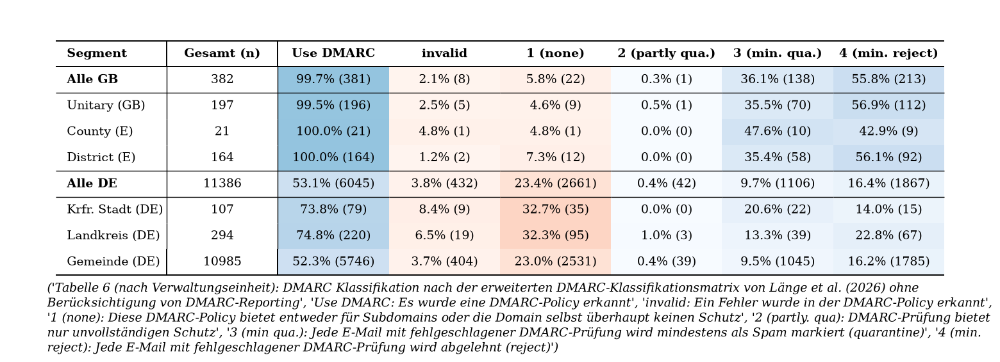

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_policy_administrative_ebenen.png


In [13]:
# 1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dmarc_policy = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc_policy,
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dmarc_policy,
    filename="abbildung_dmarc_policy_administrative_ebenen.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
            caption = ("Tabelle 6 (nach Verwaltungseinheit): DMARC Klassifikation nach der erweiterten DMARC-Klassifikationsmatrix von Länge et al. (2026) ohne Berücksichtigung von DMARC-Reporting",
                       "Use DMARC: Es wurde eine DMARC-Policy erkannt",
                       "invalid: Ein Fehler wurde in der DMARC-Policy erkannt",
                       "1 (none): Diese DMARC-Policy bietet entweder für Subdomains oder die Domain selbst überhaupt keinen Schutz",
                       "2 (partly. qua): DMARC-Prüfung bietet nur unvollständigen Schutz",
                       "3 (min qua.): Jede E-Mail mit fehlgeschlagener DMARC-Prüfung wird mindestens als Spam markiert (quarantine)",
                       "4 (min. reject): Jede E-Mail mit fehlgeschlagener DMARC-Prüfung wird abgelehnt (reject)"

                      )
        ,
    caption_pos = -0.1,
    red_keywords= ["invalid","1 (none)"]
)


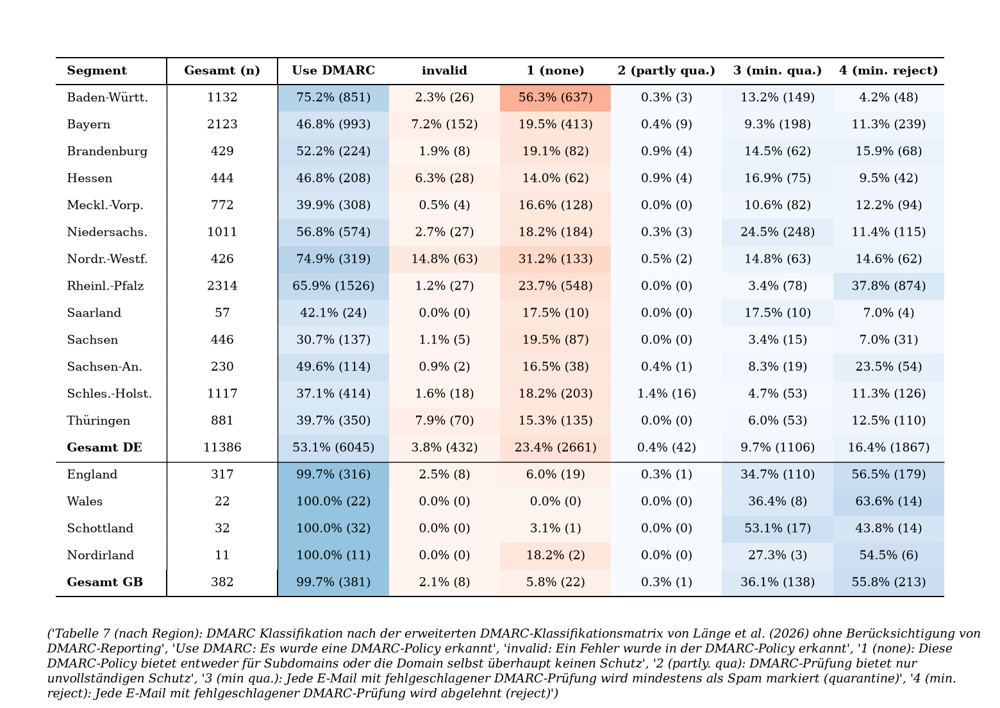

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_policy_administrative_ebenen.png


In [14]:
# 1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dmarc_policy_region = generate_region_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc_policy,
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dmarc_policy_region,
    filename="abbildung_dmarc_policy_administrative_ebenen.png",
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
            caption = ("Tabelle 7 (nach Region): DMARC Klassifikation nach der erweiterten DMARC-Klassifikationsmatrix von Länge et al. (2026) ohne Berücksichtigung von DMARC-Reporting",
                       "Use DMARC: Es wurde eine DMARC-Policy erkannt",
                       "invalid: Ein Fehler wurde in der DMARC-Policy erkannt",
                       "1 (none): Diese DMARC-Policy bietet entweder für Subdomains oder die Domain selbst überhaupt keinen Schutz",
                       "2 (partly. qua): DMARC-Prüfung bietet nur unvollständigen Schutz",
                       "3 (min qua.): Jede E-Mail mit fehlgeschlagener DMARC-Prüfung wird mindestens als Spam markiert (quarantine)",
                       "4 (min. reject): Jede E-Mail mit fehlgeschlagener DMARC-Prüfung wird abgelehnt (reject)"

                      )
    ,
    caption_pos = -0.06,
    red_keywords= ["invalid","1 (none)"]
)


## DMARC-Reporting

In [15]:


def get_valid_dmarc_base(df: pd.DataFrame) -> pd.Series:
    """Basis-Bedingung: Hat DMARC-Policy und keinen Fehler."""
    return (df["generalDMARCData_hasPolicy"] == True) & (
        df["generalDMARCData_errorType"].isna()
    )


metrics_dmarc_report = {
    "Use DMARC": lambda df: df["generalDMARCData_hasPolicy"] == True,
    "Use Reporting": lambda df: (
        get_valid_dmarc_base(df)
        & (df["aggDmarcReportingData_reportDomainCount"] > 0)
    ),
    "InternalOnly": lambda df: (
        get_valid_dmarc_base(df)
        & (df["aggDmarcReportingData_reportDomainCount"] > 0)
        & (df["aggDmarcReportingData_externalDomainCount"].fillna(0) == 0)
    ),
    "External": lambda df: (
        get_valid_dmarc_base(df)
        & (df["aggDmarcReportingData_externalDomainCount"] > 0)
    ),
    "RuaUndRuf": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_rua"] == True)
        & (df["dmarcTagValueExplicit_ruf"] == True)
    ),
    "RuaOnly": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_rua"] == True)
        & (df["dmarcTagValueExplicit_ruf"].isna())
    ),
    "RufOnly": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_rua"].isna())
        & (df["dmarcTagValueExplicit_ruf"] == True)
    ),
}

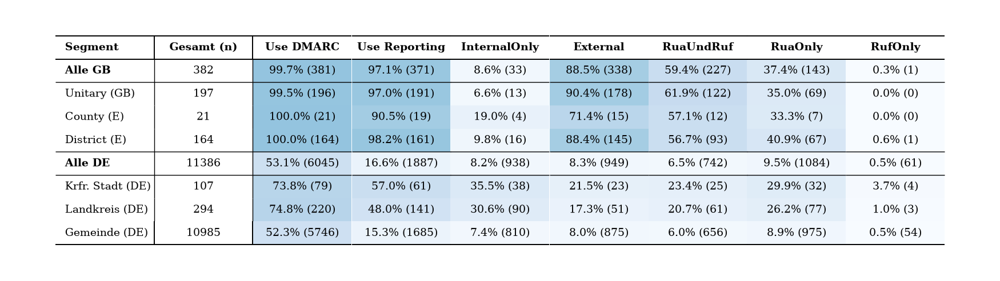

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_report_administrative_ebenen.png


In [16]:
# 1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dmarc_report = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc_report,
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dmarc_report,
    filename="abbildung_dmarc_report_administrative_ebenen.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

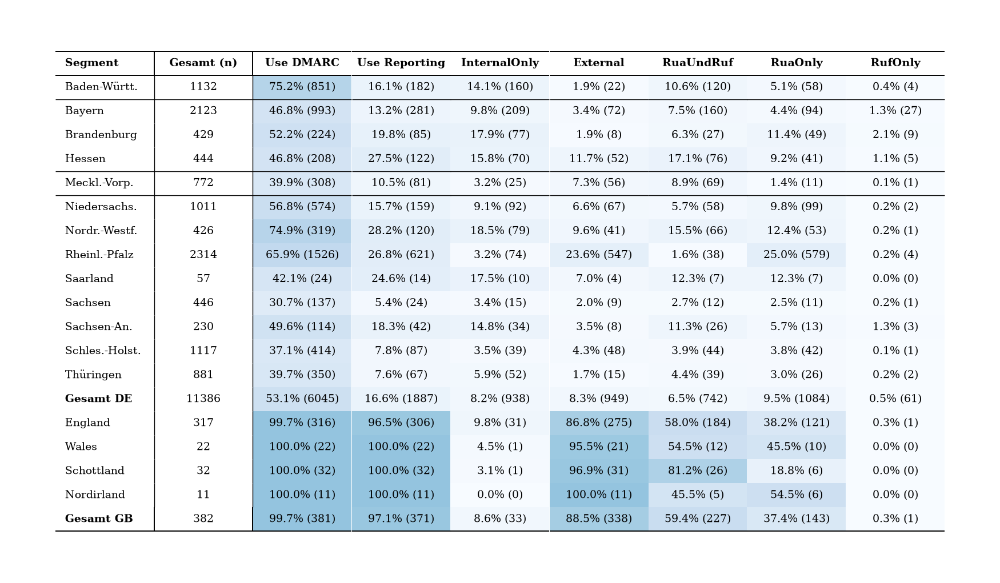

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_report_regional.png


In [17]:

tbl_region_dmarc_report = generate_region_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc_report,
)


render_table_to_image(
    tbl_region_dmarc_report,
    filename="abbildung_dmarc_report_regional.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

## Kombination DMARC-Reporting und Policy

In [18]:
metrics_dmarc = {
    "Nutzen DMARC": lambda df: get_dmarc_masks(df)["Nutzen DMARC"],
    "invalid": lambda df: get_dmarc_masks(df)["Fehlerhaft"],
    "1A": lambda df: get_dmarc_masks(df)["1A"],
    "1B": lambda df: get_dmarc_masks(df)["1B"],
    "2A": lambda df: get_dmarc_masks(df)["2A"],
    "2B": lambda df: get_dmarc_masks(df)["2B"],
    "3A": lambda df: get_dmarc_masks(df)["3A"],
    "3B": lambda df: get_dmarc_masks(df)["3B"],
    "4A": lambda df: get_dmarc_masks(df)["4A"],
    "4B": lambda df: get_dmarc_masks(df)["4B"]
}


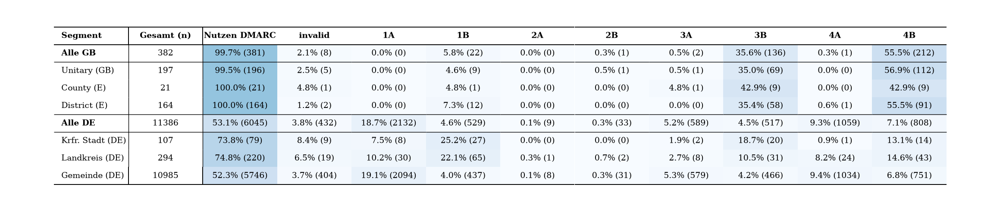

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_administrative_ebenen.png


In [19]:
# 1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dmarc = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc,
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dmarc,
    filename="abbildung_dmarc_administrative_ebenen.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

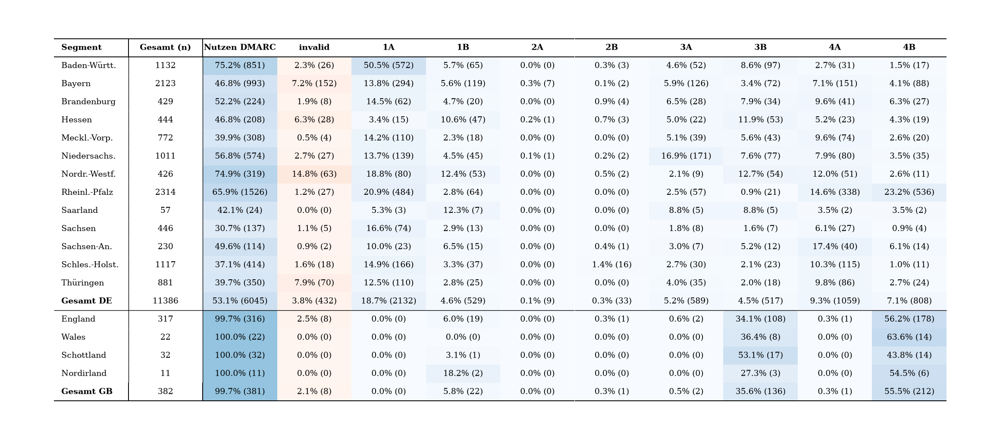

Tabelle erfolgreich gespeichert unter: tabelle_laender_und_gb_dmarc.png


In [20]:
# 2. Tabelle für DE (Flächenländer) + GB (Nationen) generieren
tbl_laender_dmarc = generate_region_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc,
    exclude_city_states=True,  # Filtert Berlin, Hamburg, Bremen heraus
    add_totals=True
)

# 3. Als hochauflösendes Heatmap-Bild speichern
render_table_to_image(tbl_laender_dmarc, "tabelle_laender_und_gb_dmarc.png", dpi=800,            # Erzeugt 'Gesamt DE' und 'Gesamt GB'
    red_keywords= ["invalid"])

In [21]:
tbl_multi_dmarc = generate_region_summary_all(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc,
    as_multiindex=True,
    
)
#render_table_to_image(tbl_multi_dmarc, "tabelle_multi.png", dpi=800)

## Zusammenspiel SPF, DKIM und DMARC

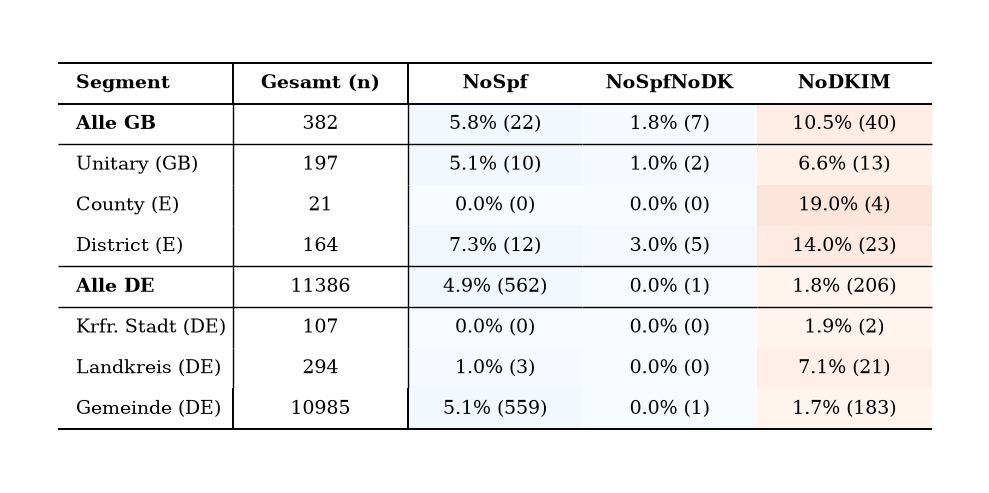

Tabelle erfolgreich gespeichert unter: abbildung_spf_dmarc_dkim_admin_ebenen.png


In [22]:


# DMARC Enforced & Kein SPF
# DMARC ENforced & Kein SPF & DKIM
# Softfail -> DMARC 
# Softfail -> Kein DMARC
# Softfail -> Enforced DMARC
# Neutral & Enforced DMARC


def hasEnforcedDmarc(df):
    return get_dmarc_masks(df)["3A"] | get_dmarc_masks(df)["3B"] | get_dmarc_masks(df)["4A"] | get_dmarc_masks(df)["4B"]

def hasValidDmarc(df):
    return (df["generalDMARCData_hasPolicy"] == True) & (df["generalDMARCData_errorType"].isna())

def hasValidSpf(df):
    return (~df['spfGeneralData_errorType'].fillna('').astype(str).str.startswith("An SPF record does not exist")) & (df['spfGeneralData_valid'] == True)

metrics_spf_dmarc_dkim = {
    'NoSpf': lambda df:( hasEnforcedDmarc(df) & (~hasValidSpf(df))),
    'NoSpfNoDK': lambda df:( hasEnforcedDmarc(df) & (~hasValidSpf(df)) & (df["aggDomainAntiSpoofing_dkimResult"] == "NoDKIM")),
    'NoDKIM': lambda df:( hasEnforcedDmarc(df) & (hasValidSpf(df)) & (df["aggDomainAntiSpoofing_dkimResult"] == "NoDKIM"))
}

# Berechnung über die vorherige Funktion:
tbl_tiers_spf_dmarc_dkim = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_spf_dmarc_dkim,
)

# Zeile 4 ist 'District (E)' -> hier wird die Trennlinie zu 'Alle DE' gezogen:
render_table_to_image(
    tbl_tiers_spf_dmarc_dkim,
    filename="abbildung_spf_dmarc_dkim_admin_ebenen.png",
    divider_rows=[1,4,5],  # Trennstrich nach District (E)
    dpi=800,
)

## SPF Softfail, Neutral, Fail und DMARC

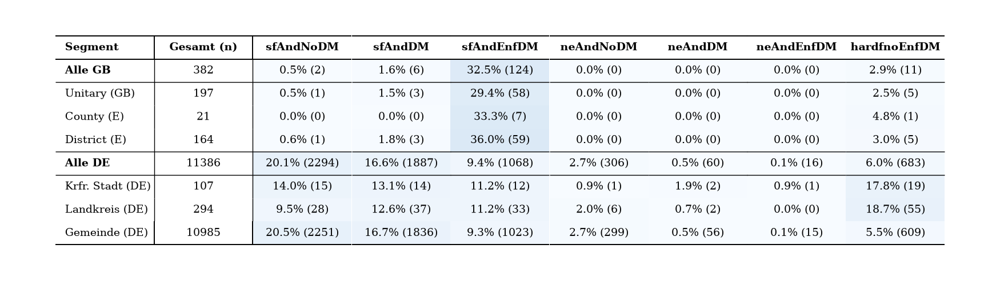

Tabelle erfolgreich gespeichert unter: abbildung_spf_dmarc_admin_ebenen.png


In [23]:
metrics_spf_dmarc = {
    'sfAndNoDM': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'softfail') & (~hasValidDmarc(df))),
    'sfAndDM': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'softfail') & hasValidDmarc(df) & (~hasEnforcedDmarc(df))),
    'sfAndEnfDM': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'softfail') & hasValidDmarc(df) & hasEnforcedDmarc(df)),
    
    'neAndNoDM' : lambda df:( (~hasValidDmarc(df)) & (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'neutral')),
    'neAndDM' : lambda df :(  hasValidDmarc(df) & (~hasEnforcedDmarc(df)) &  (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'neutral')),
    'neAndEnfDM': lambda df:( hasEnforcedDmarc(df) & (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'neutral')),
    
    'hardfnoEnfDM': lambda df: ( (df['spfGeneralData_valid'] == True) & (df['spfGeneralData_allQualifier'] == 'fail') & (~hasEnforcedDmarc(df)) & hasValidDmarc(df) )
}

# Berechnung über die vorherige Funktion:
tbl_tiers_spf_dmarc = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_spf_dmarc,
)

# Zeile 4 ist 'District (E)' -> hier wird die Trennlinie zu 'Alle DE' gezogen:
render_table_to_image(
    tbl_tiers_spf_dmarc,
    filename="abbildung_spf_dmarc_admin_ebenen.png",
    divider_rows=[1,4,5],  # Trennstrich nach District (E)
    dpi=800,
)

## Änderungen durch neues DMARC 

Wie gut gegen neuen DMARC-RFC gewappnet?
- Veraltetet Tags (ri, rf, pct)
- Neue Tags (t, psd, np)
- Org Domain unterschiedlich
- Policy an OrgDomain gefunden
- Strict Policy dkim
- Strict Policy spf
- Strict Policy beides

In [37]:
def get_valid_dmarc_base(df: pd.DataFrame) -> pd.Series:
    """Basis-Bedingung: Hat DMARC-Policy und keinen Fehler."""
    return (df["generalDMARCData_hasPolicy"] == True) & (
        df["generalDMARCData_errorType"].isna()
    )


metrics_dmarc_newdmarc = {
    #"Nutzen DMARC": lambda df: df["generalDMARCData_hasPolicy"] == True,
    #"VeralteteTags": lambda df: (
    #    get_valid_dmarc_base(df)
    #    & ((df["dmarcTagValueExplicit_rf"] == True)  
    #    | (df["dmarcTagValueExplicit_ri"] == True))
    #),
   # "NeueTags": lambda df: (
   #     get_valid_dmarc_base(df)
   #     & ((df["dmarcTagValueExplicit_np"] == True)
   #     | (df["dmarcTagValueExplicit_t"] == True)
   #     | (df["dmarcTagValueExplicit_psd"] == True))
#
   # ),
   # "VeralteteTags": lambda df: (
   #     get_valid_dmarc_base(df)
   #     & ((df["dmarcTagValueExplicit_rf"] == True)  
   #     | (df["dmarcTagValueExplicit_ri"] == True))
   # ),
    "AtOrgDomain": lambda df: (
    get_valid_dmarc_base(df)
    & (
    df["generalDMARCData_policyLocation"] == "OrgDomain")
        
    ),
    "StrictDKIM": lambda df: (
    get_valid_dmarc_base(df)
    & (df["dmarcTagValues_adkim"] == "s")
        
    ),
    "StrictSPF": lambda df: (
   get_valid_dmarc_base(df)
   & (df["dmarcTagValues_aspf"] == "s")
        
    ),
    "StrictAlignment": lambda df: (
    get_valid_dmarc_base(df)
    & (df["dmarcTagValues_aspf"] == "s")
    & (df["dmarcTagValues_adkim"] == "s")
        
    ),
    "DiffLocation": lambda df: (
    get_valid_dmarc_base(df)
    & (
    df["generalDMARCData_policyLocation"] == "OrgDomain")
    & (df["generalDMARCData_oldOrgDomain"].fillna("").astype(str).str.lower()
      != df["generalDMARCData_newOrgDomain"].fillna("").astype(str).str.lower()
      )
    ),
    
    "DiffOrgDomain": lambda df: (
        get_valid_dmarc_base(df)
        & (df["generalDMARCData_oldOrgDomain"].astype(str).str.lower()
          != df["generalDMARCData_newOrgDomain"].astype(str).str.lower()
          ) 
        & ( 
        (df["dmarcTagValues_aspf"] == "r")
        | 
        (df["dmarcTagValues_adkim"] == "r")
        )
    )



}


base_filter_newdmarc = lambda df: (get_valid_dmarc_base(df))

In [ ]:
# 1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dmarc_newdmarc = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc_newdmarc,
    base_filter=base_filter_newdmarc
)



# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dmarc_newdmarc,
    filename="abbildung_dmarc_admin_neuesdmarc.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

## DMARC-Tags

In [ ]:
metrics_dmarc_newdmarc_tags = {
    "pct (alt)": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_pct"] == True)  
        
    )
    ,
    "ri (alt)": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_ri"] == True)

    )
    ,
    "rf (alt)": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_rf"] == True)
        
    )
    ,
    "np (neu)": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_np"] == True)
    )
    ,
    "t (neu)": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_t"] == True)
    )
    ,
    "psd (neu)": lambda df: (
        get_valid_dmarc_base(df)
        & (df["dmarcTagValueExplicit_psd"] == True)
    )      
}     

In [ ]:

# 1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dmarc_newdmarc_tags = generate_tier_summary(
    df_gb="security/data/gb/antispoofing_data.csv",
    df_de="security/data/de/antispoofing_data.csv",
    metrics=metrics_dmarc_newdmarc_tags,
    base_filter=base_filter_newdmarc
)



# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dmarc_newdmarc_tags,
    filename="abbildung_dmarc_admin_neuesdmarc_tags.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

## Fehler DMARC

In [38]:
df_de = pd.read_csv('security/data/de/antispoofing_data.csv', sep=';', low_memory=False)


top_dmarc_error_de = get_top_frequencies(
    df=df_de,
    target_col="generalDMARCData_errorType",
    top_n=3,
    row_filter=lambda df: (~df["generalDMARCData_errorType"].isna()),
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code",
    col_name_aliases = { "generalDMARCData_errorType" : "Fehlertyp" },
    value_aliases = {"DMARCAtMainDomainLocation":"DMARCAtMainDomain", "NotValidatedExternalReporting" : "NotValidatedExtReporting"}
)
print(top_dmarc_error_de)



df_gb = pd.read_csv('security/data/gb/antispoofing_data.csv', sep=';', low_memory=False)


top_dmarc_error_gb = get_top_frequencies(
    df=df_gb,
    target_col="generalDMARCData_errorType",
    top_n=3,
    row_filter=lambda df: (~df["generalDMARCData_errorType"].isna()),
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code",
        col_name_aliases = { "generalDMARCData_errorType" : "Fehlertyp" },
    value_aliases = {"DMARCAtMainDomainLocation":"DMARCAtMainDomain", "NotValidatedExternalReporting" : "NotValidatedExtReporting"}
)
print(top_dmarc_error_gb)




                  Fehlertyp  Anzahl (n) Anteil (%)
0  NotValidatedExtReporting         323      74.8%
1         DMARCAtMainDomain          59      13.7%
2               SyntaxError          45      10.4%
3                    Gesamt         432     100.0%
                  Fehlertyp  Anzahl (n) Anteil (%)
0  NotValidatedExtReporting           4      50.0%
1               SyntaxError           2      25.0%
2         DMARCAtMainDomain           1      12.5%
3                    Gesamt           8     100.0%


In [ ]:
top_dmarc_error_gb_pre = top_dmarc_error_gb.add_prefix('GB ')
top_dmarc_error_de_pre = top_dmarc_error_de.add_prefix('DE ')


# Danach sicher zusammenfügen (ohne df1 zu überschreiben)
#ergebnis = df1.copy()
#ergebnis[df2_sicher.columns] = df2_sicher.to_numpy()
top_dmarc_error_degb = top_dmarc_error_de_pre.copy()
#df1[df2.columns] = df2.to_numpy()
top_dmarc_error_degb[top_dmarc_error_gb_pre.columns] = top_dmarc_error_gb_pre.to_numpy()

#top_dmarc_overview = pd.concat([top_dmarc, top_dmarc_gb], axis=1)
#print(top_dmarc)


ergebnis = render_table_to_image(
    top_dmarc_error_degb,
    filename="abbildung_dmarc_top_5.png",
    divider_rows=[3],  
    dpi=800,
    divider_cols=[2],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den DMARC-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    #value_aliases = ["NotValidatedExtReporting" : "
    hide_index = True,
    font_size = 9,
    bold_rows = [3]

)

## Externe DMARC Abhängigkeiten DMARC 

### Deutschalnd

In [120]:


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
df_de_external = pd.read_csv('security/data/de/external_dependencies..csv', sep=';', low_memory=False)

top_dmarc = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalDMARCReportDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode'],
    pct_base_col = "code"
)
print(top_dmarc)


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_dmarc_cc = get_top_frequencies(
    df=df_de_external,
    target_col='ipCountryCode',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalDMARCReportDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_dmarc_cc)


#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_dmarc_cname = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'cnameDmarcPolicy'#,
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_dmarc_cname)

            domain  Anzahl (n) Anteil (%) ipCountryCode
0           rlp.de         518      54.6%            DE
1        brevo.com          60       6.3%            FR
2     agari-eu.com          41       4.3%            US
3        ekom21.de          41       4.3%            DE
4  postmarkapp.com          30       3.2%            US
5           Gesamt         949     100.0%              
  ipCountryCode  Anzahl (n) Anteil (%)
0            DE         719      75.4%
1            US         160      16.8%
2            FR          62       6.5%
3            NL          13       1.4%
4        Gesamt         954     100.0%
                    domain  Anzahl (n) Anteil (%)
0                 ionos.de         799      90.0%
1                agari.com          37       4.2%
2              neustadt.de          23       2.6%
3          hornetdmarc.com           7       0.8%
4  services-kommunalbit.de           7       0.8%
5                   Gesamt         888     100.0%


### GB

In [121]:
#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
df_gb_external = pd.read_csv('security/data/gb/external_dependencies..csv', sep=';', low_memory=False)

top_dmarc_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalDMARCReportDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode'],
    pct_base_col = "code"
)
print(top_dmarc_gb)


top_dmarc_cc_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='ipCountryCode',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalDMARCReportDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_dmarc_cc_gb)


top_dmarc_cname_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'cnameDmarcPolicy'#,
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_dmarc_cname_gb)

                 domain  Anzahl (n) Anteil (%) ipCountryCode
0  dmarc.service.gov.uk         223      66.0%            US
1            vali.email          38      11.2%            US
2           ncsc.gov.uk          36      10.7%            US
3       postmarkapp.com          22       6.5%            US
4     dmarcanalyzer.com          21       6.2%            US
5                Gesamt         338     100.0%              
  ipCountryCode  Anzahl (n) Anteil (%)
0            US         436      95.2%
1            NL          14       3.1%
2            ZA           6       1.3%
3            DE           1       0.2%
4            GB           1       0.2%
5        Gesamt         458     100.0%
            domain  Anzahl (n) Anteil (%)
0       sdmarc.net           6      35.3%
1    easydmarc.pro           4      23.5%
2    dmarc-dns.com           3      17.6%
3      ondmarc.com           2      11.8%
4  sophosdmarc.net           1       5.9%
5           Gesamt          17     100.0%


949
888


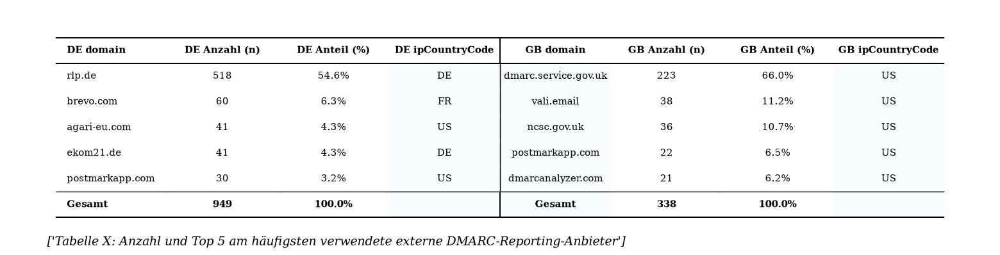

Tabelle erfolgreich gespeichert unter: abbildung_dmarc_top_5.png


In [122]:
anzahl_kommunen_dmarc_report = df_de_external.loc[df_de_external['dependencyType'] == 'externalDMARCReportDomain', 'code'].nunique()
print(anzahl_kommunen_dmarc_report)




anzahl_kommunen_dmarc_cname = df_de_external.loc[df_de_external['dependencyType'] == 'cnameDmarcPolicy', 'code'].nunique()
print(anzahl_kommunen_dmarc_cname)

top_dmarc_gb_gb = top_dmarc_gb.add_prefix('GB ')
top_dmarc_de = top_dmarc.add_prefix('DE ')


# Danach sicher zusammenfügen (ohne df1 zu überschreiben)
#ergebnis = df1.copy()
#ergebnis[df2_sicher.columns] = df2_sicher.to_numpy()
top_dmarc_degb = top_dmarc_de.copy()
#df1[df2.columns] = df2.to_numpy()
top_dmarc_degb[top_dmarc_gb_gb.columns] = top_dmarc_gb_gb.to_numpy()

#top_dmarc_overview = pd.concat([top_dmarc, top_dmarc_gb], axis=1)
#print(top_dmarc)


render_table_to_image(
    top_dmarc_degb,
    filename="abbildung_dmarc_top_5.png",
    divider_rows=[5],  
    dpi=800,
    divider_cols=[3],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle X: Anzahl und Top 5 am häufigsten verwendete externe DMARC-Reporting-Anbieter"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil"],
    hide_index = True,
    font_size = 11,
    bold_rows = [5]

)

# Top-Externe Abhängigkeiten

In [123]:

ergebnis = (
    df_de_external.groupby('dependencyType')['code']
    .nunique()
    .reset_index(name='anzahl_kommunen')
    .sort_values(by='anzahl_kommunen', ascending=False)
)

print(ergebnis)

ausblenden = ['cnameDmarcPolicy', 'cnameTLSRPTDnsRecord']

# Variante A: Per Lambda-Funktion (flexibel bei Listen)
ergebnis = get_top_frequencies(
    df=df_de_external,
    target_col='dependencyType',
    row_filter=lambda d: ~d['dependencyType'].isin(ausblenden),
    unique_filter_col=['code', 'dependencyType'],
    pct_base_col='code',
    top_n=None
)

print(ergebnis)

               dependencyType  anzahl_kommunen
7            externalMxDomain             9625
0                        CAMX             9505
10                 spfInclude             7832
6   externalDMARCReportDomain              949
9                        spfA              938
2            cnameDmarcPolicy              888
12                spfRedirect              137
1                 CASTSPolicy               57
11                      spfMx               38
8     externalTlsReportDomain               31
3           cnameMTASTSPolicy               18
4        cnameMtaStsDnsRecord               14
5        cnameTLSRPTDnsRecord               10
               dependencyType  Anzahl (n) Anteil (%)
0            externalMxDomain        9625      88.7%
1                        CAMX        9505      87.6%
2                  spfInclude        7832      72.2%
3   externalDMARCReportDomain         949       8.7%
4                        spfA         938       8.6%
5                 spfRed

In [124]:
anzahl_kommunen_dmarc_report = df_gb_external.loc[df_gb_external['dependencyType'] == 'externalDMARCReportDomain', 'code'].nunique()
print(anzahl_kommunen_dmarc_report)


anzahl_kommunen_dmarc_cname = df_gb_external.loc[df_gb_external['dependencyType'] == 'cnameDmarcPolicy', 'code'].nunique()
print(anzahl_kommunen_dmarc_cname)


ergebnis = (
    df_gb_external.groupby('dependencyType')['code']
    .nunique()
    .reset_index(name='anzahl_kommunen')
    .sort_values(by='anzahl_kommunen', ascending=False)
)

print(ergebnis)



ausblenden_gb = ['cnameDmarcPolicy', 'cnameTLSRPTDnsRecord']

# Variante A: Per Lambda-Funktion (flexibel bei Listen)
ergebnis_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='dependencyType',
    row_filter=lambda d: ~d['dependencyType'].isin(ausblenden_gb),
    unique_filter_col=['code', 'dependencyType'],
    pct_base_col='code',
    top_n=None
)

print(ergebnis_gb)

338
17
               dependencyType  anzahl_kommunen
0                        CAMX              380
7            externalMxDomain              358
6   externalDMARCReportDomain              338
10                 spfInclude              324
1                 CASTSPolicy              161
3           cnameMTASTSPolicy               85
8     externalTlsReportDomain               40
9                        spfA               32
2            cnameDmarcPolicy               17
4        cnameMtaStsDnsRecord               17
11                spfRedirect               11
5        cnameTLSRPTDnsRecord               10
               dependencyType  Anzahl (n) Anteil (%)
0                        CAMX         380      99.5%
1            externalMxDomain         358      93.7%
2   externalDMARCReportDomain         338      88.5%
3                  spfInclude         324      84.8%
4                 CASTSPolicy         161      42.1%
5           cnameMTASTSPolicy          85      22.3%
6     exter

## Kombination Externe Abhängigkeiten

## Berechnung Kombinationen GB

In [125]:
df_gb_external = df_gb_external.copy()

ausblenden = ['cnameDmarcPolicy', 'cnameTLSRPTDnsRecord']

df_gb_erweitert = df_gb_external.copy()

df_gb_filtered = df_gb_erweitert[~df_gb_erweitert['dependencyType'].isin(ausblenden)]


# 1. Anzahl unterschiedlicher Abhängigkeitstypen pro Kommune (code)
anzahl_pro_kommune = df_gb_filtered.groupby('code')['dependencyType'].nunique()
#print(df_erweitert[['code','anzahl_typen']])
# 2. Alphabetisch sortierte Kombination eindeutiger Typen pro Kommune
kombis_pro_kommune = (
    df_gb_filtered.groupby('code')['dependencyType']
    .apply(lambda s: ' + '.join(sorted(s.dropna().unique())))
)

# Zurück auf das gesamte DataFrame mappen (Kommunen, die nur die 2 ausgeblendeten Typen hatten, erhalten 0 bzw. 'Keine')
df_gb_filtered['anzahl_typen'] = df_gb_filtered['code'].map(anzahl_pro_kommune).fillna(0).astype(int)
df_gb_filtered['kombination'] = df_gb_filtered['code'].map(kombis_pro_kommune).fillna('Keine')

pd.set_option('display.max_rows', None)
#pd.set_option('display.max_rows', 100)
#display(df_gb_filtered[['code','anzahl_typen','kombination']].style.set_properties(subset=['kombination'], **{'min-width': '250px'}))


anzahl_verteilung_gb = get_top_frequencies(
    df=df_gb_filtered,
    target_col='anzahl_typen',
    unique_filter_col='code',
    top_n=None  # Alle Ausprägungen anzeigen (oder row_filter="anzahl_typen in [3, 4, 5]")
)
display(anzahl_verteilung_gb)



,anzahl_typen,Anzahl (n),Anteil (%)
0,4,164,42.9%
1,5,65,17.0%
2,3,58,15.2%
3,6,57,14.9%
4,7,19,5.0%
5,8,13,3.4%
6,2,6,1.6%
7,Gesamt,382,100.0%


In [126]:
top_kombinationen_gb_external = get_top_frequencies(
    df=df_gb_filtered,
    target_col='kombination',
    row_filter="anzahl_typen > 0",  # Optional: Weglassen für alle Anzahlen
    unique_filter_col='code',
    additional_cols=['anzahl_typen'],        # Zeigt die Anzahl der Typen als Zusatzspalte an
   # keep_total_basis=True,                   # Basis bleibt bei allen 382 Kommunen
    top_n=10
)


display(top_kombinationen_gb_external.style.set_properties(subset=['kombination'], **{'min-width': '250px'}))







,kombination,Anzahl (n),Anteil (%),anzahl_typen
0,CAMX + externalDMARCReportDomain + externalMxDomain + spfInclude,128,33.5%,4
1,CAMX + CASTSPolicy + cnameMTASTSPolicy + externalDMARCReportDomain + externalMxDomain + spfInclude,40,10.5%,6
2,CAMX + CASTSPolicy + externalDMARCReportDomain + externalMxDomain + spfInclude,34,8.9%,5
3,CAMX + externalDMARCReportDomain + externalMxDomain,27,7.1%,3
4,CAMX + externalMxDomain + spfInclude,21,5.5%,3
5,CAMX + externalDMARCReportDomain + externalMxDomain + spfA + spfInclude,13,3.4%,5
6,CAMX + CASTSPolicy + externalDMARCReportDomain + externalMxDomain,11,2.9%,4
7,CAMX + CASTSPolicy + externalMxDomain + spfInclude,11,2.9%,4
8,CAMX + externalDMARCReportDomain + spfInclude,9,2.4%,3
9,CAMX + CASTSPolicy + cnameMTASTSPolicy + externalDMARCReportDomain + externalMxDomain + externalTlsReportDomain + spfInclude,9,2.4%,7


## Berechnung Kobinationen DE

In [127]:
df_de_external = df_de_external.copy()

ausblenden = ['cnameDmarcPolicy', 'cnameTLSRPTDnsRecord']

df_de_erweitert = df_de_external.copy()

df_de_filtered = df_de_erweitert[~df_de_erweitert['dependencyType'].isin(ausblenden)]


# 1. Anzahl unterschiedlicher Abhängigkeitstypen pro Kommune (code)
anzahl_pro_kommune = df_de_filtered.groupby('code')['dependencyType'].nunique()
#print(df_erweitert[['code','anzahl_typen']])
# 2. Alphabetisch sortierte Kombination eindeutiger Typen pro Kommune
kombis_pro_kommune = (
    df_de_filtered.groupby('code')['dependencyType']
    .apply(lambda s: ' + '.join(sorted(s.dropna().unique())))
)

# Zurück auf das gesamte DataFrame mappen (Kommunen, die nur die 2 ausgeblendeten Typen hatten, erhalten 0 bzw. 'Keine')
df_de_filtered['anzahl_typen'] = df_de_filtered['code'].map(anzahl_pro_kommune).fillna(0).astype(int)
df_de_filtered['kombination'] = df_de_filtered['code'].map(kombis_pro_kommune).fillna('Keine')

pd.set_option('display.max_rows', None)
#pd.set_option('display.max_rows', 100)
#display(df_de_filtered[['code','anzahl_typen','kombination']].style.set_properties(subset=['kombination'], **{'min-width': '250px'}))


anzahl_verteilung_de = get_top_frequencies(
    df=df_de_filtered,
    target_col='anzahl_typen',
    unique_filter_col='code',
    top_n=None  # Alle Ausprägungen anzeigen (oder row_filter="anzahl_typen in [3, 4, 5]")
)
display(anzahl_verteilung_de)


,anzahl_typen,Anzahl (n),Anteil (%)
0,3,6092,56.2%
1,2,2761,25.5%
2,4,1025,9.4%
3,1,910,8.4%
4,5,42,0.4%
5,8,8,0.1%
6,6,8,0.1%
7,7,2,0.0%
8,Gesamt,10848,100.0%


In [128]:
top_kombinationen_de_external = get_top_frequencies(
    df=df_de_filtered,
    target_col='kombination',
    row_filter="anzahl_typen > 0 ",  # Optional: Weglassen für alle Anzahlen
    unique_filter_col='code',
    additional_cols=['anzahl_typen'],        # Zeigt die Anzahl der Typen als Zusatzspalte an
   # keep_total_basis=True,                   # Basis bleibt bei allen 382 Kommunen
    top_n=10
)


display(top_kombinationen_de_external.style.set_properties(subset=['kombination'], **{'min-width': '250px'}))




,kombination,Anzahl (n),Anteil (%),anzahl_typen
0,CAMX + externalMxDomain + spfInclude,5417,49.9%,3
1,CAMX + externalMxDomain,1795,16.5%,2
2,externalMxDomain + spfInclude,548,5.1%,2
3,CAMX + externalDMARCReportDomain + externalMxDomain + spfInclude,502,4.6%,4
4,CAMX + externalMxDomain + spfA + spfInclude,456,4.2%,4
5,spfInclude,364,3.4%,1
6,CAMX,303,2.8%,1
7,CAMX + externalDMARCReportDomain + externalMxDomain,250,2.3%,3
8,CAMX + spfInclude,235,2.2%,2
9,externalMxDomain,184,1.7%,1


## GB Kombinationen externe Abhängigkeiten

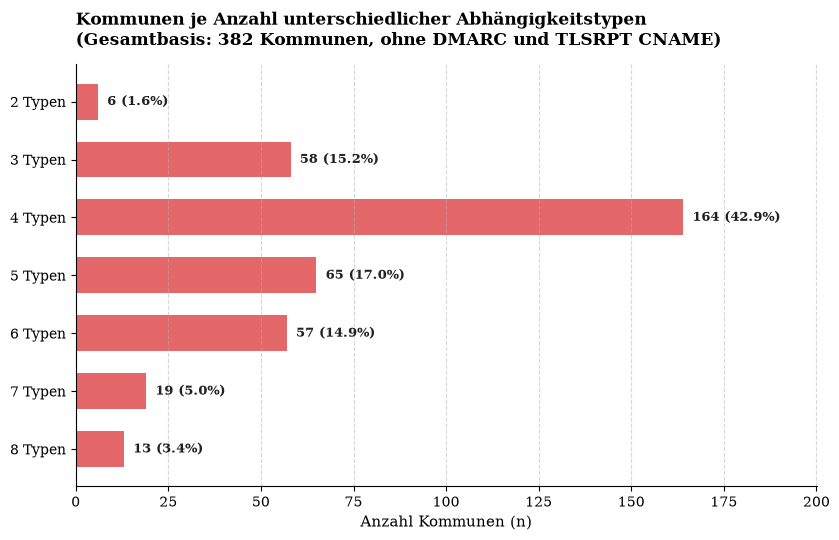

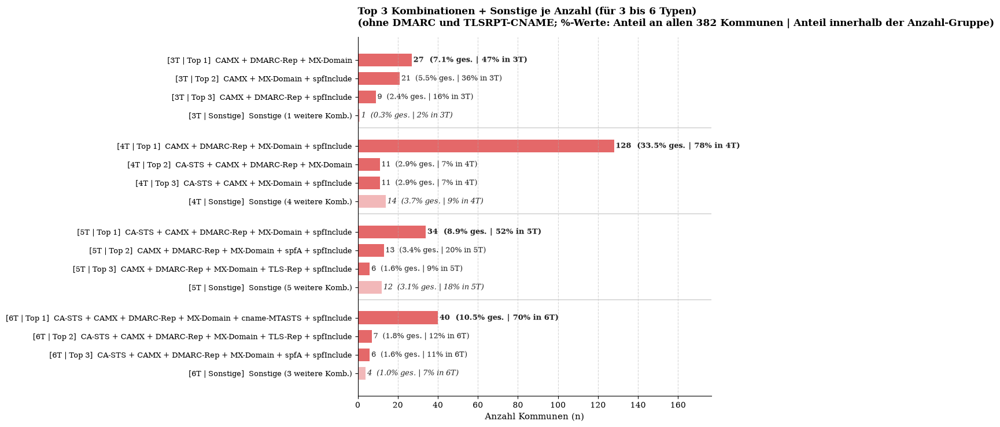

In [129]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. KONFIGURATION & DATENVORBEREITUNG
# ==============================================================================
TH_HELLROT = '#E15759'  # Zentraler Hex-Farbwert für TH-Nürnberg Hellrot
ausblenden = ['cnameDmarcPolicy', 'cnameTLSRPTDnsRecord']
kurznamen = {
    'externalDMARCReportDomain': 'DMARC-Rep',
    'spfInclude': 'spfInclude',
    'CASTSPolicy': 'CA-STS',
    'cnameMTASTSPolicy': 'cname-MTASTS',
    'externalTlsReportDomain': 'TLS-Rep',
    'spfA': 'spfA',
    'cnameMtaStsDnsRecord': 'cname-MTS-DNS',
    'cnameDmarcPolicy': 'cname-DMARC',
    'spfRedirect': 'spfRedirect',
    'cnameTLSRPTDnsRecord': 'cname-TLSRPT',
    'CAMX': 'CAMX',
    'externalMxDomain': 'MX-Domain'
}

total_kommunen = df_gb_external['code'].nunique()

# Auszublendende Kategorien vorab herausfiltern und Kurznamen anwenden
df_rel = df_gb_external[~df_gb_external['dependencyType'].isin(ausblenden)].copy()
df_rel['dep_short'] = df_rel['dependencyType'].replace(kurznamen)

# Pro Kommune Anzahl unterschiedlicher Typen und Kombination ermitteln
komm_agg = (
    df_rel.groupby('code')['dep_short']
    .agg(
        anzahl_typen='nunique',
        kombination=lambda s: ' + '.join(sorted(s.dropna().unique()))
    )
    .reset_index()
)

def get_top_k_plus_sonstige(komm_df, target_counts=[3, 4, 5, 6], total_basis=382, top_k=3):
    rows = []
    for n in sorted(target_counts):
        sub = komm_df[komm_df['anzahl_typen'] == n]
        n_total_group = len(sub)
        if n_total_group == 0:
            continue
        vc = sub['kombination'].value_counts()
        top_vc = vc.head(top_k)
        rest_count = vc.iloc[top_k:].sum()
        
        for rank, (kombi, cnt) in enumerate(top_vc.items(), start=1):
            rows.append({
                'anzahl_typen': n,
                'gruppe_gesamt': n_total_group,
                'rang': f"Top {rank}",
                'kombination': kombi,
                'anzahl_kommunen': cnt,
                'anteil_gruppe_pct': (cnt / n_total_group) * 100,
                'anteil_gesamt_pct': (cnt / total_basis) * 100
            })
        if rest_count > 0:
            n_rest_kombis = len(vc) - top_k
            rows.append({
                'anzahl_typen': n,
                'gruppe_gesamt': n_total_group,
                'rang': 'Sonstige',
                'kombination': f"Sonstige ({n_rest_kombis} weitere Komb.)",
                'anzahl_kommunen': rest_count,
                'anteil_gruppe_pct': (rest_count / n_total_group) * 100,
                'anteil_gesamt_pct': (rest_count / total_basis) * 100
            })
    return pd.DataFrame(rows)


# ==============================================================================
# DIAGRAMM 1: Kommunen je Anzahl unterschiedlicher Abhängigkeitstypen
# ==============================================================================
all_counts = komm_agg['anzahl_typen'].value_counts().sort_index()
y_labels_1 = [f"{k} Typ{'en' if k != 1 else ''}" for k in all_counts.index]

fig1, ax1 = plt.subplots(figsize=(8.5, 5.5))
bars_1 = ax1.barh(y_labels_1, all_counts.values, color=TH_HELLROT, alpha=0.90, height=0.62)

ax1.invert_yaxis()
ax1.set_title(
    f'Kommunen je Anzahl unterschiedlicher Abhängigkeitstypen\n'
    f'(Gesamtbasis: {total_kommunen} Kommunen, ohne DMARC und TLSRPT CNAME)',
    fontsize=12, fontweight='bold', loc='left', pad=14
)
ax1.set_xlabel('Anzahl Kommunen (n)', fontsize=10.5)
ax1.set_xlim(0, max(all_counts.values) * 1.22)
ax1.grid(axis='x', linestyle='--', alpha=0.5)
ax1.spines[['top', 'right']].set_visible(False)

for bar, val in zip(bars_1, all_counts.values):
    pct = (val / total_kommunen) * 100
    ax1.text(
        val + 2.5, bar.get_y() + bar.get_height() / 2,
        f"{val} ({pct:.1f}%)",
        va='center', ha='left', fontsize=9.5, fontweight='bold', color='#222222'
    )

plt.tight_layout()
plt.savefig('diagramm1_anzahl_typen.png', dpi=300, bbox_inches='tight')
plt.show()


# ==============================================================================
# DIAGRAMM 2: Top 3 Kombinationen + Sonstige je Anzahl (für 3 bis 6 Typen)
# ==============================================================================
plot_df_3_6 = get_top_k_plus_sonstige(
    komm_agg, target_counts=[3, 4, 5, 6], total_basis=total_kommunen, top_k=3
)

fig2, ax2 = plt.subplots(figsize=(12.5, 7.5))
y_positions, y_labels_2, group_separators = [], [], []
curr_y, prev_n = 0, None

for _, row in plot_df_3_6.iterrows():
    n = row['anzahl_typen']
    if prev_n is not None and n != prev_n:
        group_separators.append(curr_y - 0.35)
        curr_y += 0.65  # Optischer Abstand zwischen den Anzahl-Gruppen
    prev_n = n
    
    y_positions.append(curr_y)
    y_labels_2.append(f"[{n}T | {row['rang']}]  {row['kombination']}")
    
    # TH-Nürnberg Hellrot: Top 1-3 kräftig (0.90), "Sonstige" abgetönt (0.42)
    alph = 0.42 if row['rang'] == 'Sonstige' else 0.90
    
    ax2.barh(curr_y, row['anzahl_kommunen'], color=TH_HELLROT, alpha=alph, height=0.70)
    ax2.text(
        row['anzahl_kommunen'] + 0.8, curr_y,
        f"{row['anzahl_kommunen']}  ({row['anteil_gesamt_pct']:.1f}% ges. | {row['anteil_gruppe_pct']:.0f}% in {n}T)",
        va='center', ha='left', fontsize=9.2, color='#222222',
        fontstyle='italic' if row['rang'] == 'Sonstige' else 'normal',
        fontweight='bold' if row['rang'] == 'Top 1' else 'normal'
    )
    curr_y += 1.0

for sep in group_separators:
    ax2.axhline(sep, color='#CCCCCC', linestyle='-', linewidth=1.0)

ax2.set_yticks(y_positions)
ax2.set_yticklabels(y_labels_2, fontsize=9.5)
ax2.invert_yaxis()
ax2.set_xlim(0, max(plot_df_3_6['anzahl_kommunen']) * 1.38)
ax2.set_title(
    'Top 3 Kombinationen + Sonstige je Anzahl (für 3 bis 6 Typen)\n'
    f'(ohne DMARC und TLSRPT-CNAME; %-Werte: Anteil an allen {total_kommunen} Kommunen | Anteil innerhalb der Anzahl-Gruppe)',
    fontsize=12, fontweight='bold', loc='left', pad=14
)
ax2.set_xlabel('Anzahl Kommunen (n)', fontsize=10.5)
ax2.grid(axis='x', linestyle='--', alpha=0.5)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('diagramm2_kombinationen_3_bis_6.png', dpi=300, bbox_inches='tight')
plt.show()

## Deutschland Kombinationen

In [130]:
from typing import List, Optional
import pandas as pd
import matplotlib.pyplot as plt

def get_top_k_plus_sonstige(
    df: pd.DataFrame,
    count_col: str = "anzahl_typen",
    combo_col: str = "kombination",
    target_counts: List[int] = [1, 2, 3, 4, 5, 6],
    total_basis: Optional[int] = None,
    top_k: int = 3
) -> pd.DataFrame:
    """
    Ermittelt je Anzahl (target_counts) die Top-K häufigsten Kombinationen
    und fasst alle übrigen Kombinationen dieser Anzahl unter 'Sonstige' zusammen.
    
    Parameter:
    - df: DataFrame auf Kommunen-Ebene (1 Zeile pro Kommune, z. B. df_merged_de)
    - count_col: Spaltenname der Anzahl (z. B. 'bsi_gs_score', 'govuk_score' oder 'anzahl_typen')
    - combo_col: Spaltenname des Kombinations-Strings (z. B. 'bsi_gs_combo', 'govuk_combo' oder 'kombination')
    - target_counts: Liste der auszuwertenden Anzahlen (z. B. [3, 4, 5, 6])
    - total_basis: Gesamtzahl aller untersuchten Kommunen für 'anteil_gesamt_pct' (Standard: len(df))
    - top_k: Anzahl der einzeln ausgewiesenen Top-Kombinationen je Gruppe (Standard: 3)
    """
    if total_basis is None:
        total_basis = len(df)

    rows = []
    for n in sorted(target_counts):
        sub = df[df[count_col] == n]
        n_total_group = len(sub)
        if n_total_group == 0:
            continue

        vc = sub[combo_col].value_counts()
        top_vc = vc.head(top_k)
        rest_count = int(vc.iloc[top_k:].sum())

        for rank, (kombi, cnt) in enumerate(top_vc.items(), start=1):
            rows.append({
                "anzahl_typen": n,
                "gruppe_gesamt": n_total_group,
                "rang": f"Top {rank}",
                "kombination": kombi,
                "anzahl_kommunen": int(cnt),
                "anteil_gruppe_pct": (cnt / n_total_group) * 100,
                "anteil_gesamt_pct": (cnt / total_basis) * 100,
            })

        if rest_count > 0:
            n_rest_kombis = len(vc) - top_k
            rows.append({
                "anzahl_typen": n,
                "gruppe_gesamt": n_total_group,
                "rang": "Sonstige",
                "kombination": f"Sonstige ({n_rest_kombis} weitere Komb.)",
                "anzahl_kommunen": rest_count,
                "anteil_gruppe_pct": (rest_count / n_total_group) * 100,
                "anteil_gesamt_pct": (rest_count / total_basis) * 100,
            })

    return pd.DataFrame(rows)


def plot_top_k_plus_sonstige(
    plot_df: pd.DataFrame,
    total_basis: int,
    title: str = "Top 3 Kombinationen + Sonstige je Anzahl erfüllter Kriterien",
    unit_short: str = "K",          # Kürzel in der Klammer links: 'K' = Kriterien, 'T' = Typen
    bar_color: str = "#E15759",      # TH-Nürnberg Hellrot
    metric: str = "count",           # 'count' (Anzahl Kommunen) oder 'group_pct' (% in Gruppe)
    figsize: Optional[tuple] = None,
    save_path: Optional[str] = None
):
    """
    Visualisiert das Ergebnis von get_top_k_plus_sonstige() als gruppiertes Balkendiagramm.
    """
    if figsize is None:
        figsize = (12.5, max(5.5, len(plot_df) * 0.48 + 1.8))

    fig, ax = plt.subplots(figsize=figsize)
    y_positions, y_labels, group_separators = [], [], []
    curr_y, prev_n = 0.0, None

    x_col = "anzahl_kommunen" if metric == "count" else "anteil_gruppe_pct"
    max_x = plot_df[x_col].max() if len(plot_df) > 0 else 100

    for _, row in plot_df.iterrows():
        n = int(row["anzahl_typen"])
        if prev_n is not None and n != prev_n:
            group_separators.append(curr_y - 0.35)
            curr_y += 0.65  # Optischer Abstand zwischen den Anzahl-Gruppen
        prev_n = n

        y_positions.append(curr_y)
        y_labels.append(f"[{n}{unit_short} | {row['rang']}]  {row['kombination']}")

        alph = 0.42 if row["rang"] == "Sonstige" else 0.90
        val = row[x_col]

        ax.barh(curr_y, val, color=bar_color, alpha=alph, height=0.70, edgecolor="none")
        ax.text(
            val + max_x * 0.015,
            curr_y,
            f"{int(row['anzahl_kommunen']):,}  ({row['anteil_gesamt_pct']:.2f}% ges. | {row['anteil_gruppe_pct']:.1f}% in {n}{unit_short})".replace(",", "."),
            va="center",
            ha="left",
            fontsize=9.2,
            color="#222222",
            fontstyle="italic" if row["rang"] == "Sonstige" else "normal",
            fontweight="bold" if row["rang"] == "Top 1" else "normal",
        )
        curr_y += 1.0

    for sep in group_separators:
        ax.axhline(sep, color="#CCCCCC", linestyle="-", linewidth=1.0)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels, fontsize=9.5)
    ax.invert_yaxis()
    ax.set_xlim(0, max_x * 1.38)

    if metric == "group_pct":
        valid_ticks = [t for t in ax.get_xticks() if 0 <= t <= 100]
        ax.set_xticks(valid_ticks)
        if valid_ticks:
            ax.spines["bottom"].set_bounds(0, max(valid_ticks[-1], min(100, max_x)))
        ax.set_xlabel("Anteil innerhalb der jeweiligen Anzahl-Gruppe (%)", fontsize=10.5)
    else:
        ax.set_xlabel("Anzahl Kommunen (n)", fontsize=10.5)

    ax.set_title(
        f"{title}\n(Gesamtbasis: N = {total_basis:,} Kommunen; %-Werte: Anteil an Gesamt | Anteil innerhalb der Gruppe)".replace(",", "."),
        fontsize=12,
        fontweight="bold",
        loc="left",
        pad=14,
    )
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    return fig

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Optional, List, Any

def _natural_sort_key(series: pd.Series) -> pd.Series:
    """
    Erkennt reine Zahlen (1, 2, 10) sowie Strings mit führenden Zahlen ('0 Typen', '1 Typ', '10 Typen')
    und sortiert sie numerisch korrekt statt alphabetisch.
    """
    if pd.api.types.is_numeric_dtype(series):
        return series
    extracted = series.astype(str).str.extract(r'^(\d+)', expand=False)
    if extracted.notna().all():
        return extracted.astype(float)
    return series.astype(str)


def _prepare_freq_df(freq_df: pd.DataFrame, include_categories: Optional[List[Any]] = None):
    """
    Trennt die 'Gesamt'-Zeile ab, liest total_basis (N) aus, wandelt 'Anteil (%)' in Float um
    und ergänzt optional fehlende Kategorien aus include_categories mit 0 (0.0%).
    """
    df_clean = freq_df.copy()
    target_col = df_clean.columns[0]
    
    gesamt_mask = df_clean[target_col].astype(str) == 'Gesamt'
    if gesamt_mask.any():
        total_basis = int(df_clean.loc[gesamt_mask, 'Anzahl (n)'].iloc[0])
        df_plot = df_clean[~gesamt_mask].copy()
    else:
        total_basis = int(df_clean['Anzahl (n)'].sum())
        df_plot = df_clean.copy()
        
    df_plot['Anzahl (n)'] = df_plot['Anzahl (n)'].astype(int)
    df_plot['pct_num'] = (
        df_plot['Anteil (%)'].astype(str).str.replace('%', '', regex=False).astype(float)
    )

    # NEU: Fehlende Kategorien mit 0 (0.0%) auffüllen, falls gewünscht
    if include_categories is not None:
        existing = set(df_plot[target_col].astype(str))
        missing_rows = [
            {target_col: cat, 'Anzahl (n)': 0, 'Anteil (%)': '0.0%', 'pct_num': 0.0}
            for cat in include_categories if str(cat) not in existing
        ]
        if missing_rows:
            df_plot = pd.concat([df_plot, pd.DataFrame(missing_rows)], ignore_index=True)

    return df_plot, target_col, total_basis


def plot_top_frequencies(
    res_left: pd.DataFrame,
    res_right: Optional[pd.DataFrame] = None,
    title_left: str = "Großbritannien (GB)",
    title_right: str = "Deutschland (DE)",
    main_title: str = "Häufigste externe Abhängigkeiten",
    mode: str = "side_by_side",                      # 'side_by_side' oder 'grouped'
    metric: str = "pct",                             # 'pct' oder 'count'
    sort_by: str = "value",                          # 'value', 'category' oder 'keep'
    ascending: bool = False,                         # True = aufsteigend, False = absteigend
    include_categories: Optional[List[Any]] = None,  # NEU: Kategorien erzwingen (auch bei n=0)
    color_left: str = "#E15759",                     # TH-Nürnberg Hellrot
    color_right: str = "#555555",                    # Kontrastfarbe für DE
    sync_xlim: bool = True,
    figsize: Optional[tuple] = None,
    save_path: Optional[str] = None
):
    df_l, col_l, base_l = _prepare_freq_df(res_left, include_categories=include_categories)
    x_col = 'pct_num' if metric == 'pct' else 'Anzahl (n)'
    x_label = 'Anteil betroffener Kommunen (%)' if metric == 'pct' else 'Anzahl Kommunen (n)'

    def _sort_df(d: pd.DataFrame, cat_col: str, val_col: str):
        if sort_by == "keep":
            if include_categories is not None:
                order_map = {str(k): i for i, k in enumerate(include_categories)}
                d['_order'] = d[cat_col].astype(str).map(lambda x: order_map.get(x, 9999))
                return d.sort_values('_order', ascending=ascending).drop(columns=['_order']).reset_index(drop=True)
            return d.reset_index(drop=True)
        elif sort_by == "category":
            return d.sort_values(by=cat_col, ascending=ascending, key=_natural_sort_key).reset_index(drop=True)
        else:  # 'value'
            return d.sort_values(by=val_col, ascending=ascending).reset_index(drop=True)

    df_l = _sort_df(df_l, col_l, x_col)

    def _apply_xaxis_limits_and_ticks(ax, cur_max):
        ax.set_xlim(0, cur_max * 1.28)
        if metric == 'pct':
            valid_ticks = [t for t in ax.get_xticks() if 0 <= t <= 100]
            ax.set_xticks(valid_ticks)
            if valid_ticks:
                ax.spines['bottom'].set_bounds(0, max(valid_ticks[-1], min(100, cur_max)))

    # ==========================================================================
    # FALL 1: Einzelnes Diagramm (res_right=None)
    # ==========================================================================
    if res_right is None:
        if figsize is None:
            figsize = (9, max(4.5, len(df_l) * 0.55 + 1.5))
        fig, ax = plt.subplots(figsize=figsize)
        
        bars = ax.barh(df_l[col_l].astype(str), df_l[x_col], color=color_left, alpha=0.90, height=0.62)
        ax.invert_yaxis()
        ax.set_title(
            f"{main_title}\n({title_left}, Gesamtbasis: N = {base_l:,} Kommunen)".replace(',', '.'),
            fontsize=12, fontweight='bold', loc='left', pad=12
        )
        ax.set_xlabel(x_label, fontsize=10.5)
        max_val = df_l[x_col].max() if len(df_l) > 0 and df_l[x_col].max() > 0 else 100
        _apply_xaxis_limits_and_ticks(ax, max_val)
        ax.grid(axis='x', linestyle='--', alpha=0.5)
        ax.spines[['top', 'right']].set_visible(False)

        for bar, (_, row) in zip(bars, df_l.iterrows()):
            val = row[x_col]
            txt = (
                f"{row['pct_num']:.1f}% (n={row['Anzahl (n)']:,})".replace(',', '.')
                if metric == 'pct'
                else f"{row['Anzahl (n)']:,} ({row['pct_num']:.1f}%)".replace(',', '.')
            )
            ax.text(
                val + max_val * 0.02, bar.get_y() + bar.get_height() / 2, txt,
                va='center', ha='left', fontsize=9.5, fontweight='bold', color='#222222'
            )

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        return fig

    # ==========================================================================
    # FALL 2: Ländervergleich (res_left und res_right übergeben)
    # ==========================================================================
    # Tipp: Bei side_by_side können wir auch automatisch alle Kategorien der Gegenseite ergänzen,
    # wenn include_categories übergeben wurde.
    df_r, col_r, base_r = _prepare_freq_df(res_right, include_categories=include_categories)
    df_r = _sort_df(df_r, col_r, x_col)

    if mode == "side_by_side":
        n_rows = max(len(df_l), len(df_r))
        if figsize is None:
            figsize = (15, max(5.0, n_rows * 0.58 + 1.8))
        fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=figsize)

        shared_max = max(df_l[x_col].max(), df_r[x_col].max()) if sync_xlim else None

        for ax, d_sub, c_name, base_n, title_sub, col_bar in [
            (ax_l, df_l, col_l, base_l, title_left, color_left),
            (ax_r, df_r, col_r, base_r, title_right, color_right)
        ]:
            bars = ax.barh(d_sub[c_name].astype(str), d_sub[x_col], color=col_bar, alpha=0.90, height=0.62)
            ax.invert_yaxis()
            ax.set_title(
                f"{title_sub}\n(Basis: N = {base_n:,} Kommunen)".replace(',', '.'),
                fontsize=11.5, fontweight='bold', loc='left', pad=10
            )
            ax.set_xlabel(x_label, fontsize=10)
            
            cur_max = shared_max if (sync_xlim and shared_max is not None) else d_sub[x_col].max()
            _apply_xaxis_limits_and_ticks(ax, cur_max)
            ax.grid(axis='x', linestyle='--', alpha=0.5)
            ax.spines[['top', 'right']].set_visible(False)

            for bar, (_, row) in zip(bars, d_sub.iterrows()):
                val = row[x_col]
                txt = (
                    f"{row['pct_num']:.1f}% (n={row['Anzahl (n)']:,})".replace(',', '.')
                    if metric == 'pct'
                    else f"{row['Anzahl (n)']:,} ({row['pct_num']:.1f}%)".replace(',', '.')
                )
                ax.text(
                    val + cur_max * 0.02, bar.get_y() + bar.get_height() / 2, txt,
                    va='center', ha='left', fontsize=9.2, fontweight='bold', color='#222222'
                )

        fig.suptitle(main_title, fontsize=13, fontweight='bold', y=1.02)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        return fig

    elif mode == "grouped":
        # Vereinheitliche Kategoriespalte als String, damit der Outer-Join alle Kategorien beider Seiten vereint
        df_l_merge = df_l[[col_l, 'Anzahl (n)', 'pct_num']].copy()
        df_l_merge['cat'] = df_l_merge[col_l].astype(str)
        df_r_merge = df_r[[col_r, 'Anzahl (n)', 'pct_num']].copy()
        df_r_merge['cat'] = df_r_merge[col_r].astype(str)

        merged = pd.merge(
            df_l_merge[['cat', 'Anzahl (n)', 'pct_num']].rename(columns={'Anzahl (n)': 'n_l', 'pct_num': 'pct_l'}),
            df_r_merge[['cat', 'Anzahl (n)', 'pct_num']].rename(columns={'Anzahl (n)': 'n_r', 'pct_num': 'pct_r'}),
            on='cat', how='outer'
        ).fillna({'n_l': 0, 'pct_l': 0.0, 'n_r': 0, 'pct_r': 0.0})

        # Sortierung im Grouped-Modus:
        if sort_by == "category":
            merged = merged.sort_values(by='cat', ascending=ascending, key=_natural_sort_key).reset_index(drop=True)
        elif sort_by == "value":
            val_col_sort = 'pct_l' if metric == 'pct' else 'n_l'
            val_col_tie = 'pct_r' if metric == 'pct' else 'n_r'
            # Falls eine Kategorie in Links 0 ist, wird bei Gleichstand nach Rechts sortiert
            merged = merged.sort_values(by=[val_col_sort, val_col_tie], ascending=ascending).reset_index(drop=True)
        else:  # 'keep'
            if include_categories is not None:
                cat_order = [str(c) for c in include_categories] + [
                    c for c in merged['cat'] if c not in {str(x) for x in include_categories}
                ]
            else:
                cat_order = list(df_l_merge['cat']) + [c for c in df_r_merge['cat'] if c not in set(df_l_merge['cat'])]
            merged['_order'] = merged['cat'].map({k: i for i, k in enumerate(cat_order)})
            merged = merged.sort_values('_order', ascending=ascending).drop(columns=['_order']).reset_index(drop=True)

        if figsize is None:
            figsize = (11.5, max(5.5, len(merged) * 0.72 + 1.8))
        fig, ax = plt.subplots(figsize=figsize)

        y = np.arange(len(merged))
        h = 0.36

        val_l = merged['pct_l'] if metric == 'pct' else merged['n_l']
        val_r = merged['pct_r'] if metric == 'pct' else merged['n_r']
        max_v = max(val_l.max(), val_r.max())

        ax.barh(y - h/2, val_l, height=h, color=color_left, alpha=0.92,
                label=f"{title_left} (Basis: N = {base_l:,})".replace(',', '.'))
        ax.barh(y + h/2, val_r, height=h, color=color_right, alpha=0.88,
                label=f"{title_right} (Basis: N = {base_r:,})".replace(',', '.'))

        ax.set_yticks(y)
        ax.set_yticklabels(merged['cat'].astype(str), fontsize=15, fontweight='bold')
        ax.invert_yaxis()
        ax.set_xlabel(x_label, fontsize=11.5)
        _apply_xaxis_limits_and_ticks(ax, max_v)
        ax.set_title(main_title, fontsize=12.5, fontweight='bold', loc='left', pad=14)
        ax.grid(axis='x', linestyle='--', alpha=0.5)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(loc='lower right', frameon=True, fontsize=11)

        for idx, row in merged.iterrows():
            vl = row['pct_l'] if metric == 'pct' else row['n_l']
            vr = row['pct_r'] if metric == 'pct' else row['n_r']
            txt_l = f"{row['pct_l']:.1f}% (n={int(row['n_l']):,})".replace(',', '.')
            txt_r = f"{row['pct_r']:.1f}% (n={int(row['n_r']):,})".replace(',', '.')
            
            # NEU: Beide Zahlenwerte fettgedruckt (fontweight='bold')
            ax.text(vl + max_v * 0.015, idx - h/2, txt_l, va='center', ha='left', fontsize=10.8, color='#222222', fontweight='bold')
            ax.text(vr + max_v * 0.015, idx + h/2, txt_r, va='center', ha='left', fontsize=10.8, color='#222222', fontweight='bold')

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        return fig

## Diagramme

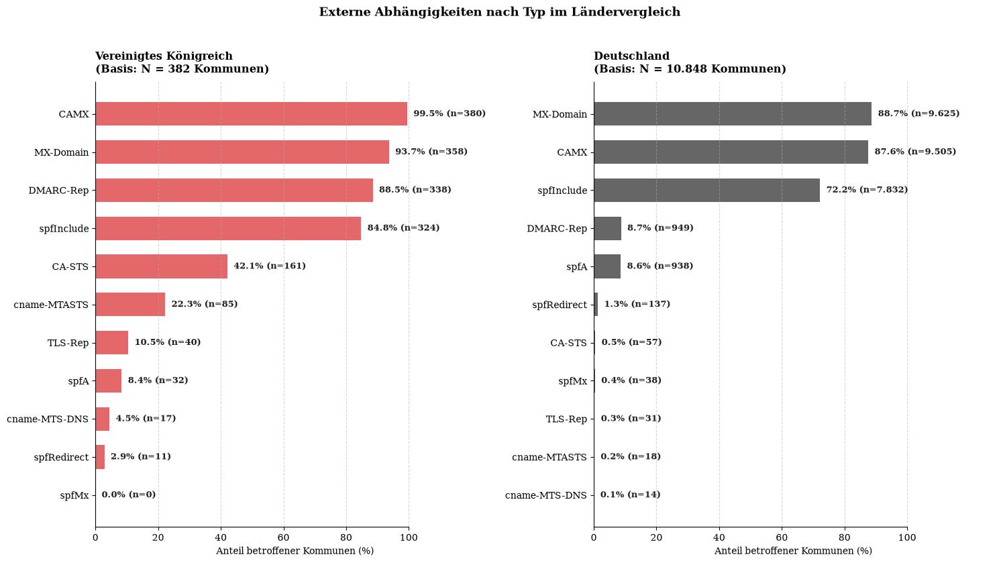

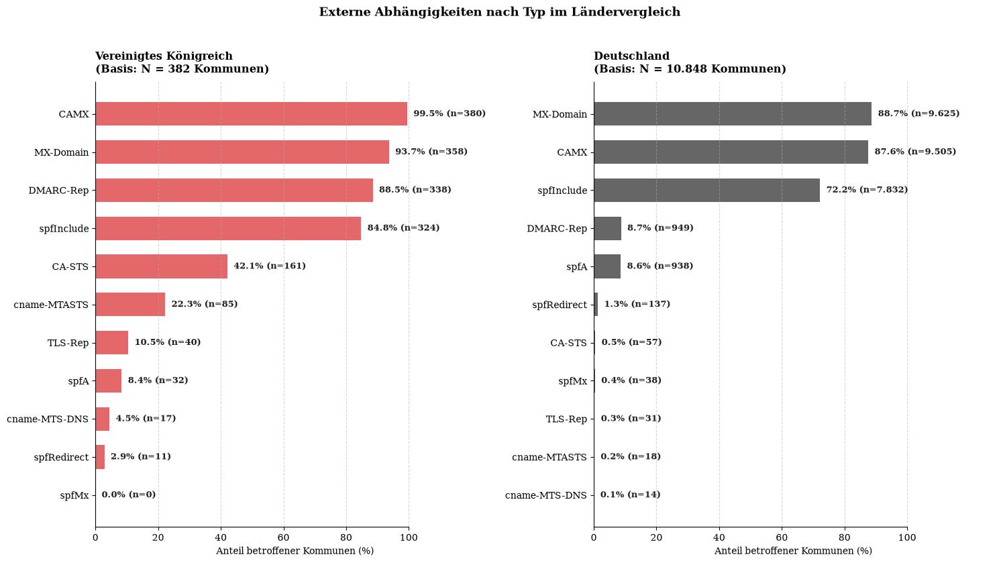

In [132]:
ausblenden = ['cnameDmarcPolicy', 'cnameTLSRPTDnsRecord']

# 1. Beide Tabellen wie gewohnt mit get_top_frequencies() berechnen
res_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='dependencyType',
    top_n=None,
    row_filter=lambda d: ~d['dependencyType'].isin(ausblenden),
    unique_filter_col=['code', 'dependencyType'],
    pct_base_col='code',
   # keep_total_basis=True,
    value_aliases=kurznamen
)

res_de = get_top_frequencies(
    df=df_de_external,
    target_col='dependencyType',
    top_n=None,
    row_filter=lambda d: ~d['dependencyType'].isin(ausblenden),
    unique_filter_col=['code', 'dependencyType'],  # bzw. dein Kommunen-Schlüssel für DE
    pct_base_col='code',
   # keep_total_basis=True,
    value_aliases=kurznamen
)

# 2. Direkt plotten (wahlweise mode='side_by_side' oder mode='grouped')
plot_top_frequencies(
    res_left=res_gb,
    res_right=res_de,
    title_left="Vereinigtes Königreich",
    title_right="Deutschland",
    main_title="Externe Abhängigkeiten nach Typ im Ländervergleich",
    mode="side_by_side",  # Oder "grouped" für eine gemeinsame Y-Achse
    metric="pct",         # Normiert die Balkenlänge auf % der Kommunen je Land
    save_path="laendervergleich_abhaengigkeiten.png",
    include_categories=['spfMx']
)




## Kombination Diagramm

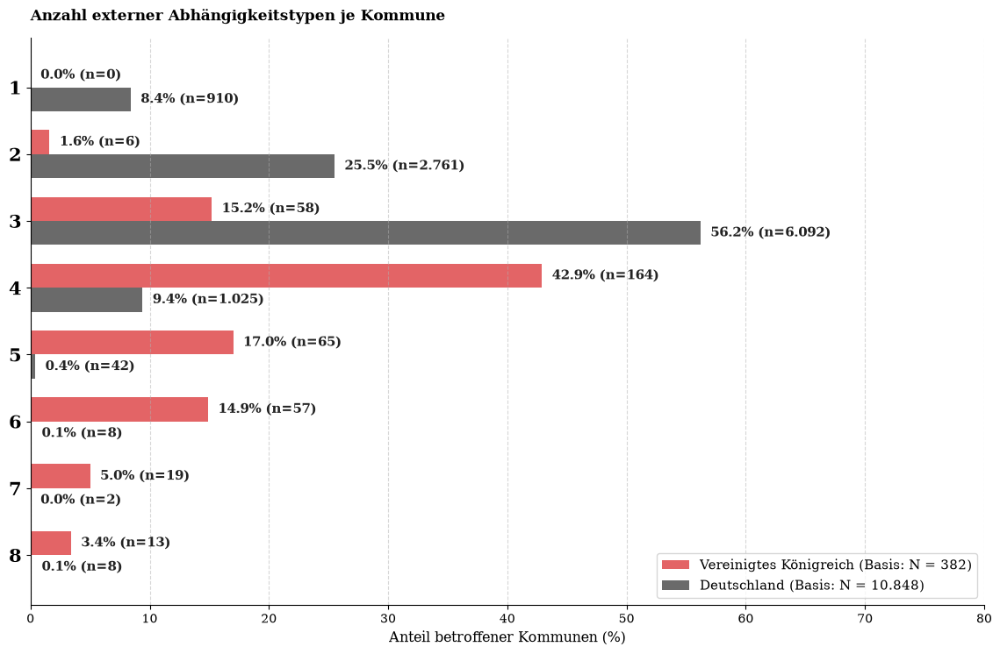

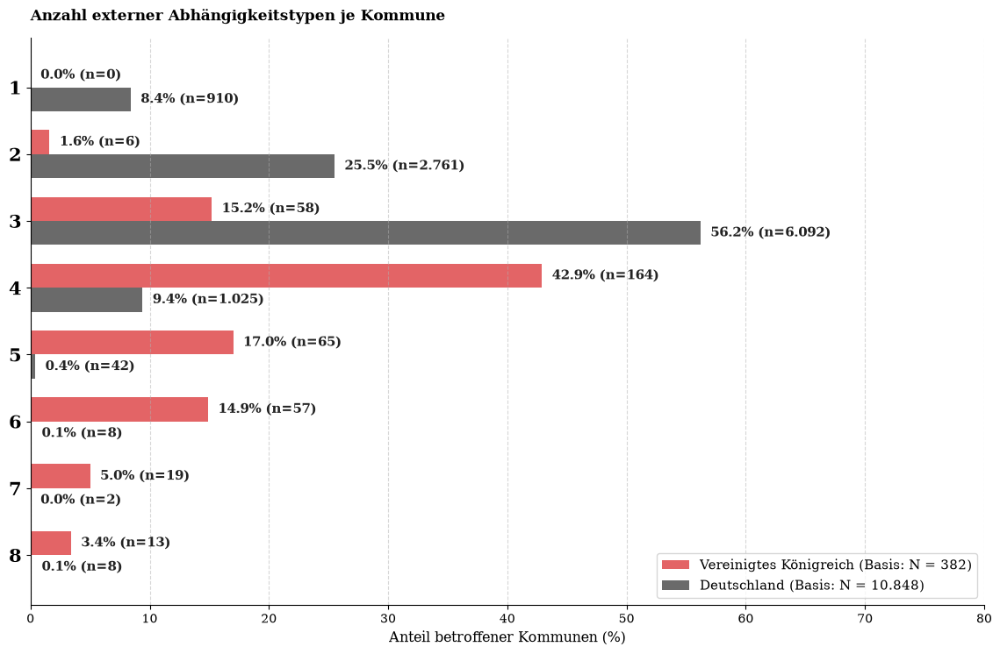

In [138]:
anzahl_verteilung_de

plot_top_frequencies(
    res_left=anzahl_verteilung_gb,
    res_right=anzahl_verteilung_de,
    title_left="Vereinigtes Königreich",
    title_right="Deutschland",
    main_title="Anzahl externer Abhängigkeitstypen je Kommune",
    mode="grouped",  # Oder "grouped" für eine gemeinsame Y-Achse
    metric="pct",         # Normiert die Balkenlänge auf % der Kommunen je Land
    save_path="laendervergleich_abhaengigkeiten_anz.png",
    sort_by="category",
    ascending=True
)

## DKIM 

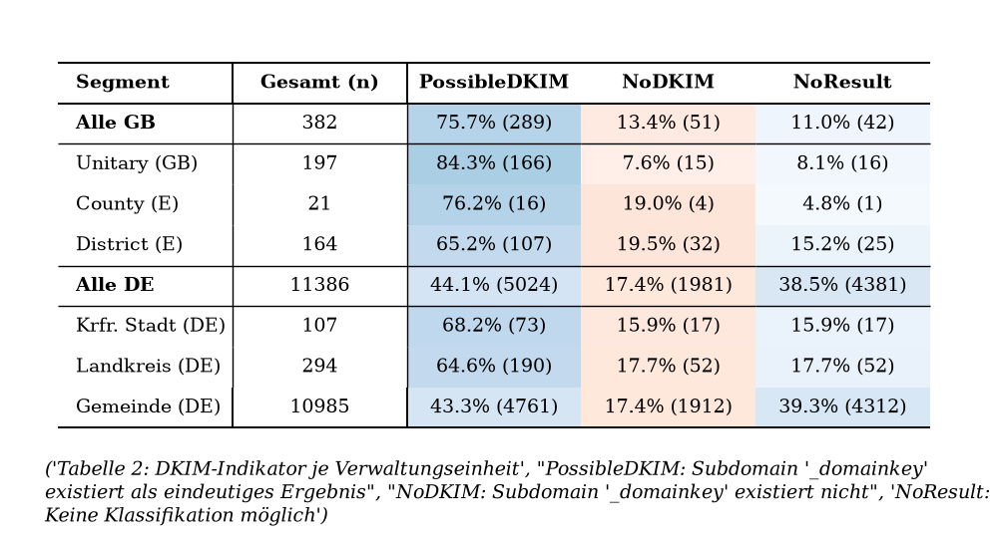

Tabelle erfolgreich gespeichert unter: abbildung_dkim_admin_uebersicht.png


In [6]:

metrics_dkim = {
    "PossibleDKIM": lambda df: df["aggDomainAntiSpoofing_dkimResult"] == "PossibleDKIM",
    "NoDKIM": lambda df: df["aggDomainAntiSpoofing_dkimResult"] == "NoDKIM",
    "NoResult": lambda df: (df["aggDomainAntiSpoofing_dkimResult"] == "Wildcard") | (df["aggDomainAntiSpoofing_dkimResult"] == "OtherError")
    #"Error": lambda df: (df["aggDomainAntiSpoofing_dkimResult"] == "OtherError")
    #"Result": lambda df: ((df["aggDomainAntiSpoofing_dkimResult"] == "PossibleDKIM") | (df["aggDomainAntiSpoofing_dkimResult"] == "NoDKIM"))
}


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dkim = generate_tier_summary(
    df_de="security/data/de/antispoofing_data.csv",
    df_gb="security/data/gb/antispoofing_data.csv",
    metrics=metrics_dkim,
)

legende_dkim =  (
    "Tabelle 2: DKIM-Indikator je Verwaltungseinheit",
    "PossibleDKIM: Subdomain '_domainkey' existiert als eindeutiges Ergebnis",
    "NoDKIM: Subdomain '_domainkey' existiert nicht",
    "NoResult: Keine Klassifikation möglich")
    

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dkim,
    filename="abbildung_dkim_admin_uebersicht.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = legende_dkim
)

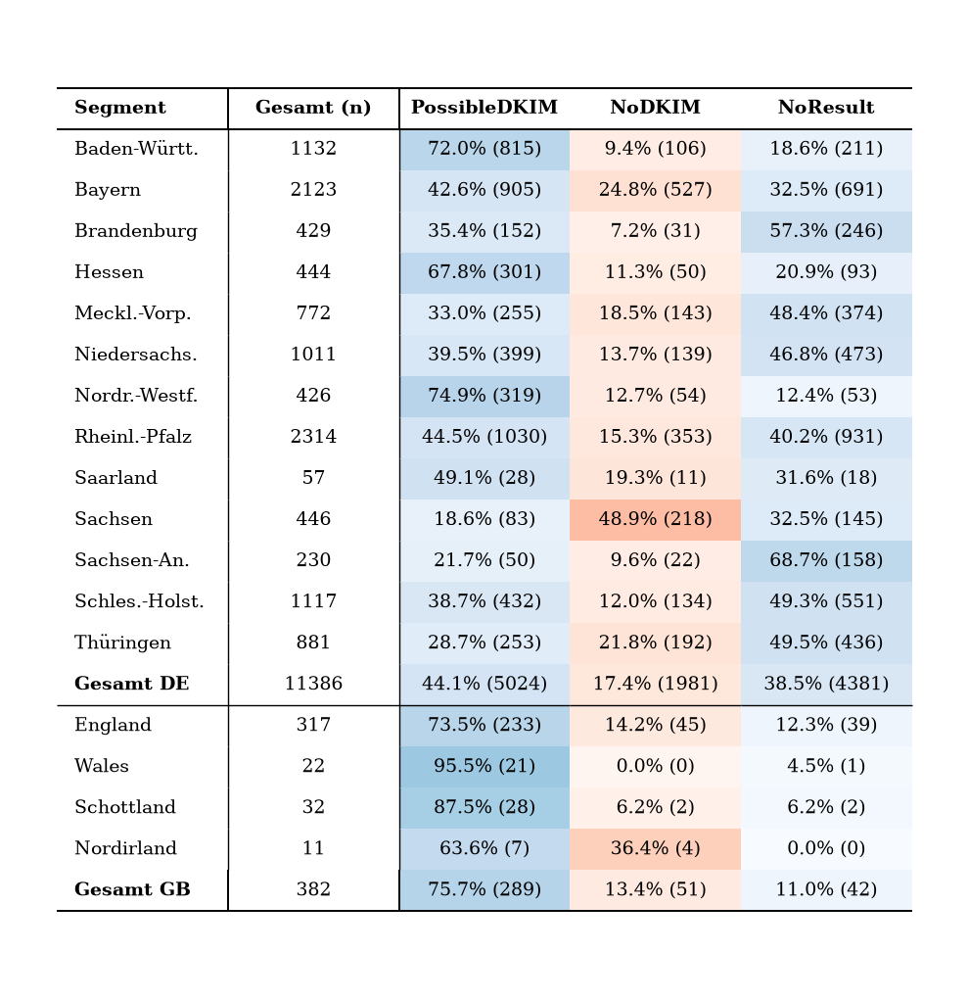

Tabelle erfolgreich gespeichert unter: abbildung_dkim_uebersicht_region.png


In [7]:
#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_region_dkim = generate_region_summary(
    df_de="security/data/de/antispoofing_data.csv",
    df_gb="security/data/gb/antispoofing_data.csv",
    metrics=metrics_dkim,
)

render_table_to_image(
    tbl_region_dkim,
    filename="abbildung_dkim_uebersicht_region.png",
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)


## Transportsicherheit

In [ ]:
metrics_dnssec = {
    "NoDNSSEC": lambda df:( (df["dnssecResult_mxAtLeastOneDNSSEC"] == False) & (df["dnssecResult_domainDNSSEC"] == False ))
     ,
    "not all MX": lambda df: (
        
        (df["dnssecResult_mxAtLeastOneDNSSEC"] == True)
    & (df["dnssecResult_mxAllDNSSEC"] == False)
    & (df["dnssecResult_domainDNSSEC"] == False) )
    ,
    "all MX only": lambda df: (
        (df["dnssecResult_mxAtLeastOneDNSSEC"] == True )
        & (df["dnssecResult_mxAllDNSSEC"] == True )
        & (df["dnssecResult_domainDNSSEC"] == False)
    ),      
    "domain only": lambda df: (
        (df["dnssecResult_mxAtLeastOneDNSSEC"] == False)
        & (df["dnssecResult_mxAllDNSSEC"] == False)
        & (df["dnssecResult_domainDNSSEC"] == True)
    ),
    "dm & not all MX": lambda df: (
        (df["dnssecResult_mxAtLeastOneDNSSEC"] == True)
        & (df["dnssecResult_mxAllDNSSEC"] == False)
        & (df["dnssecResult_domainDNSSEC"] == True)
    ),
    "complete": lambda df: (
        (df["dnssecResult_mxAtLeastOneDNSSEC"] == True)
        & (df["dnssecResult_mxAllDNSSEC"] == True)
        &( df["dnssecResult_domainDNSSEC"] == True)
    )
}


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_transport = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_dnssec,
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_transport,
    filename="abbildung_dnssec_uebersicht.png",
    red_keywords= ["NoDNSSEC"],
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 10: DNSSEC Nutzung je Verwaltungseinheit", "NoDNSSEC: DNSSEC ist für die E-Mail-Domain gänzlich nicht vorhanden", 
           "not all MX: Nur die Zone von nicht allen Mailserverdomains (MX-Einträgen) verwendet DNSSEC" , "all MX only: Nur die Zonen aller Mailserverdomains sind per DNSSEC signiert", 
           "domain only: Nur die Zone der (E-Mail-)Domain ist per DNSSEC signiert", "dm & not all MX: Die Zone der Domain und nicht alle Mailserverdomains verwenden DNSSEC",
          "complete: DNSSEC ist für die E-Mail-Domain und alle Mailserverzonen aktiv"
          )
)


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_region_transport_reg = generate_region_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_dnssec
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_region_transport_reg,
    filename="abbildung_dnssec_uebersicht_region.png",
    red_keywords= ["NoDNSSEC"],
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 11: DNSSEC Nutzung je Region", "NoDNSSEC: DNSSEC ist für die E-Mail-Domain gänzlich nicht vorhanden", 
           "not all MX: Nur die Zone von nicht allen Mailserverdomains (MX-Einträgen) verwendet DNSSEC" , "all MX only: Nur die Zonen aller Mailserverdomains sind per DNSSEC signiert", 
           "domain only: Nur die Zone der (E-Mail-)Domain ist per DNSSEC signiert", "dm & not all MX: Die Zone der Domain und nicht alle Mailserverdomains verwenden DNSSEC",
          "complete: DNSSEC ist für die E-Mail-Domain und alle Mailserverzonen aktiv"
              )
)


tbl_region_transport_reg_all = generate_region_summary_all(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_dnssec
    
)


render_table_to_image(
    tbl_region_transport_reg_all,
    filename="abbildung_dnssec_uebersicht_region.png",
    red_keywords= ["NoDNSSEC"],
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 11: DNSSEC Nutzung je Region", "NoDNSSEC: DNSSEC ist für die E-Mail-Domain gänzlich nicht vorhanden", 
           "not all MX: Nur die Zone von nicht allen Mailserverdomains (MX-Einträgen) verwendet DNSSEC" , "all MX only: Nur die Zonen aller Mailserverdomains sind per DNSSEC signiert", 
           "domain only: Nur die Zone der (E-Mail-)Domain ist per DNSSEC signiert", "dm & not all MX: Die Zone der Domain und nicht alle Mailserverdomains verwenden DNSSEC",
          "complete: DNSSEC ist für die E-Mail-Domain und alle Mailserverzonen aktiv"
              )
)








## External Dep


In [110]:
df_de_transport = pd.read_csv('security/data/de/transport_data.csv', sep=';', low_memory=False)

top_dnssec_de = get_top_frequencies(
    df=df_de_transport,
    target_col='aggDataTransportMetadata_mxRecords',
    top_n=8,
    row_filter=lambda d: (d['dnssecResult_mxAllDNSSEC'] == True) & (d['aggDataTransportMetadata_isValid'] == True),
    unique_filter_col=['domain'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code"
)




print(top_dnssec_de)


df_de_mx_transport = pd.read_csv('security/data/de/mx_data.csv', sep=';', low_memory=False)

top_dnssec_de_mx = get_top_frequencies(
    df=df_de_mx_transport,
    target_col='mxRecord',
    top_n=8,
    row_filter=lambda d: d['MxDNSSECFullyValidated'] == True,
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code"
)
print(top_dnssec_de_mx)



                  aggDataTransportMetadata_mxRecords  Anzahl (n) Anteil (%)
0                       mx01.ionos.de, mx00.ionos.de         878      29.0%
1                                    smtpin.rzone.de         661      21.8%
2                                     mail.bayern.de         437      14.4%
3     s2vg300mr02.pzd-svn.de, s2vg300mr01.pzd-svn.de         206       6.8%
4  mx5skas.kgrz-ks.de, mx3sgie.ekom21.de, mx4skas...         182       6.0%
5                       mx04.mvnet.de, mx03.mvnet.de         127       4.2%
6                       mta1in.kdo.de, mta2in.kdo.de         118       3.9%
7                             smtp.rhoen-grabfeld.de          37       1.2%
8                                             Gesamt        3032     100.0%
                 mxRecord  Anzahl (n) Anteil (%)
0           mx01.ionos.de         880      28.4%
1         smtpin.rzone.de         661      21.3%
2          mail.bayern.de         455      14.7%
3  s2vg300mr02.pzd-svn.de         207       

## DANE 

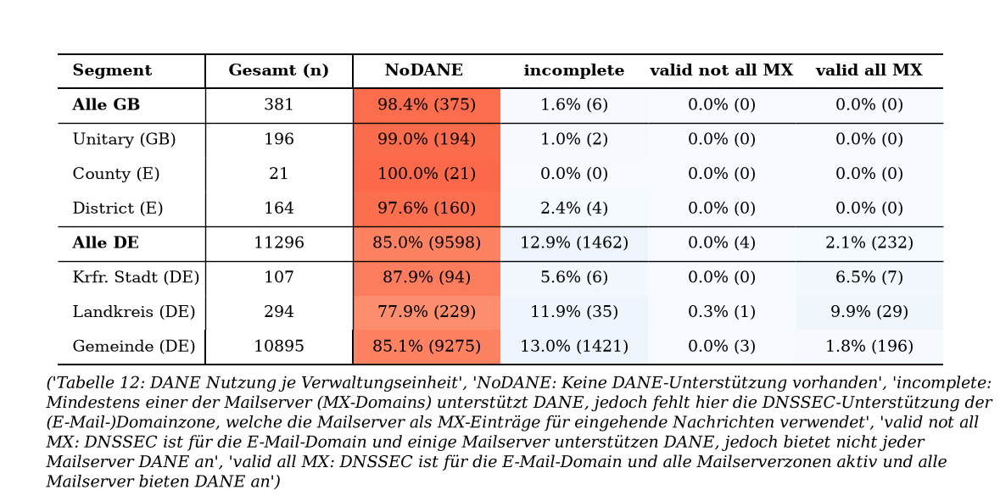

Tabelle erfolgreich gespeichert unter: abbildung_dane_uebersicht.png


In [111]:
metrics_dane = {
    "NoDANE ": lambda df:( 
        (df["daneResult_atLeastOneMtaSupportsDane"] == False) 
        & (df["daneResult_hasValidDaneAtLeastOneMta"] == False )
        & (df["daneResult_hasValidDaneAllMta"] == False))
     ,
    "incomplete": lambda df:( 
        (df["daneResult_atLeastOneMtaSupportsDane"] == True) 
        & (df["daneResult_hasValidDaneAtLeastOneMta"] == False )
        & (df["daneResult_hasValidDaneAllMta"] == False)
       #  & (df["dnssecResult_mxAtLeastOneDNSSEC"] == True)    
    )
    ,
    "valid not all MX": lambda df:( 
    (df["daneResult_atLeastOneMtaSupportsDane"] == True) 
    & (df["daneResult_hasValidDaneAtLeastOneMta"] == True )
    & (df["daneResult_hasValidDaneAllMta"] == False))
    ,
    "valid all MX": lambda df:( 
    (df["daneResult_atLeastOneMtaSupportsDane"] == True) 
    & (df["daneResult_hasValidDaneAtLeastOneMta"] == True )
    & (df["daneResult_hasValidDaneAllMta"] == True)
    )
}


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_dane = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_dane
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_dane,
    filename="abbildung_dane_uebersicht.png",
    red_keywords= ["noDANE"],
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 12: DANE Nutzung je Verwaltungseinheit", "NoDANE: Keine DANE-Unterstützung vorhanden", 
           "incomplete: Mindestens einer der Mailserver (MX-Domains) unterstützt DANE, jedoch fehlt hier die DNSSEC-Unterstützung der (E-Mail-)Domainzone, welche die Mailserver als MX-Einträge für eingehende Nachrichten verwendet", 
       "valid not all MX: DNSSEC ist für die E-Mail-Domain und einige Mailserver unterstützen DANE, jedoch bietet nicht jeder Mailserver DANE an", 
          "valid all MX: DNSSEC ist für die E-Mail-Domain und alle Mailserverzonen aktiv und alle Mailserver bieten DANE an"),
    caption_pos = -0.15
)







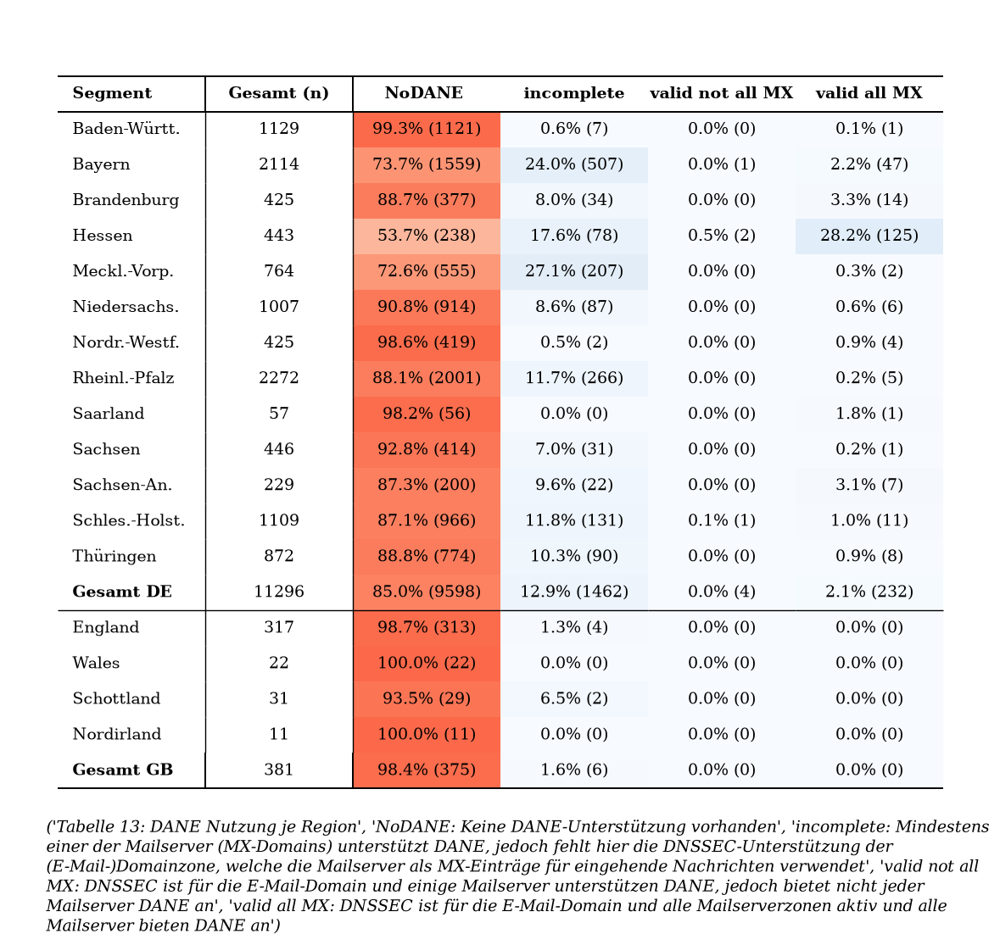

Tabelle erfolgreich gespeichert unter: abbildung_dane_uebersicht_region.png


In [112]:
#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_region_dane = generate_region_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_dane
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_region_dane,
    filename="abbildung_dane_uebersicht_region.png",
    red_keywords= ["noDANE"],
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 13: DANE Nutzung je Region", "NoDANE: Keine DANE-Unterstützung vorhanden", 
           "incomplete: Mindestens einer der Mailserver (MX-Domains) unterstützt DANE, jedoch fehlt hier die DNSSEC-Unterstützung der (E-Mail-)Domainzone, welche die Mailserver als MX-Einträge für eingehende Nachrichten verwendet", 
       "valid not all MX: DNSSEC ist für die E-Mail-Domain und einige Mailserver unterstützen DANE, jedoch bietet nicht jeder Mailserver DANE an", 
          "valid all MX: DNSSEC ist für die E-Mail-Domain und alle Mailserverzonen aktiv und alle Mailserver bieten DANE an"
              ),
    caption_pos = -0.07

)

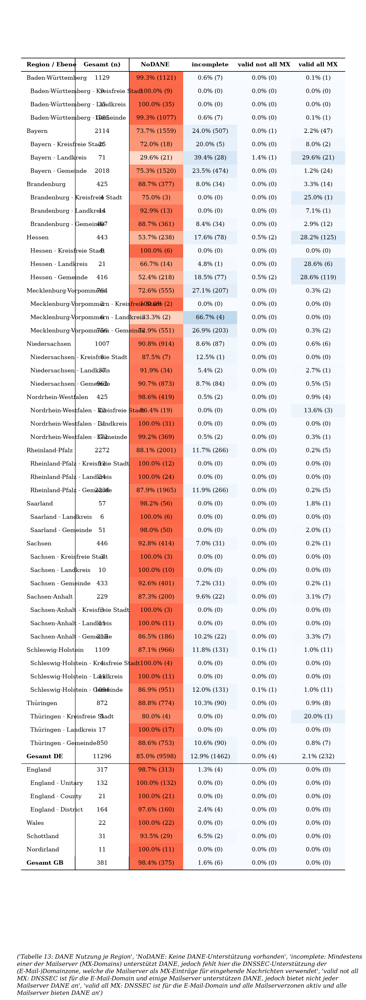

Tabelle erfolgreich gespeichert unter: abbildung_dane_uebersicht_region_all.png


In [113]:
#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_region_dane_all = generate_region_summary_all(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_dane
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_region_dane_all,
    filename="abbildung_dane_uebersicht_region_all.png",
    red_keywords= ["noDANE"],
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 13: DANE Nutzung je Region", "NoDANE: Keine DANE-Unterstützung vorhanden", 
           "incomplete: Mindestens einer der Mailserver (MX-Domains) unterstützt DANE, jedoch fehlt hier die DNSSEC-Unterstützung der (E-Mail-)Domainzone, welche die Mailserver als MX-Einträge für eingehende Nachrichten verwendet", 
       "valid not all MX: DNSSEC ist für die E-Mail-Domain und einige Mailserver unterstützen DANE, jedoch bietet nicht jeder Mailserver DANE an", 
          "valid all MX: DNSSEC ist für die E-Mail-Domain und alle Mailserverzonen aktiv und alle Mailserver bieten DANE an"
              ),
    caption_pos = -0.07

)

## TLSRPT

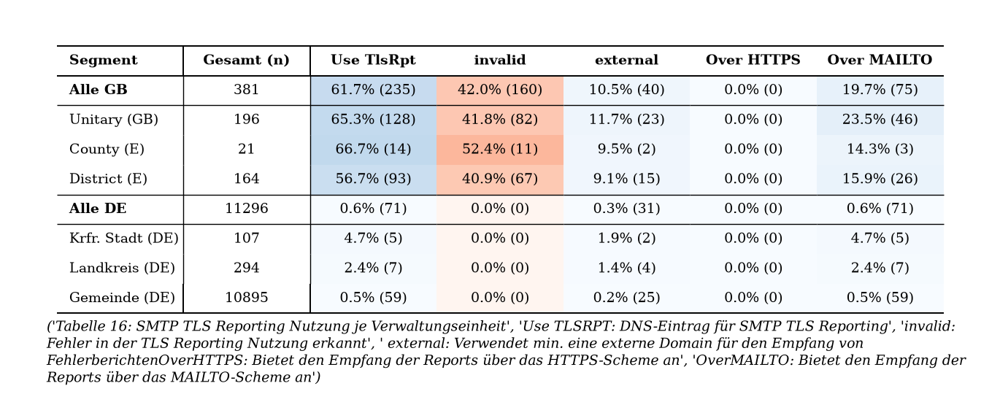

Tabelle erfolgreich gespeichert unter: abbildung_tls_rpt_uebersicht.png


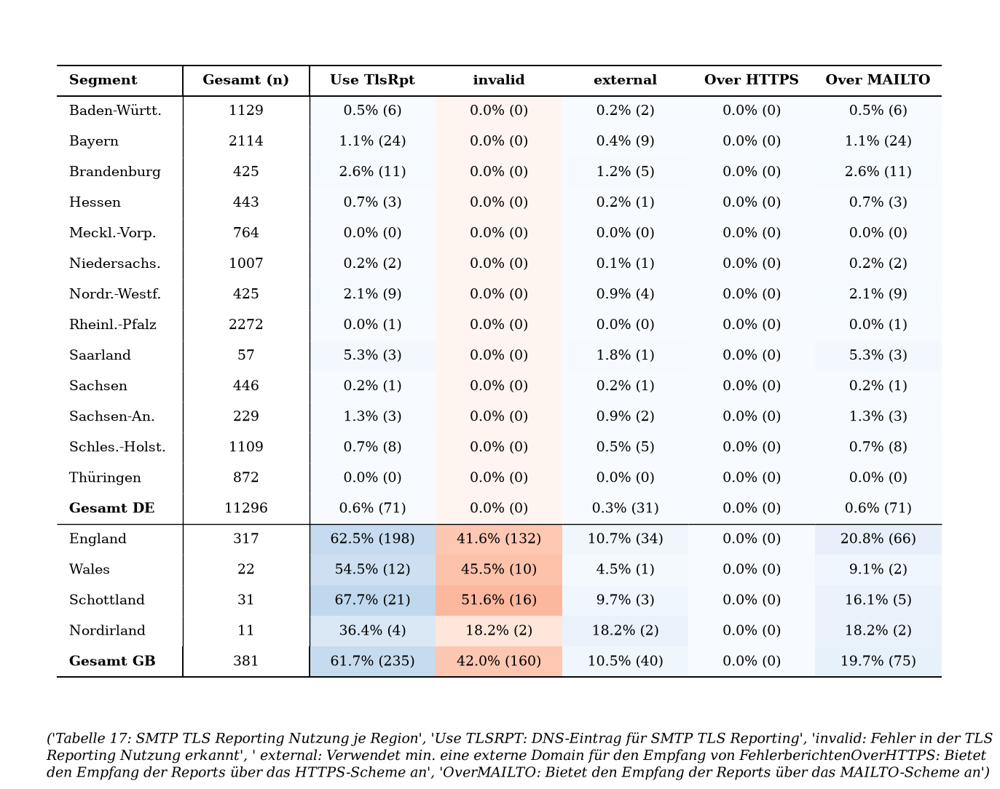

Tabelle erfolgreich gespeichert unter: abbildung_tls_rpt_uebersicht_region.png


In [114]:
metrics_tls_rpt = {
    "Use TlsRpt": lambda df:( 
        (df["tlsRptData_hasTlsrptDnsRecord"] == True ) 
        )
    ,

    "invalid": lambda df:( 
    (df["tlsRptData_hasTlsrptDnsRecord"] == True ) 
    & ~(df["tlsRptData_errorType"].isna() )
    )
    ,
    "external": lambda df:( 
    (df["tlsRptData_distinctExternalDomains"].astype(int)  > 0)
     
    )
    ,
    "Over HTTPS": lambda df:( 
    (df["tlsRptData_reportingOverHTTPS"].astype(int) > 0 ) 
    #& ~(df["tlsRptData_errorType"].isna() )
    )
    ,
    "Over MAILTO": lambda df:( 
    (df["tlsRptData_reportingOverMAILTO"].astype(int)  > 0  ) 
    #& ~(df["tlsRptData_errorType"].isna() )
    )
    
}


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_tls_rpt = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_tls_rpt
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_tls_rpt,
    filename="abbildung_tls_rpt_uebersicht.png",
    red_keywords= ["invalid"],
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
        caption = ("Tabelle 16: SMTP TLS Reporting Nutzung je Verwaltungseinheit", "Use TLSRPT: DNS-Eintrag für SMTP TLS Reporting", 
                   "invalid: Fehler in der TLS Reporting Nutzung erkannt", " external: Verwendet min. eine externe Domain für den Empfang von Fehlerberichten"
                   "OverHTTPS: Bietet den Empfang der Reports über das HTTPS-Scheme an",
                   "OverMAILTO: Bietet den Empfang der Reports über das MAILTO-Scheme an"
              ),
)


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_region_tls_rpt = generate_region_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_tls_rpt
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_region_tls_rpt,
    filename="abbildung_tls_rpt_uebersicht_region.png",
    red_keywords= ["invalid"],
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 17: SMTP TLS Reporting Nutzung je Region", "Use TLSRPT: DNS-Eintrag für SMTP TLS Reporting", 
               "invalid: Fehler in der TLS Reporting Nutzung erkannt", " external: Verwendet min. eine externe Domain für den Empfang von Fehlerberichten"
               "OverHTTPS: Bietet den Empfang der Reports über das HTTPS-Scheme an",
               "OverMAILTO: Bietet den Empfang der Reports über das MAILTO-Scheme an"
          ),
    caption_pos = -0.04

)

## Externe Abhängigkeiten

### GB

In [115]:
#df_gb_external = pd.read_csv('security_gb/external_dependencies.csv', sep=';', low_memory=False)

top_tlsrpt_provider_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'externalTlsReportDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)


top_tlsrpt_provider_cc_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='ipCountryCode',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'externalTlsReportDomain'
    #unique_filter_col=['usedByDomain', 'domain'],
)



print(top_tlsrpt_provider_gb)
anzahl_tlsrpt_ext_domain = df_de_external.loc[df_de_external['dependencyType'] == 'externalTlsReportDomain', 'code'].nunique()
print(anzahl_tlsrpt_ext_domain)


top_tlsrpt_cname_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'cnameTLSRPTDnsRecord',
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_tlsrpt_cname_gb)
anzahl_tlsrpt_ext_cname = df_de_external.loc[df_de_external['dependencyType'] == 'cnameTLSRPTDnsRecord', 'code'].nunique()
print(anzahl_tlsrpt_ext_cname)



         domain  Anzahl (n) Anteil (%) ipCountryCode
0   ondmarc.com          11      27.5%            US
1  uriports.com           6      15.0%            NL
2  dmarcian.com           5      12.5%            US
3        Gesamt          40     100.0%              
40
          domain  Anzahl (n) Anteil (%)
0     sdmarc.net           5      50.0%
1    ondmarc.com           4      40.0%
2  easydmarc.pro           1      10.0%
3         Gesamt          10     100.0%
10


### DE

In [ ]:
#df_gb = pd.read_csv(filepathgb, sep=';', low_memory=False)
#df_de_external = pd.read_csv('security_de/external_dependencies.csv', sep=';', low_memory=False)

top_tlsrpt_provider_de = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'externalTlsReportDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_tlsrpt_provider_de)

top_tlsrpt_provider_cc_de = get_top_frequencies(
    df=df_de_external,
    target_col='ipCountryCode',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'externalTlsReportDomain'
    #unique_filter_col=['usedByDomain', 'domain'],
)
print(top_tlsrpt_provider_cc_de)

top_tlsrpt_cname_de = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'cnameTLSRPTDnsRecord',
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_tlsrpt_cname_de)

In [ ]:
top_dmarc_error_gb_pre = top_tlsrpt_provider_gb.add_prefix('GB ')
top_dmarc_error_de_pre = top_tlsrpt_provider_de.add_prefix('DE ')


# Danach sicher zusammenfügen (ohne df1 zu überschreiben)
#ergebnis = df1.copy()
#ergebnis[df2_sicher.columns] = df2_sicher.to_numpy()
top_dmarc_error_degb = top_dmarc_error_de_pre.copy()
#df1[df2.columns] = df2.to_numpy()
top_dmarc_error_degb[top_dmarc_error_gb_pre.columns] = top_dmarc_error_gb_pre.to_numpy()

#top_dmarc_overview = pd.concat([top_dmarc, top_dmarc_gb], axis=1)
#print(top_dmarc)


ergebnis = render_table_to_image(
    top_dmarc_error_degb,
    filename="abbildung_dmarc_top_5.png",
    divider_rows=[3],  
    dpi=800,
    divider_cols=[3],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den DMARC-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    hide_index = True,
    font_size = 9,
    bold_rows = [3]

)

In [ ]:
df_de = pd.read_csv('security/data/gb/transport_data.csv', sep=';', low_memory=False)


top_tlsrpt_error_gb = get_top_frequencies(
    df=df_de,
    target_col="tlsRptData_errorType",
    top_n=3,
    row_filter=lambda df: (~df["tlsRptData_errorType"].isna()),
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code",
    col_name_aliases = { "tlsRptData_errorType" : "Fehlertyp" },
    value_aliases = {"ReportingDomainNoMXRecods":"E-Mail NoMXRecords"}#, "NotValidatedExternalReporting" : "NotValidatedExtReporting"}
)
print(top_tlsrpt_error_gb)


top_tlsrpt_error_gb_fixed = top_tlsrpt_error_gb.add_prefix('GB ')


In [ ]:
ergebnis = render_table_to_image(
    top_tlsrpt_error_gb_fixed,
    filename="abbildung_tlsrpt_top_3.png",
    divider_rows=[3],  
    dpi=800,
   # divider_cols=[2],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den TLSRPT-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["GB Anteil", "Fehlertyp"],
    hide_index = True,
    font_size = 11,
    bold_rows = [3]

)

## MTA-STS

In [ ]:

def isValidMtaSts(df):
    return ((df["mtaStsData_usesMtaSts"] == True ) & (df["mtaStsData_generalErrorType"].isna()))

metrics_mta_sts = {
    "Uses MTA-STS": lambda df:( 
        (df["mtaStsData_usesMtaSts"] == True ) 
        )
    ,

    "invalid": lambda df:( 
    (df["mtaStsData_usesMtaSts"] == True ) 
    & (~df["mtaStsData_generalErrorType"].isna() )
    )
    ,
    "strictPolicyIndent": lambda df:( 
    isValidMtaSts(df) & (df["certData_sanStrictIdentifierMatch"] == True  )
    )
    ,
    "none": lambda df:( 
    isValidMtaSts(df) & (df["policy_mode"] ==  "none")
    )
    ,
    "testing": lambda df:( 
    isValidMtaSts(df) & (df["policy_mode"] ==  "testing")
    )
    ,
    "enforce": lambda df:( 
    isValidMtaSts(df) & (df["policy_mode"] ==  "enforce")
    ),

}


#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_mta_sts = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_mta_sts
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_mta_sts,
    filename="abbildung_mta_sts_uebersicht_verwaltung.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 14: MTA-STS Nutzung je Verwaltungseinheit", "Uses MTA-STS: Mindestens der MTA-STS DNS-Eintrag ist vorhanden", 
       "invalid: MTA-STS ist fehlerhaft konfiguriert bzw. hat einen Fehler beim Abruf verursacht", 
       "strictPolicyIdent: Ein SAN-Eintrag (Domain) des Zertifikats der MTA-STS Policy stimmt vollständig mit der Domain der MTA-STS-Policy überein", 
      "none: Modus der MTA-STS-Policy ist none (inaktiv) ",
        "testing: Modus der MTA-STS-Policy ist testing (Zusammen mit TLSRPT nur für Monitoring-Zwecke genutzt) ",
        "enforce: Modus der MTA-STS-Policy ist enforce (Wenn senderseitige MTA-STS-Prüfung fehlschlägt, sollte die E-Mail nicht versendet werden"
          ),
    caption_pos = -0.1,
    red_keywords = ["invalid"]
    
)

In [ ]:
#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_region_mta_sts = generate_region_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_mta_sts
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_region_mta_sts,
    filename="abbildung_mta_sts_uebersicht_region.png",
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    caption = ("Tabelle 15: MTA-STS Nutzung je Region", "Uses MTA-STS: Mindestens der MTA-STS DNS-Eintrag ist vorhanden", 
       "invalid result: MTA-STS ist fehlerhaft konfiguriert", 
       "strictPolicyIdent: Ein SAN-Eintrag (Domain) des Zertifikats der MTA-STS Policy stimmt vollständig mit der Domain der MTA-STS-Policy überein", 
      "none: Modus der MTA-STS-Policy ist none (inaktiv) ",
        "testing: Modus der MTA-STS-Policy ist testing (Zusammen mit TLSRPT nur für Monitoring-Zwecke genutzt) ",
        "enforce: Modus der MTA-STS-Policy ist enforce (Wenn senderseitige MTA-STS-Prüfung fehlschlägt, sollte die E-Mail nicht versendet werden"
          ),
    caption_pos = -0.05,
    red_keywords = ["invalid"]
    
)

## MTA-STS-Fehler

In [10]:
df_de_transport = pd.read_csv('security/data/de/transport_data.csv', sep=';', low_memory=False)


top_mtasts_error_de = get_top_frequencies(
    df=df_de_transport,
    target_col="mtaStsData_generalErrorType",
    top_n=7,
    row_filter=lambda df: (~df["mtaStsData_generalErrorType"].isna()),
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code",
    col_name_aliases = { "mtaStsData_generalErrorType" : "Fehlertyp" },
    value_aliases = {"policyAtLeastOneMtaInvalid":"policyMinOneMtaInvalid"}
)
print(top_mtasts_error_de)



df_gb_transport = pd.read_csv('security/data/gb/transport_data.csv', sep=';', low_memory=False)


top_mtasts_error_gb = get_top_frequencies(
    df=df_gb_transport,
    target_col="mtaStsData_generalErrorType",
    top_n=7,
    row_filter=lambda df: (~df["mtaStsData_generalErrorType"].isna()),
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode'],
    pct_base_col = "code",
        col_name_aliases = { "mtaStsData_generalErrorType" : "Fehlertyp" },
    value_aliases = {"policyAtLeastOneMtaInvalid":"policyMinOneMtaInvalid"}
)
print(top_mtasts_error_gb)

                Fehlertyp  Anzahl (n) Anteil (%)
0    dnsRecordSyntaxError           4      26.7%
1    policydnsLookupError           3      20.0%
2          policyTlsError           3      20.0%
3     policyAllMtaInvalid           2      13.3%
4    policyRetrievalError           1       6.7%
5  policyMinOneMtaInvalid           1       6.7%
6       policySyntaxError           1       6.7%
7                  Gesamt          15     100.0%
                Fehlertyp  Anzahl (n) Anteil (%)
0          policyTlsError           9      32.1%
1    policyRetrievalError           5      17.9%
2       policySyntaxError           5      17.9%
3  policyMinOneMtaInvalid           4      14.3%
4          policyTcpError           2       7.1%
5     policyAllMtaInvalid           1       3.6%
6    dnsRecordSyntaxError           1       3.6%
7                  Gesamt          28     100.0%


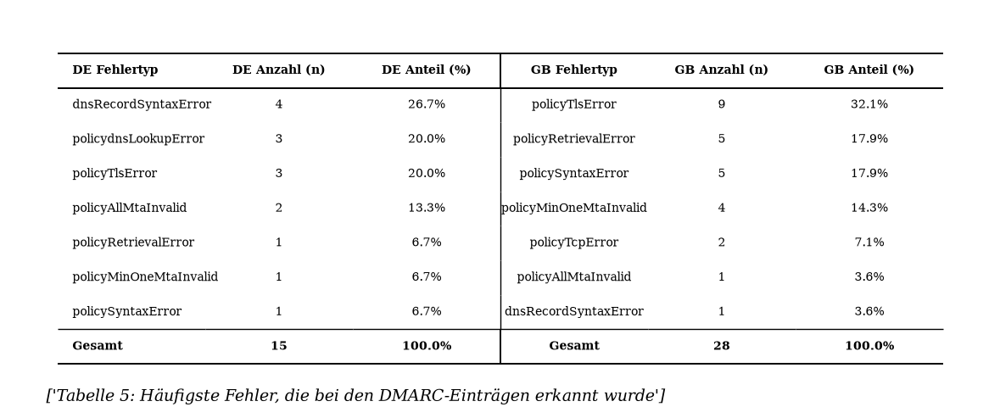

Tabelle erfolgreich gespeichert unter: abbildung_mta_sts_error_5.png


In [11]:


top_mtasts_error_gb_pre = top_mtasts_error_gb.add_prefix('GB ')
top_mtasts_error_de_pre = top_mtasts_error_de.add_prefix('DE ')




top_mtasts_error_degb = top_mtasts_error_de_pre.copy()

top_mtasts_error_degb[top_mtasts_error_gb_pre.columns] = top_mtasts_error_gb_pre.to_numpy()

#top_dmarc_overview = pd.concat([top_dmarc, top_dmarc_gb], axis=1)
#print(top_dmarc)


ergebnis = render_table_to_image(
    top_mtasts_error_degb,
    filename="abbildung_mta_sts_error_5.png",
    divider_rows=[7],  
    dpi=800,
    divider_cols=[2],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den DMARC-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    hide_index = True,
    font_size = 10,
    bold_rows = [7]

)


## Externe MTA-STS Abhängigkeiten

## Deutschland

In [ ]:
df_de_external = pd.read_csv('security/data/de/external_dependencies..csv', sep=';', low_memory=False)
df_gb_external = pd.read_csv('security/data/gb/external_dependencies..csv', sep=';', low_memory=False)
top_mta_sts_dnsrecord_cname = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=4,
    row_filter=lambda d: d['dependencyType'] == 'cnameMtaStsDnsRecord',
    #unique_filter_col=['usedByDomain', 'domain'],
    
)
print(top_mta_sts_dnsrecord_cname)
anz_top_mta_sts_dns_cname = df_de_external.loc[df_de_external['dependencyType'] == 'cnameMtaStsDnsRecord', 'code'].nunique()
print(anz_top_mta_sts_dns_cname)


top_mta_sts_policy_cname = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=4,
    row_filter=lambda d: d['dependencyType'] == 'cnameMTASTSPolicy',
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode']
    additional_cols=['ipCountryCode']
)
print(top_mta_sts_policy_cname)
anz_top_mta_sts_policy_cname = df_de_external.loc[df_de_external['dependencyType'] == 'cnameMTASTSPolicy', 'code'].nunique()
print(anz_top_mta_sts_policy_cname)

top_mta_sts_policy_ca = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=4,
    row_filter=lambda d: d['dependencyType'] == 'CASTSPolicy',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_mta_sts_policy_ca)
anz_top_mta_sts_policy_ca = df_de_external.loc[df_de_external['dependencyType'] == 'CASTSPolicy', 'code'].nunique()
print(anz_top_mta_sts_policy_ca)

## GB

In [ ]:
top_mta_sts_dnsrecord_cname_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=4,
    row_filter=lambda d: d['dependencyType'] == 'cnameMtaStsDnsRecord',
    #unique_filter_col=['usedByDomain', 'domain'],
    
)
print(top_mta_sts_dnsrecord_cname_gb)
anz_top_mta_sts_dns_cname_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'cnameMtaStsDnsRecord', 'code'].nunique()
print(anz_top_mta_sts_dns_cname_gb)


top_mta_sts_policy_cname_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=4,
    row_filter=lambda d: d['dependencyType'] == 'cnameMTASTSPolicy',
    unique_filter_col=['code'],
    #additional_cols=['ipCountryCode']
    additional_cols=['ipCountryCode']
)
print(top_mta_sts_policy_cname_gb)
anz_top_mta_sts_policy_cname_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'cnameMTASTSPolicy', 'code'].nunique()
print(anz_top_mta_sts_policy_cname_gb)

top_mta_sts_policy_ca_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=4,
    row_filter=lambda d: d['dependencyType'] == 'CASTSPolicy',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_mta_sts_policy_ca_gb)
anz_top_mta_sts_policy_ca_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'CASTSPolicy', 'code'].nunique()
print(anz_top_mta_sts_policy_ca_gb)

In [ ]:

top_mtasts_policyhost_gb_pre = top_mta_sts_policy_cname_gb.add_prefix('GB ')
top_mtasts_policyhost_de_pre = top_mta_sts_policy_cname.add_prefix('DE ')




top_mtasts_policyhost_degb = top_mtasts_policyhost_de_pre.copy()

top_mtasts_policyhost_degb[top_mtasts_policyhost_gb_pre.columns] = top_mtasts_policyhost_gb_pre.to_numpy()

#top_dmarc_overview = pd.concat([top_dmarc, top_dmarc_gb], axis=1)
#print(top_dmarc)


ergebnis = render_table_to_image(
    top_mtasts_policyhost_degb,
    filename="abbildung_mta_sts_ext_policyhost.png",
    divider_rows=[6],  
    dpi=800,
    divider_cols=[3],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den DMARC-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    hide_index = True,
    font_size = 10,
    bold_rows = [6]

)

In [ ]:
top_mtasts_dnsrecord_gb_pre = top_mta_sts_dnsrecord_cname_gb.add_prefix('GB ')
top_mtasts_dnsrecord_de_pre = top_mta_sts_dnsrecord_cname.add_prefix('DE ')




top_mtasts_dnsrecord_degb = top_mtasts_dnsrecord_de_pre.copy()

top_mtasts_dnsrecord_degb[top_mtasts_dnsrecord_gb_pre.columns] = top_mtasts_dnsrecord_gb_pre.to_numpy()

#top_dmarc_overview = pd.concat([top_dmarc, top_dmarc_gb], axis=1)
#print(top_dmarc)


ergebnis = render_table_to_image(
    top_mtasts_dnsrecord_degb,
    filename="abbildung_mta_sts_ext_dnsrecord.png",
    divider_rows=[6],  
    dpi=800,
    divider_cols=[2],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Index",
    caption = ["Tabelle 5: Häufigste Fehler, die bei den DMARC-Einträgen erkannt wurde"],
    caption_pos = 0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    hide_index = True,
    font_size = 10,
    bold_rows = [6]

)

## MTA-STS Korrelationen

In [ ]:
def isValidMtaSts(df):
    return ((df["mtaStsData_usesMtaSts"] == True ) & (df["mtaStsData_generalErrorType"].isna()))

metrics_mta_sts_dane = {
    "dane and mtasts": lambda df:( 
    isValidMtaSts(df)
    & (df["daneResult_hasValidDaneAtLeastOneMta"] == True )
    )
    ,
    "mtasts only": lambda df:( 
    isValidMtaSts(df) 
    & (df["daneResult_hasValidDaneAtLeastOneMta"] == False)
    )
    ,
    "dane only": lambda df:( 
    (~isValidMtaSts(df)) & (df["daneResult_hasValidDaneAtLeastOneMta"] == True )
    )
}

#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_mta_sts_dane = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_mta_sts_dane
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_mta_sts_dane,
    filename="abbildung_mta_sts_uebersicht.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)


In [ ]:
# Korrelation valider tls rpt und mta sts implementierungen

def isValidMtaSts(df):
    return ((df["mtaStsData_usesMtaSts"] == True ) & (df["mtaStsData_generalErrorType"].isna()))

def isValidTlsRpt(df):
    return (df["tlsRptData_hasTlsrptDnsRecord"] == True ) & (df["tlsRptData_errorType"].isna() )

metrics_mta_sts_tlsrpt = {
    
    "mtasts": lambda df:(
    isValidMtaSts(df) )
    ,
    "tlsrpt": lambda df:( 
    isValidTlsRpt(df))
    ,
    "tlsrpt and mta sts": lambda df:(   
    isValidTlsRpt(df)
    & 
    isValidMtaSts(df))
    ,
    "tlsrpt only": lambda df:(   
    isValidTlsRpt(df)
    & 
    (~isValidMtaSts(df)))
    ,
    "mta sts only": lambda df:(   
    (~isValidTlsRpt(df))
    & 
    isValidMtaSts(df))
}

#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_mta_sts_tlsrpt = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=metrics_mta_sts_tlsrpt
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_mta_sts_tlsrpt,
    filename="abbildung_mta_sts_uebersicht.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

## STARTTLS OLD

In [ ]:
# Korrelation valider tls rpt und mta sts implementierungen

def isValidMtaSts(df):
    return ((df["mtaStsData_usesMtaSts"] == True ) & (df["mtaStsData_generalErrorType"].isna()))

def isValidTlsRpt(df):
    return (df["tlsRptData_hasTlsrptDnsRecord"] == True ) & (df["tlsRptData_errorType"].isna() )

def isValidTlsVer(df):
    return  (df["tlsVersionData_allValidTlsResult"] == True)


tls_cert_test = {
    "Valid Tls result":lambda df:(
    isValidTlsVer(df) 
    ),
    "TLS Cert one": lambda df:(
    (df["tlsCertData_atLeastOneMxValidTlsResult"]  == True ) & isValidTlsVer(df)
    )
    ,
    "TLS Cert all": lambda df:( 
    isValidTlsVer(df) & (df["tlsCertData_allMxValidTlsResult"]  == True )
    )
}

#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_tls_cert_test = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=tls_cert_test
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_tls_cert_test,
    filename="abbildung_tls_cert_test_uebersicht.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)





In [ ]:
tls_12_test = {
    "Valid Result":lambda df:(
    isValidTlsVer(df) 
    ),
    "Valid TLS Result": lambda df:(
    (df["tlsCertData_atLeastOneMxValidTlsResult"]  == True ) & isValidTlsVer(df)
    )
    ,
    "valides STARTTLS alle": lambda df:( 
    isValidTlsVer(df) & (df["tlsCertData_allMxValidTlsResult"]  == True )
    )
    ,
    "1.2 Check teilw.": lambda df:(   
    (df["tls12Result_partlyValidTls12AtLeastOneMta"]  == True ) & isValidTlsVer(df)
    )
    ,  
    "1.2 Check alle": lambda df:(   
    (df["tls12Result_partlyValidTls12AllMta"] == True) & isValidTlsVer(df)
    )
    ,  
    "1.2 Check all teilw.": lambda df:(   
    (df["tls12Result_validTls12AtLeastOneMta"] == True) & isValidTlsVer(df)
    )
}


## Mindestens ein MX besitzt Fehler

In [41]:
import pandas as pd

# 1. Rohdaten laden (Referenz auf deine Datei)
df_gb_mx_raw = pd.read_csv("security/data/gb/mx_data.csv", sep=";") 

# 2. Fehler-Bedingung definieren 
# Annahme: SAN-Mismatch bedeutet, sanDnsMatch ist explizit False
df_gb_mx_raw['has_san_mismatch'] = df_gb_mx_raw['errorType'] == 'SANMismatch'

# 3. Auf einzigartige Kommunen (Code) aggregieren
df_gb_aggregated = df_gb_mx_raw.groupby('code', as_index=False).agg({
    'tier_id': 'first',           # Die Tier-ID ist pro Kommune identisch, 'first' reicht also
    'has_san_mismatch': 'any'     # True, sobald mindestens ein Mailserver ein Mismatch hat
})

              Gesamt (n) Kommunen mit >= 1 SAN-Mismatch
Segment                                                
Alle GB              382                      2.9% (11)
Unitary (GB)         197                       1.0% (2)
County (E)            21                       0.0% (0)
District (E)         164                       5.5% (9)


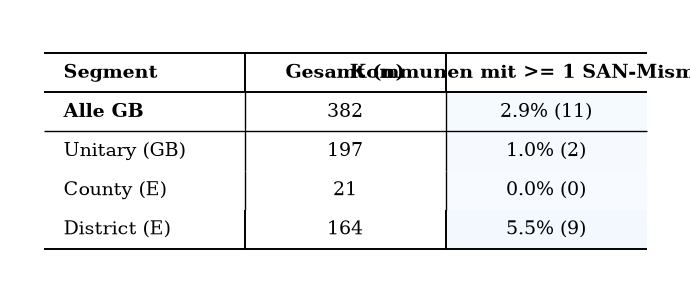

Tabelle erfolgreich gespeichert unter: abbildung_tls_sanMismatchTest.png


In [42]:
# 4. Metrik definieren
metrics = {
    "Kommunen mit >= 1 SAN-Mismatch": lambda df: df['has_san_mismatch'] == True
}

# 5. Funktion ausführen
ergebnis_tabelle = generate_tier_summary(
    df_gb=df_gb_aggregated, 
    df_de=None,  # Falls du DE-Daten hast, müsstest du diese analog vorab aggregieren
    metrics=metrics, 
    mode="pct_count" 
)

print(ergebnis_tabelle)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    ergebnis_tabelle,
    filename="abbildung_tls_sanMismatchTest.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)

In [43]:


# Fehler-Bedingung auf Mailserver-Ebene definieren
df_gb_mx_raw['has_san_mismatch'] = df_gb_mx_raw['sanDnsMatch'] == False

# Auf einzigartige Kommunen (Code) aggregieren - HIER IST DIE ÄNDERUNG
df_gb_aggregated = df_gb_mx_raw.groupby('code', as_index=False).agg({
    'tier_id': 'first',           
    'has_san_mismatch': 'all'     # <- 'all': Nur True, wenn JEDER Mailserver der Kommune den Fehler hat
})

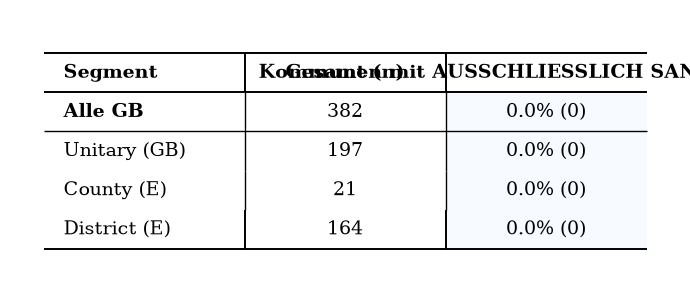

Tabelle erfolgreich gespeichert unter: abbildung_tls_sanMismatchAllTest.png


In [44]:
metrics = {
    "Kommunen mit AUSSCHLIESSLICH SAN-Mismatches": lambda df: df['has_san_mismatch'] == True
}

# 5. Funktion ausführen
ergebnis_tabelle = generate_tier_summary(
    df_gb=df_gb_aggregated, 
    metrics=metrics, 
    mode="pct_count" 
)

render_table_to_image(
    ergebnis_tabelle,
    filename="abbildung_tls_sanMismatchAllTest.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
)


C:\Users\jorel\AppData\Local\Temp\ipykernel_41552\4088642389.py:132: DtypeWarning: Columns (0: tier_id) have mixed types. Specify dtype option on import or set low_memory=False.
  left= pd.read_csv("security/data/de/transport_data.csv", sep=";",dtype={'code': str}),


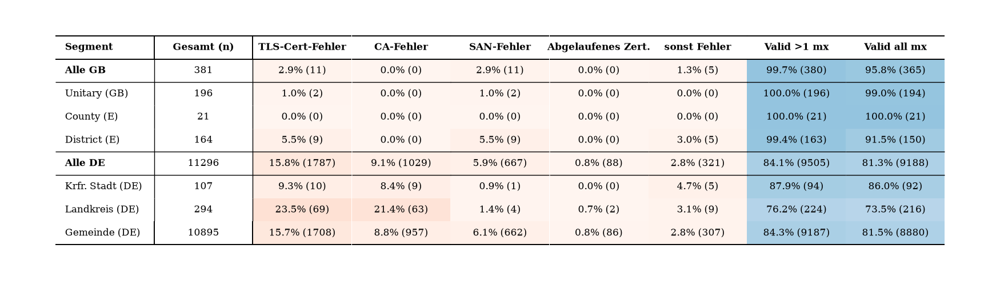

Tabelle erfolgreich gespeichert unter: abbildung_tls_cert_tier.png


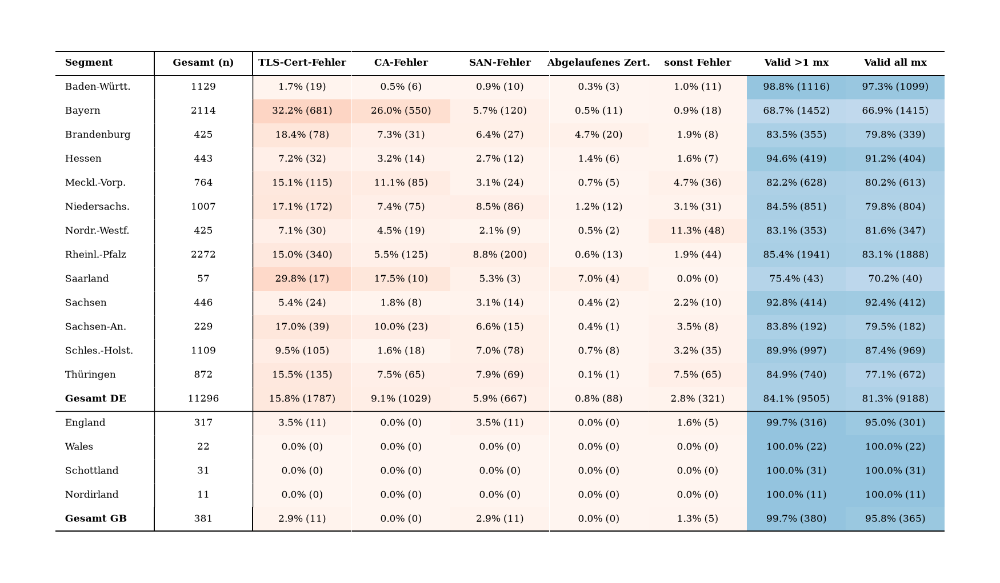

Tabelle erfolgreich gespeichert unter: abbildung_tls_cert_region.png


In [45]:
import pandas as pd

# 1. Rohdaten laden (low_memory=False unterdrückt die DtypeWarning und liest sauberer ein)
df_de_mx_raw = pd.read_csv(
    "security/data/de/mx_data.csv", 
    sep=";", 
    dtype={'code': str, 'tier_id': str}, # Erzwingt Text-Format für beide Problemspalten
    low_memory=False 
)

df_de_transport = pd.read_csv(
    "security/data/de/transport_data.csv", 
    sep=";", 
    dtype={'code': str, 'tier_id': str},
    low_memory=False
)
# 1. Rohdaten laden


# Code-Spalte radikal säubern und auf 8 Stellen (mit Nullen) formatieren
# Entfernt Leerzeichen und .0-Endungen, füllt dann mit Nullen auf.
df_de_mx_raw['code'] = df_de_mx_raw['code'].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()


    
# chlaues Auffüllen von führenden Nullen (für DE-Schlüssel)
def fix_de_code(c):
    if not c.isnumeric():
        return c
    if len(c) == 7: # Westdeutsche Gemeinde (Null fehlt) -> 8 Stellen
        return "0" + c
    if len(c) == 4: # Westdeutscher Landkreis (Null fehlt) -> 5 Stellen
        return "0" + c
    return c # Bereits 8 oder 5 Stellen (oder etwas anderes)

df_de_mx_raw['code'] = df_de_mx_raw['code'].apply(fix_de_code)


#df_de_mx_raw['code'] = df_de_mx_raw['code'].apply(lambda x: x.zfill(8) if x.isnumeric() else x)

df_de_transport['code'] = df_de_transport['code'].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()


# 2. Liste der 3-4 relevanten Fehlerkategorien definieren
relevante_fehler = ['RootCAUntrusted', 'SANMismatch', 'SSLHandshakeException: (handshake_failure) Received fatal alert: handshake_failure', 'UnsupportedProtocolVersion','ExpiredCertificate']

hat_fehler = df_de_mx_raw['errorType'].notna()
ist_nicht_ausgeschlossen = ~df_de_mx_raw['errorType'].isin(relevante_fehler)

# Mailserver hat einen dieser Fehler
df_de_mx_raw['has_target_error'] = df_de_mx_raw['errorType'].isin(relevante_fehler)
df_de_mx_raw['root_ca_error'] = df_de_mx_raw['errorType'] == "RootCAUntrusted"
df_de_mx_raw['expired_ca_error'] = df_de_mx_raw['errorType'] == "ExpiredCertificate"
df_de_mx_raw['san_mismatch_ca_error'] = df_de_mx_raw['errorType'] == "SANMismatch"
df_de_mx_raw['has_other_error'] = hat_fehler & ist_nicht_ausgeschlossen

# 4. Aggregation: 'any' prüft, ob MINDESTENS EIN Mailserver der Kommune True ist
df_de_aggregated = df_de_mx_raw.groupby('code', as_index=False).agg({
    'tier_id': 'first',           
    'has_target_error': 'any' ,  
    'root_ca_error' : 'any',
    'expired_ca_error' : 'any',
    'san_mismatch_ca_error' : 'any',
    'has_other_error' :'any'
})

# Strikte Trennung zwischen Zertifikatsfehler und sonstigen Fehlern
df_de_aggregated['has_other_error'] = df_de_aggregated['has_other_error'] & ~df_de_aggregated['has_target_error']

# 5. Joinen
df_joined_de = pd.merge(
    left=df_de_transport, 
    right=df_de_aggregated[['code', 'has_other_error', 'has_target_error','root_ca_error', 'san_mismatch_ca_error', 'expired_ca_error']], 
    on='code', 
    how='left'
)

#GB 

# Rohdaten laden (Referenz auf deine Datei)
df_gb_mx_raw = pd.read_csv("security/data/gb/mx_data.csv", sep=";", dtype={'code': str}) 
#  Liste der TLS-Spezifischen Fehlermeldungen
relevante_fehler_gb = ['RootCAUntrusted', 'SANMismatch', 'SSLHandshakeException: (handshake_failure) Received fatal alert: handshake_failure', 'UnsupportedProtocolVersion','ExpiredCertificate']


hat_fehler_gb = df_gb_mx_raw['errorType'].notna() #& (df_de_mx_raw['errorType'] != '')

# Prüfen ob der fehler nicht in der Ausschlussliste steht
ist_nicht_ausgeschlossen_gb = ~df_gb_mx_raw['errorType'].isin(relevante_fehler_gb)



#  Mailserver hat einen dieser Fehler
df_gb_mx_raw['has_target_error'] = df_gb_mx_raw['errorType'].isin(relevante_fehler_gb)
df_gb_mx_raw['root_ca_error'] = df_gb_mx_raw['errorType'] == "RootCAUntrusted"
df_gb_mx_raw['expired_ca_error'] = df_gb_mx_raw['errorType'] == "ExpiredCertificate"
df_gb_mx_raw['san_mismatch_ca_error'] = df_gb_mx_raw['errorType'] == "SANMismatch"
df_gb_mx_raw['has_other_error'] = hat_fehler_gb & ist_nicht_ausgeschlossen_gb

#df_de_mx_raw['code'] = df_de_mx_raw['code'].apply(lambda x: str(x).zfill(8) if pd.notna(x) and str(x).isnumeric() else str(x))

#  Aggregation prüft, ob MINDESTENS EIN Mailserver der Kommune True ist
df_gb_aggregated = df_gb_mx_raw.groupby('code', as_index=False).agg({
    'tier_id': 'first',           
    'has_target_error': 'any' ,  
    'root_ca_error' : 'any',
    'expired_ca_error' : 'any',
    'san_mismatch_ca_error' : 'any',
    'has_other_error' :'any'
})

df_gb_aggregated['has_other_error'] = (df_gb_aggregated['has_other_error']) & ~(df_gb_aggregated['has_target_error'])


metrics_tlscert_error = {
    "TLS-Cert-Fehler": lambda df: df['has_target_error'] == True,
    
    "CA-Fehler" : lambda df: df['root_ca_error'] == True,
    "SAN-Fehler": lambda df:  df['san_mismatch_ca_error'] == True,
    "Abgelaufenes Zert.": lambda df:  df['expired_ca_error'] == True,
    "sonst Fehler": lambda df: df['has_other_error'] == True,
    "Valid >1 mx": lambda df:(
    (df["tlsCertData_atLeastOneMxValidTlsResult"]  == True ) )
    ,
    "Valid all mx": lambda df:( 
     (df["tlsCertData_allMxValidTlsResult"]  == True )
    )
}


df_joined_de = pd.merge(
    left= pd.read_csv("security/data/de/transport_data.csv", sep=";",dtype={'code': str}), 
    right= df_de_aggregated[['code', 'has_other_error', 'has_target_error','root_ca_error', 'san_mismatch_ca_error', 'expired_ca_error']], # Nur 'code' und die neue Flag-Spalte nehmen
    on='code', 
    how='left'
)

df_joined_gb = pd.merge(
    left= pd.read_csv("security/data/gb/transport_data.csv", sep=";",dtype={'code': str}), 
    right= df_gb_aggregated[['code', 'has_other_error', 'has_target_error','root_ca_error', 'san_mismatch_ca_error', 'expired_ca_error']], # Nur 'code' und die neue Flag-Spalte nehmen
    on='code', 
    how='left'
)

# 5. Funktion ausführen
ergebnis_tlscert_tier = generate_tier_summary(
    df_de=df_joined_de, 
    df_gb =df_joined_gb,
    metrics=metrics_tlscert_error, 
    mode="pct_count" 
)

render_table_to_image(
    ergebnis_tlscert_tier,
    filename="abbildung_tls_cert_tier.png",
    red_keywords = ["TLS-Cert-Fehler","Abgelaufenes Zert.","SAN-Fehler","CA-Fehler", "sonst Fehler" ],
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    font_size = 12
)



ergebnis_tlscert_region = generate_region_summary(
    df_gb=df_joined_gb,
    df_de=df_joined_de,
    metrics=metrics_tlscert_error
    
)
render_table_to_image(
    ergebnis_tlscert_region,
    filename="abbildung_tls_cert_region.png",
    red_keywords = ["TLS-Cert-Fehler","Abgelaufenes Zert.","SAN-Fehler","CA-Fehler", "sonst Fehler" ],
    #divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    font_size = 12
)



## Default TLS

C:\Users\jorel\AppData\Local\Temp\ipykernel_41552\2638123088.py:11: DtypeWarning: Columns (0: tier_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df_mx = pd.read_csv(mx_path, sep=";")
C:\Users\jorel\AppData\Local\Temp\ipykernel_41552\2638123088.py:48: DtypeWarning: Columns (0: tier_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df_transport = pd.read_csv(transport_path, sep=";")


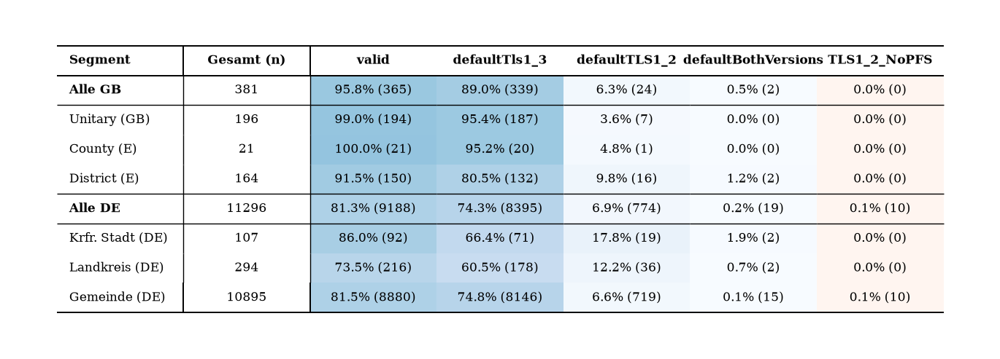

Tabelle erfolgreich gespeichert unter: abbildung_tls_versionen.png


In [46]:
import pandas as pd
from typing import Union
from pathlib import Path

def prepare_tls_version_data(mx_path: Union[str, Path], transport_path: Union[str, Path]) -> pd.DataFrame:
    """
    Lädt MX-Daten, berechnet TLS-Versionen (1.2 / 1.3) und Cipher-Suites (PFS)
    auf Kommunen-Ebene und joint diese an die Transport-Daten.
    """
    # 1. Rohdaten laden
    df_mx = pd.read_csv(mx_path, sep=";")
    
    # 2. Bedingungen auf Mailserver-Ebene prüfen
    df_mx['valid'] = (df_mx['errorType'].isna()) | (df_mx['errorType'] == "")
    df_mx['defaultTls1_3'] = df_mx['defaultTlsVersion'] == "TLSv1.3"
    df_mx['defaultTls1_2'] = df_mx['defaultTlsVersion'] == "TLSv1.2"
    
    # PFS (Perfect Forward Secrecy) Prüfung: TLS 1.2 OHNE ECDHE oder DHE
    df_mx['TLS1_2_NoPFS'] = (
        (df_mx['valid']) & 
        (df_mx['defaultTlsVersion'] == "TLSv1.2") & 
        ~((df_mx['defaultCipherSuite'].fillna('').astype(str).str.startswith("TLS_ECDHE")) |
        (df_mx['defaultCipherSuite'].fillna('').astype(str).str.startswith("TLS_DHE")))
    )
    df_de_mx_raw['code'] = df_de_mx_raw['code'].apply(lambda x: str(x).zfill(8) if pd.notna(x) and str(x).isnumeric() else str(x))
    # 3. Aggregation auf Kommunen-Ebene (groupby code)
    df_aggregated = df_mx.groupby('code', as_index=False).agg({
        'tier_id': 'first',           
        'valid': 'all',         # Nur valide, wenn ALLE Server der Kommune valide sind
        'defaultTls1_3': 'any', # True, wenn min. ein Server 1.3 spricht
        'defaultTls1_2': 'any', # True, wenn min. ein Server 1.2 spricht
        'TLS1_2_NoPFS': 'any'   # True, wenn min. ein Server 1.2 ohne PFS spricht
    })

    # 4. Überschneidungen auf Kommunen-Ebene auflösen 
    # (WICHTIG: Hier arbeiten wir ausschließlich auf df_aggregated!)
    df_aggregated['defaultBothVersions'] = (df_aggregated['valid']) & (df_aggregated['defaultTls1_2']) & (df_aggregated['defaultTls1_3'])
    
    # Wenn "Both" True ist, dürfen sie in der Einzelzählung nicht mehr auftauchen, 
    # sonst wird die Kommune doppelt gezählt (z.B. bei 1.2 und 1.3).
    df_aggregated['defaultTls1_3'] = (df_aggregated['valid']) & (df_aggregated['defaultTls1_3']) & (~df_aggregated['defaultBothVersions'])
    df_aggregated['defaultTls1_2'] = (df_aggregated['valid']) & (df_aggregated['defaultTls1_2']) & (~df_aggregated['defaultBothVersions'])

    # Auch TLS1_2_NoPFS macht nur bei validen Kommunen Sinn (falls du das so möchtest)
    df_aggregated['TLS1_2_NoPFS'] = df_aggregated['valid'] & df_aggregated['TLS1_2_NoPFS']

    # 5. An Transport-Tabelle joinen
    df_transport = pd.read_csv(transport_path, sep=";")
    df_joined = pd.merge(
        left=df_transport, 
        right=df_aggregated[['code', 'valid', 'defaultTls1_3', 'defaultTls1_2', 'defaultBothVersions', 'TLS1_2_NoPFS']], 
        on='code', 
        how='left'
    )
    
    return df_joined


def generate_tls_version_report():
    # 1. Daten für beide Länder aufbereiten (nutzt unsere Hilfsfunktion)
    df_joined_de = prepare_tls_version_data(
        "security/data/de/mx_data.csv", 
        "security/data/de/transport_data.csv"
    )
    df_joined_gb = prepare_tls_version_data(
        "security/data/gb/mx_data.csv", 
        "security/data/gb/transport_data.csv"
    )

    # 2. Metriken für die Summary-Tabelle definieren
    metrics_tls_versions_cert = {
        "valid": lambda df: df['valid'] == True,
        "defaultTls1_3": lambda df: df['defaultTls1_3'] == True,
        "defaultTLS1_2": lambda df: df['defaultTls1_2'] == True,
        "defaultBothVersions": lambda df: df['defaultBothVersions'] == True,
        "TLS1_2_NoPFS": lambda df: df['TLS1_2_NoPFS'] == True
    }

    # 3. Summary-Tabelle generieren
    ergebnis_tabelle_tlscert = generate_tier_summary(
        df_de=df_joined_de, 
        df_gb=df_joined_gb,
        metrics=metrics_tls_versions_cert, 
        mode="pct_count" 
    )

    # 4. Bild rendern (Achtung: red_keywords habe ich angepasst, da es in diesem Kontext keine Zertifikatsfehler mehr gibt)
    render_table_to_image(
        ergebnis_tabelle_tlscert,
        filename="abbildung_tls_versionen.png",
        red_keywords=["TLS1_2_NoPFS"], # Hier macht nur noch NoPFS als Warnfarbe Sinn
        divider_rows=[1, 4, 5],  
        dpi=800,
        font_size=12
    )
generate_tls_version_report()





## TLS 1.2 GB

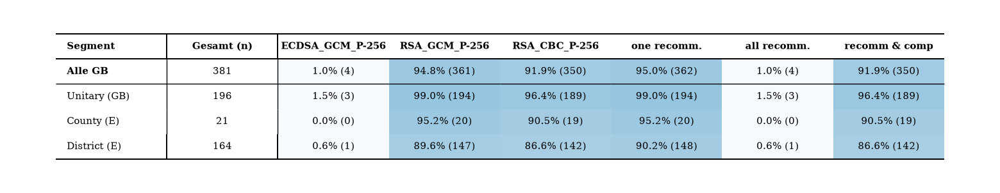

Tabelle erfolgreich gespeichert unter: abbildung_tls_12.png


In [47]:
#GB 

# Rohdaten laden (Referenz auf deine Datei)
df_gb_mx_raw = pd.read_csv("security/data/gb/mx_data.csv", sep=";") 


df_gb_mx_raw['ECDSA_GCM_P-256'] = df_gb_mx_raw['tls12Results_Recommended_ECDSA_GCM_P-256_isValid'] == True
df_gb_mx_raw['RSA_GCM_P-256'] = df_gb_mx_raw['tls12Results_Recommended_RSA_GCM_P-256_isValid'] == True
df_gb_mx_raw['RSA_CBC_P-256'] = df_gb_mx_raw['tls12Results_Compatibility_RSA_CBC_P-256_isValid'] == True
df_gb_mx_raw['one_recommended'] = (df_gb_mx_raw['tls12Results_Recommended_RSA_GCM_P-256_isValid'] == True) | (df_gb_mx_raw['tls12Results_Recommended_ECDSA_GCM_P-256_isValid'] == True)
df_gb_mx_raw['all_recommended'] = (df_gb_mx_raw['tls12Results_Recommended_RSA_GCM_P-256_isValid'] == True) & (df_gb_mx_raw['tls12Results_Recommended_ECDSA_GCM_P-256_isValid'] == True)
df_gb_mx_raw['recomm_comp'] =  (df_gb_mx_raw['tls12Results_Compatibility_RSA_CBC_P-256_isValid'] == True) & ((df_gb_mx_raw['tls12Results_Recommended_RSA_GCM_P-256_isValid'] == True) | (df_gb_mx_raw['tls12Results_Recommended_ECDSA_GCM_P-256_isValid'] == True))



#  Aggregation
df_gb_aggregated = df_gb_mx_raw.groupby('code', as_index=False).agg({
    'tier_id': 'first',           
    'ECDSA_GCM_P-256': 'all' ,  
    'RSA_GCM_P-256' : 'all',
    'RSA_CBC_P-256' : 'all',
    'one_recommended' : 'all',
    'all_recommended' :'all',
    'recomm_comp' : 'all'
})

#df_one_comp_profile['has_other_error'] = df_gb_aggregated['has_other_error'] & ~df_gb_aggregated['has_target_error']


metrics_tls12 = {
    "ECDSA_GCM_P-256": lambda df: df['ECDSA_GCM_P-256'] == True,
    "RSA_GCM_P-256" : lambda df: df['RSA_GCM_P-256'] == True,
    "RSA_CBC_P-256": lambda df:  df['RSA_CBC_P-256'] == True,
    "one recomm.": lambda df:  df['one_recommended'] == True,
    "all recomm.": lambda df: df['all_recommended'] == True,
    "recomm & comp" : lambda df: df['recomm_comp'] == True 
}


df_joined_gb = pd.merge(
    left= pd.read_csv("security/data/gb/transport_data.csv", sep=";"), 
    right= df_gb_aggregated[['code', 'ECDSA_GCM_P-256', 'RSA_GCM_P-256','RSA_CBC_P-256', 'one_recommended', 'all_recommended', 'recomm_comp']],
    on='code', 
    how='left'
)


ergebnis_tabelle = generate_tier_summary(
    df_gb =df_joined_gb,
    metrics=metrics_tls12, 
    mode="pct_count" 
)

render_table_to_image(
    ergebnis_tabelle,
    filename="abbildung_tls_12.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
    font_size = 11
)


Abgerundet TLS-Versionsergebnisse für 78% aller deutschen Kommunen

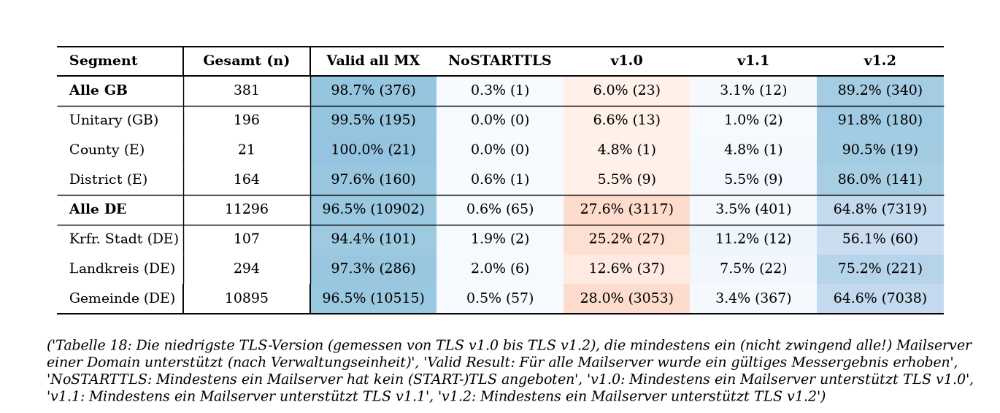

Tabelle erfolgreich gespeichert unter: abbildung_tls_version_test_uebersicht.png


In [8]:
# Korrelation valider tls rpt und mta sts implementierungen

def isValidTlsVer(df):
    return  (df["tlsVersionData_allValidTlsResult"] == True)



tls_version_test = {

    "Valid all MX":lambda df:(
    (isValidTlsVer(df))
    )
    ,  
    

    
    "NoSTARTTLS": lambda df:(   
    isValidTlsVer(df) & (df["tlsVersionData_minVersionAtLeastOneMta"] == "no_starttls" ) 
    )
    ,
    "v1.0": lambda df:(   
    isValidTlsVer(df) & (df["tlsVersionData_minVersionAtLeastOneMta"] == "tls1" ) 
    )
    ,  
    "v1.1": lambda df:(   
    isValidTlsVer(df) & (df["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_1")
    )
    ,  
    "v1.2": lambda df:(   
    isValidTlsVer(df) & (df["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2")
    )
}

#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_tls_version_test = generate_tier_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=tls_version_test
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_tls_version_test,
    filename="abbildung_tls_version_test_uebersicht.png",
    divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
        caption = (
        "Tabelle 18: Die niedrigste TLS-Version (gemessen von TLS v1.0 bis TLS v1.2), die mindestens ein Mailserver einer Domain unterstützt (nach Verwaltungseinheit)", 
        "Valid Result: Für alle Mailserver wurde ein gültiges Messergebnis erhoben", 
       "NoSTARTTLS: Mindestens ein Mailserver hat kein STARTTLS angeboten", 
       "v1.0: Mindestens ein Mailserver unterstützt TLS v1.0", 
      "v1.1: Mindestens ein Mailserver unterstützt TLS v1.1",
     "v1.2: Mindestens ein Mailserver unterstützt TLS v1.2"
          ),
    caption_pos = -0.1,
    red_keywords = ["no_starttls", "v1.0"]
)

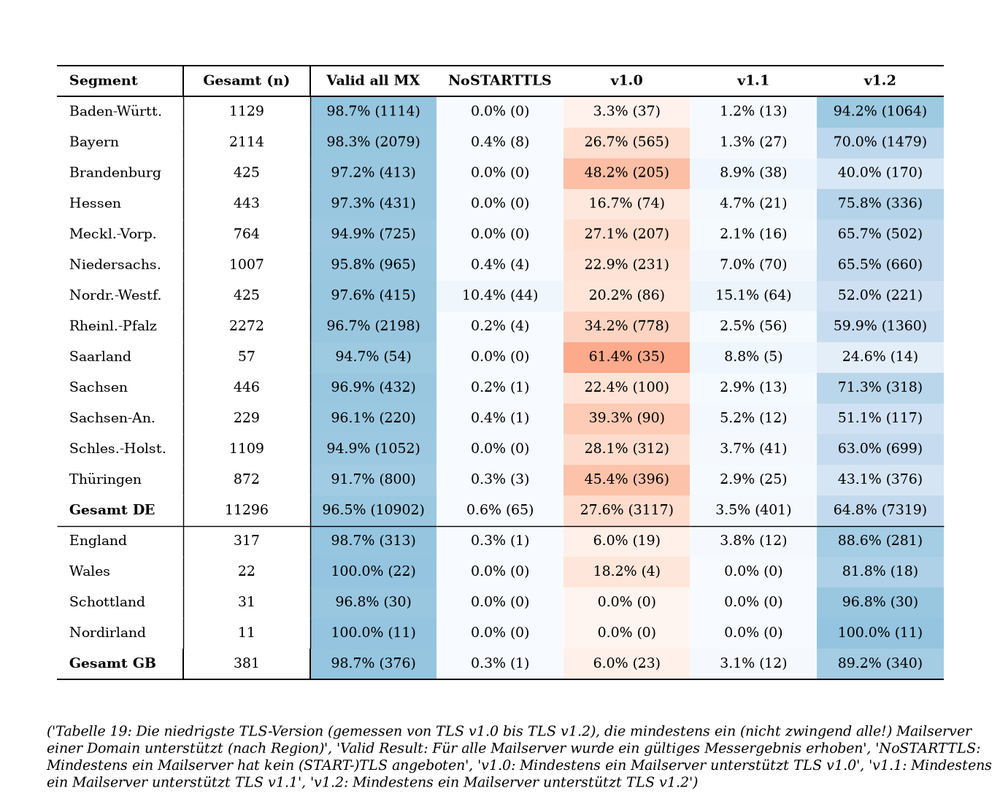

Tabelle erfolgreich gespeichert unter: abbildung_tls_version_region_uebersicht.png


In [9]:
#1. Zusammenfassung nach administrativen Ebenen erstellen
tbl_tiers_tls_version_test = generate_region_summary(
    df_gb="security/data/gb/transport_data.csv",
    df_de="security/data/de/transport_data.csv",
    metrics=tls_version_test
    
)

# 2. Hochauflösende Heatmap exportieren
render_table_to_image(
    tbl_tiers_tls_version_test,
    filename="abbildung_tls_version_region_uebersicht.png",
   # divider_rows=[1, 4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
        caption = ("Tabelle 19: Die niedrigste TLS-Version (gemessen von TLS v1.0 bis TLS v1.2), die mindestens ein (nicht zwingend alle!) Mailserver einer Domain unterstützt (nach Region)", 
                   "Valid Result: Für alle Mailserver wurde ein gültiges Messergebnis erhoben", 
       "NoSTARTTLS: Mindestens ein Mailserver hat kein (START-)TLS angeboten", 
       "v1.0: Mindestens ein Mailserver unterstützt TLS v1.0", 
      "v1.1: Mindestens ein Mailserver unterstützt TLS v1.1",
     "v1.2: Mindestens ein Mailserver unterstützt TLS v1.2"
          ),
    caption_pos = -0.05,
    red_keywords = ["no_starttls", "v1.0"]
)

## Externe Abhängigkeiten TLS-Cert

In [50]:
top_tls_mx_ca_de = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'CAMX',
    unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_tls_mx_ca_de)


top_tls_mx_ca_cc_de = get_top_frequencies(
    df=df_de_external,
    target_col='ipCountryCode',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'CAMX',
    unique_filter_col=['dependencyType','domain'],
    #additional_cols=['ipCountryCode']
)
print(top_tls_mx_ca_cc_de)

anz_top_tls_mx_ca_de = df_de_external.loc[df_de_external['dependencyType'] == 'CAMX', 'code'].value_counts()
top_ca_gesamt_de = (
    df_de_external.loc[df_de_external['dependencyType'] == 'CAMX', 'domain']
    .value_counts()
)
print(top_ca_gesamt_de)


top_ca_pro_kommune = (
    df_de_external[df_de_external['dependencyType'] == 'CAMX']
    .groupby('domain')['code']
    .nunique()
    .sort_values(ascending=False)
)

print(top_ca_pro_kommune)







# 1. Kommunen-Codes ermitteln, die > 1 unterschiedliche CAs haben
multi_ca_codes = (
    df[df['dependencyType'] == 'CAMX']
    .groupby('code')['domain']
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

# 2. Tabelle auf genau diese Fälle begrenzen
test_df = df[(df['dependencyType'] == 'CAMX') & (df['code'].isin(multi_ca_codes))]

                  domain  Anzahl (n) Anteil (%) ipCountryCode
0  Microsoft Corporation         219      57.6%            US
1           DigiCert Inc          85      22.4%            US
2        Sectigo Limited          36       9.5%            GB
3       GlobalSign nv-sa          18       4.7%            BE
4              IdenTrust           8       2.1%            US
5                 Gesamt         380     100.0%              
  ipCountryCode  Anzahl (n) Anteil (%)
0            US           8      72.7%
1            BE           1       9.1%
2            GB           1       9.1%
3            LV           1       9.1%
4        Gesamt          11     100.0%
domain
Microsoft Corporation           221
DigiCert Inc                     85
Sectigo Limited                  36
GlobalSign nv-sa                 19
IdenTrust                         8
Let's Encrypt                     6
Google Trust Services             4
GoDaddy.com                       1
GoGetSSL                          1
G

NameError: name 'df' is not defined

### GB

In [ ]:
top_tls_mx_ca_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'CAMX',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_tls_mx_ca_gb)
anz_top_tls_mx_ca_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'CAMX', 'code'].value_counts()
top_ca_gesamt_gb = (
    df_gb_external.loc[df_gb_external['dependencyType'] == 'CAMX', 'domain']
    .value_counts()
)
print(top_ca_gesamt_gb)


top_tls_mx_ca_cc_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='ipCountryCode',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'CAMX',
    #unique_filter_col=['usedByDomain', 'domain'],
    #additional_cols=['ipCountryCode']
)
print(top_tls_mx_ca_cc_gb)







## Metadaten

In [ ]:
top_mta_sts_policy_ca_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'CASTSPolicy',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_mta_sts_policy_ca_gb)
anz_top_mta_sts_policy_ca_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'CASTSPolicy', 'code'].nunique()
print(anz_top_mta_sts_policy_ca_gb)

In [ ]:
top_mta_sts_policy_ca_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'CASTSPolicy',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)
print(top_mta_sts_policy_ca_gb)
anz_top_mta_sts_policy_ca_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'CASTSPolicy', 'code'].nunique()
print(anz_top_mta_sts_policy_ca_gb)

In [ ]:
df_mx_de = pd.read_csv("security/data/de/mx_data.csv", sep=";", low_memory=False)


# Datei mit Semikolon als Trennzeichen einlesen
#df_mx_de = pd.read_csv('security/data/de/mx_data.csv', sep=';')

# Einzigartige Werte in der Spalte 'domain' zählen
#domain_count_de = df_mx_de['domain'].nunique()
#domain_count_de = df_mx_de['code'].nunique()
df_mx_gb = pd.read_csv("security/data/gb/mx_data.csv", sep=";", low_memory=False)

top_mta_sts_policy_ca_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=3,
    row_filter=lambda d: d['dependencyType'] == 'CASTSPolicy',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode']
)


## Domains Count GB

In [ ]:

df_anti_spoof_gb = pd.read_csv('security/data/gb/antispoofing_data.csv', sep=';')
# Einzigartige Werte in der Spalte 'domain' zählen

kommune_count_gb = df_anti_spoof_gb['code'].nunique()
print(f'GB Distinct Kommunen: {kommune_count_gb}')

# 1. Anz Domains
domain_count_gb = df_anti_spoof_gb['aggDomainAntiSpoofing_domain'].nunique()
print(f'GB Distinct Domains: {domain_count_gb}')


# Am öftesten verwendete Domains
get_top_frequencies(
    df=df_anti_spoof_gb,
    target_col='aggDomainAntiSpoofing_domain',
    top_n=3,
    unique_filter_col=['code'],
    additional_cols=['region']
)

## MX-Records GB

In [ ]:
# Anzahl an MX Records je Domains
countMxRecordDomain = get_top_frequencies(
    df=df_anti_spoof_gb,
    target_col='aggDomainAntiSpoofingMetadata_mxRecordCount',
    top_n=10,
    unique_filter_col=['code']
    #additional_cols=['region']
)
print(countMxRecordDomain)

df_mx_gb = pd.read_csv('security/data/gb/mx_data.csv', sep=';')

# Anzahl an Domains mit min einen MXRecord
mxRec_count_gb = df_mx_gb['mxRecord'].nunique()
print( mxRec_count_gb)


## External MX Records GB

In [ ]:
df_gb_external = pd.read_csv('security/data/gb/external_dependencies..csv', sep=';')
top_ext_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalMxDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode'],
    pct_base_col = 'code'
)
print(top_ext_gb)# Einzigartige Werte in der Spalte 'domain' zählen





## Domains DE Count

In [ ]:
# Einzigartige Werte in der Spalte 'domain' zählen
df_anti_spoof_de = pd.read_csv('security/data/de/antispoofing_data.csv', sep=';')
# Einzigartige Werte in der Spalte 'domain' zählen

#Anz Kommunen
kommune_count_de = df_anti_spoof_de['code'].nunique()
print(f'DE Distinct Kommunen: {kommune_count_de}')

# Anz Domains
domain_count_de = df_anti_spoof_de['aggDomainAntiSpoofing_domain'].nunique()
print(f'DE Distinct Domains: {domain_count_de}')


# Am öftesten verwendete Domains
get_top_frequencies(
    df=df_anti_spoof_de,
    target_col='aggDomainAntiSpoofing_domain',
    top_n=3,
    unique_filter_col=['code'],
    additional_cols=['region']
)

## MX-Records DE

In [51]:
# Anzahl an MX Records je Domains
countMxRecordDomain_de = get_top_frequencies(
    df=df_anti_spoof_de,
    target_col='aggDomainAntiSpoofingMetadata_mxRecordCount',
    top_n=10,
    unique_filter_col=['code']
    #additional_cols=['region']
)
print(countMxRecordDomain_de)

df_mx_de = pd.read_csv('security/data/de/mx_data.csv', sep=';')

# Anzahl an Domains mit min einen MXRecord
mxRec_count_de = df_mx_de['mxRecord'].nunique()
print( mxRec_count_gb)

NameError: name 'df_anti_spoof_de' is not defined

In [52]:
top_ext_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalMxDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode'],
    pct_base_col = 'code'
)
print(top_ext_gb)

NameError: name 'df_gb_external' is not defined

In [ ]:
mxRec_count_gb = df_mx_gb['mxRecord'].nunique()

print( mxRec_count_gb)
top_ext_gb = get_top_frequencies(
    df=df_gb_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalMxDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode'],
    pct_base_col = 'code'
)
print(top_ext_gb)# Einzigartige Werte in der Spalte 'domain' zählen
mxRec_count_de = df_mx_de['mxRecord'].nunique()
print(mxRec_count_de)



anz_external_mx_gb = df_gb_external.loc[df_gb_external['dependencyType'] == 'externalMxDomain', 'code'].nunique()
print(anz_external_mx_gb)


anz_external_mx_de = df_de_external.loc[df_de_external['dependencyType'] == 'externalMxDomain', 'code'].nunique()
print(anz_external_mx_de)







top_ext_de = get_top_frequencies(
    df=df_de_external,
    target_col='domain',
    top_n=5,
    row_filter=lambda d: d['dependencyType'] == 'externalMxDomain',
    #unique_filter_col=['usedByDomain', 'domain'],
    additional_cols=['ipCountryCode'],
    pct_base_col = 'code'
)

top_ext_de

## BSI

In [ ]:
from pathlib import Path
from typing import Callable, Optional, Union
import numpy as np
import pandas as pd

# ==============================================================================
# 1. BEREINIGUNG & INNER JOIN ÜBER 'code' (COMPLETE-CASE-ANSATZ)
# ==============================================================================


def prepare_merged_data(path_anti: str, path_trans: str) -> pd.DataFrame:
  """Lädt Anti-Spoofing- und Transport-Scans, filtert beide auf valide Ergebnisse,

  und joint sie als Complete Cases über den Primärschlüssel 'code'.
  """
  df_as = pd.read_csv(path_anti, sep=";", low_memory=False)
  df_tr = pd.read_csv(path_trans, sep=";", low_memory=False)

  # 1. Schreibweisen vereinheitlichen
  for d in [df_as, df_tr]:
    if "region" in d.columns:
      d["region"] = d["region"].replace(
          {"Baden-Wüttemberg": "Baden-Württemberg"}
      )

  # 2. Unvollständige / ungültige Scans verwerfen
  as_valid = df_as[
      df_as["aggDomainAntiSpoofingMetadata_isValid"] == True
  ].copy()
  tr_valid = df_tr[df_tr["aggDataTransportMetadata_isValid"] == True].copy()

  # 3. Alle überlappenden Spalten außer 'code' aus Transport entfernen
  # (Verhindert domainname_x / domainname_y und Spaltendopplungen)
  overlap = [c for c in tr_valid.columns if c in as_valid.columns and c != "code"]
  tr_clean = tr_valid.drop(columns=overlap)

  # 4. Exakter Inner Join über den amtlichen Gemeindeschlüssel 'code'
  df_merged = pd.merge(as_valid, tr_clean, on="code", how="inner")

  return df_merged


# Datensatz laden und mergen (N = 9.163)
df_clean = prepare_merged_data(
    path_anti="security/data/de/antispoofing_data.csv",
    path_trans="security/data/de/transport_data.csv",
)

# ==============================================================================
# 2. DEFINITION: VORHANDEN vs. BSI-KONFORM (7 STANDARDS)
# ==============================================================================
# 1. SPF
df_clean["spf_present"] = ~df_clean["spfGeneralData_errorType"].fillna(
    ""
).astype(str).str.startswith("An SPF record does not exist")


# 2. DMARC
df_clean["dmarc_present"] = df_clean["generalDMARCData_hasPolicy"] == True


# 3. DMARC-Reporting (df_clean statt df übergeben und Klammern für & / | setzen)




valid_dmarc = get_valid_dmarc_base(df_clean)
has_rua = df_clean["dmarcTagValueExplicit_rua"] == True
has_ruf = df_clean["dmarcTagValueExplicit_ruf"] == True

df_clean["reporting_present"] = valid_dmarc & (has_rua | has_ruf)
 # BSI fordert mind. RUA

# 4. DNSSEC (Domain + alle MX)
df_clean["dnssec_present"] = (
    df_clean["dnssecResult_domainDNSSEC"] == True
) | (df_clean["dnssecResult_mxAtLeastOneDNSSEC"] == True)


# 5. DANE (alle MX)
df_clean["dane_present"] = (
    df_clean["daneResult_atLeastOneMtaSupportsDane"] == True
) | (df_clean["daneResult_hasValidDaneAtLeastOneMta"] == True)


# 6. MTA-STS (enforce)
df_clean["mtasts_present"] = df_clean["mtaStsData_usesMtaSts"] == True


# 7. STARTTLS (alle MX)
df_clean["starttls_present"] = (
    df_clean["tlsVersionData_atLeastOneValidTlsResult"] == True
)


## Für NCSC

# 8. Untertstützt prinzipiell TLS 1.2 
df_clean["tls12_present"] = (
    df_clean["tlsVersionData_hasTls1_2AtLeastOneMta"] == True
)

df_clean["tlsrpt_present"] = (
    df_clean["tlsRptData_hasTlsrptDnsRecord"] == True
)






# BSI-Spezifischen Regelen

df_clean["spf_bsi"] = (df_clean["spfGeneralData_valid"] == True) & (
    df_clean["spfGeneralData_allQualifier"] == "fail"
)
df_clean["dmarc_bsi"] = (
    get_dmarc_masks(df_clean)["4A"] | get_dmarc_masks(df_clean)["4B"]
)

df_clean["reporting_bsi"] = valid_dmarc & (has_rua | has_ruf)

df_clean["dnssec_bsi"] = (
    df_clean["dnssecResult_domainDNSSEC"] == True
) & (df_clean["dnssecResult_mxAllDNSSEC"] == True)

df_clean["dane_bsi"] = df_clean["daneResult_hasValidDaneAllMta"] == True
df_clean["mtasts_bsi"] = df_clean["policy_mode"] == "enforce"
df_clean["starttls_bsi"] = df_clean["tlsVersionData_allValidTlsResult"] == True

# ==============================================================================
# 3. SCORE & KOMBINATIONEN BERECHNEN
# ==============================================================================
bsi_cols = [
    "spf_bsi",
    "dmarc_bsi",
    "reporting_bsi",
    "dnssec_bsi",
    "dane_bsi",
    "mtasts_bsi",
    "starttls_bsi",
]
df_clean["bsi_score"] = df_clean[bsi_cols].sum(axis=1)

short_names = {
    "spf_bsi": "SPF",
    "dmarc_bsi": "DMARC",
    "reporting_bsi": "Reporting",
    "dnssec_bsi": "DNSSEC",
    "dane_bsi": "DANE",
    "mtasts_bsi": "MTA-STS",
    "starttls_bsi": "STARTTLS",
}


def get_combo(row):
  active = [short_names[c] for c in bsi_cols if row[c]]
  return " + ".join(active) if active else "Keine"


df_clean["bsi_combo"] = df_clean.apply(get_combo, axis=1)

In [ ]:
metrics_bsi_cols = {
    "SPF" : lambda d: d["spf_present"] == True,
    "SPF BSI" : lambda d: d["spf_bsi"] == True,
    "DMARC": lambda d: d["dmarc_present"] == True,
    "DMRAC rep.": lambda d: d["reporting_bsi"] == True,
    "DMARC BSI": lambda d: d["dmarc_bsi"] == True
}

tbl__bsi_cols = generate_tier_summary(
    df_de=df_clean, metrics=metrics_bsi_cols, mode="pct_count"
)

# Render-Aufruf für Abbildung in der BA
render_table_to_image(
    tbl__bsi_cols,
    filename="abbildung_bsi_kriterien_verteilung.png",
    
    dpi=800,
    font_size=11,
)

#


In [ ]:
metrics_bsi_cols_transport = {
        "STARTTLS": lambda d: d["starttls_present"] == True,
    "STARTTLS voll": lambda d: d["starttls_bsi"] == True,
    "DNSSEC" : lambda d: d["dnssec_present"] == True,
    "DNSSEC voll." : lambda d: d["dnssec_bsi"] == True,
    "DANE": lambda d: d["dane_present"] == True,
    "DANE voll.": lambda d: d["dane_bsi"] == True,
    "MTA-STS": lambda d: d["mtasts_present"] == True,
    "MTA-STS voll.": lambda d: d["mtasts_bsi"] == True
}

tbl__bsi_cols_transport = generate_tier_summary(
    df_de=df_clean, metrics=metrics_bsi_cols_transport, mode="pct_count"
)

# Render-Aufruf für Abbildung in der BA
render_table_to_image(
    tbl__bsi_cols_transport,
    filename="abbildung_bsi_kriterien_verteilung.png",
    dpi=800,
    font_size=11,
)


In [ ]:
metrics_scores = {
    "0 Kriterien": lambda d: d["bsi_score"] == 0,
    "1 Kriterium": lambda d: d["bsi_score"] == 1,
    "2 Kriterien": lambda d: d["bsi_score"] == 2,
    "3 Kriterien": lambda d: d["bsi_score"] == 3,
    "4 Kriterien": lambda d: d["bsi_score"] == 4,
    "5 Kriterien": lambda d: d["bsi_score"] == 5,
    "6 Kriterien": lambda d: d["bsi_score"] == 6,
    "7 Kriterien": lambda d: d["bsi_score"] == 7,
}

tbl_scores = generate_tier_summary(
    df_de=df_clean, metrics=metrics_scores, mode="pct_count"
)

# Render-Aufruf für Abbildung in der BA
render_table_to_image(
    tbl_scores,
    filename="abbildung_bsi_score_verteilung.png",
    divider_rows=[1],
    dpi=800,
    font_size=11,
)


for k in range(1, 6):
  sub = df_clean[df_clean["bsi_score"] == k]
  print(f"\n---> Bei genau {k} erfüllten Standards (N = {len(sub)}):")
  for combo, cnt in sub["bsi_combo"].value_counts().head(3).items():
    print(f"     * {combo}: {cnt} ({cnt/len(sub)*100:.1f}%)")

## GOV.UK-Index

In [ ]:
# GOV.UK-Spezifischen Regelen
df_clean_gb = prepare_merged_data(
    path_anti="security/data/gb/antispoofing_data.csv",
    path_trans="security/data/gb/transport_data.csv",
)

#valid_dmarc = get_valid_dmarc_base(df_clean_gb)
#has_rua = df_clean_gb["dmarcTagValueExplicit_rua"] == True
#has_ruf = df_clean_gb["dmarcTagValueExplicit_ruf"] == True
df_clean_gb["spf_govuk"] = (df_clean_gb["spfGeneralData_valid"] == True) & (
    (df_clean_gb["spfGeneralData_allQualifier"] == "fail")
    | (df_clean_gb ["spfGeneralData_allQualifier"] == "softfail")
)
df_clean_gb["dmarc_govuk"] = (get_dmarc_masks(df_clean_gb)["4B"] | get_dmarc_masks(df_clean_gb)["3B"]) #  get_dmarc_masks(df_clean_gb)["3B"] 


df_clean_gb["reporting_govuk"] = get_valid_dmarc_base(df_clean_gb) & (has_rua | has_ruf)

df_clean_gb["tlsrpt_govuk"] = (
    df_clean_gb["tlsRptData_hasTlsrptDnsRecord"] == True
) & (df_clean_gb["tlsRptData_errorType"].isna())

df_clean_gb["starttls_govuk"] = (df_clean_gb["tlsCertData_allMxValidTlsResult"] == True) & (df_clean_gb["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2")
df_clean_gb["tls12config_govuk"] = df_clean_gb["tls12Result_partlyValidTls12AllMta"] == True
df_clean_gb["mtasts_govuk"] = (df_clean_gb["policy_mode"] == "enforce") & (df_clean_gb["mtaStsData_generalErrorType"].isna())

govuk_cols = [
    "spf_govuk",
    "dmarc_govuk",
    "reporting_govuk",
    
    "tlsrpt_govuk",
    "starttls_govuk",
    
    "tls12config_govuk",
    "mtasts_govuk"

]
df_clean_gb["govuk_score"] = df_clean_gb[govuk_cols].sum(axis=1)

short_names = {
    "spf_govuk": "SPF",
    "dmarc_govuk": "DMARC",
    "reporting_govuk": "Reporting",

    "mtasts_govuk": "MTA-STS",
    "starttls_govuk": "STARTTLS",

    "tlsrpt_govuk": "TLSRPT",
    "tls12config_govuk" : "TLS12_Config"

}


def get_combo_govuk(row):
  active = [short_names[c] for c in govuk_cols if row[c]]
  return " + ".join(active) if active else "Keine"


df_clean_gb["govuk_combo"] = df_clean_gb.apply(get_combo_govuk, axis=1)

# Einzelne Richtlinien


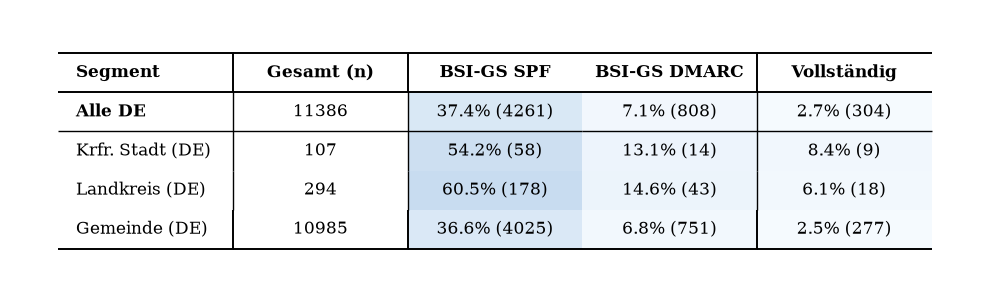

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_spf_dmarc_verteilung.png


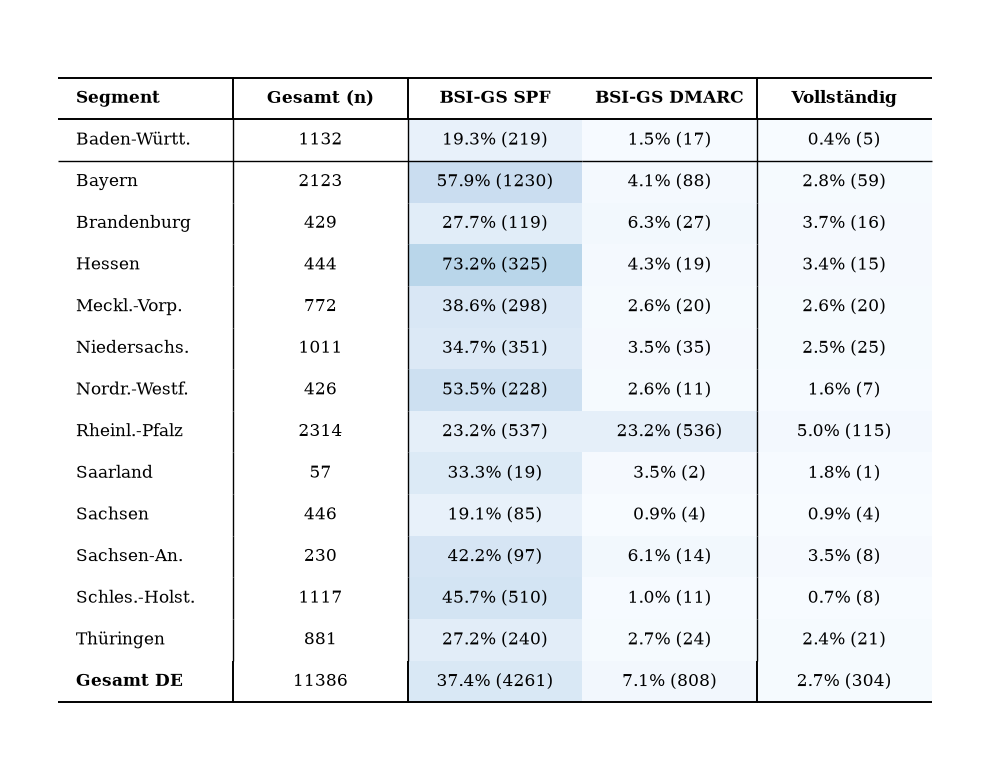

Tabelle erfolgreich gespeichert unter: abbildung_gs_spf_dmarc_verteilung.png


In [66]:
df_clean_gb = pd.read_csv("security/data/gb/antispoofing_data.csv", sep=';', decimal=',', low_memory=False)
df_clean_de = pd.read_csv("security/data/de/antispoofing_data.csv", sep=';', decimal=',', low_memory=False)
#valid_dmarc = get_valid_dmarc_base(df_clean_gb)
#has_rua = df_clean_gb["dmarcTagValueExplicit_rua"] == True
#has_ruf = df_clean_gb["dmarcTagValueExplicit_ruf"] == True
df_clean_de["dmarc_bsi_grundschutz"] = ((df_clean_de["spfGeneralData_valid"] == True) & 
    (df_clean_de["spfGeneralData_allQualifier"] == "fail")
)
df_clean_de["dmarc_bsi_grundschutz"] = ((get_dmarc_masks(df_clean_de)["4B"])) #  get_dmarc_masks(df_clean_gb)["3B"] 

metrics_bsi_gr_spf_dmarc = {
    "BSI-GS SPF": lambda d: ((d["spfGeneralData_valid"] == True) & 
    (d["spfGeneralData_allQualifier"] == "fail")),
    "BSI-GS DMARC": lambda d: ((get_dmarc_masks(d)["4B"] == True)),
    #"GOV.UK DMARC": lambda d: (get_dmarc_masks(d)["4B"] == True),
    "Vollständig": lambda d: ( ((get_dmarc_masks(d)["4B"] == True)) & 
                          ((d["spfGeneralData_valid"] == True) & (d["spfGeneralData_allQualifier"] == "fail")) )
}




tbl_scores_bsi_gs_auth = generate_tier_summary(
    df_de= df_clean_de, 
    metrics=metrics_bsi_gr_spf_dmarc, 
    mode="pct_count",
    #df_gb = df_clean_gb,
    breakdown_gb = False
)

# Render-Aufruf für Abbildung in der BA
bsi_gr_spf_dmarc = render_table_to_image(
    tbl_scores_bsi_gs_auth,
    filename="abbildung_bsi_gs_spf_dmarc_verteilung.png",
    divider_rows=[1],
    divider_cols=[0,1,3],
    dpi=800,
    font_size=12,
)



tbl_scores_bsi_gs_auth_region = generate_region_summary(
    df_de= df_clean_de, 
    metrics=metrics_bsi_gr_spf_dmarc, 
    mode="pct_count",
    #df_gb = df_clean_gb,
    breakdown_gb = False
)

# Render-Aufruf für Abbildung in der BA
bsi_gr_spf_dmarc = render_table_to_image(
    tbl_scores_bsi_gs_auth_region,
    filename="abbildung_gs_spf_dmarc_verteilung_region.png",
    divider_rows=[1],
    divider_cols=[0,1,3],
    dpi=800,
    font_size=12,
)



## GS Transport

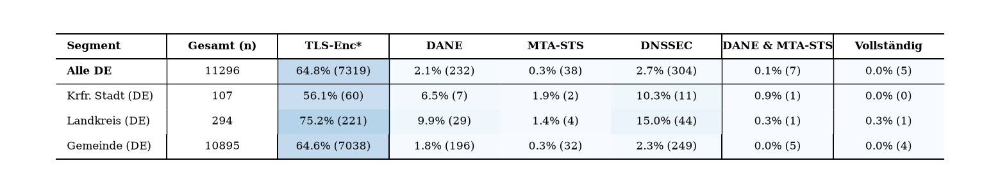

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_transport.png


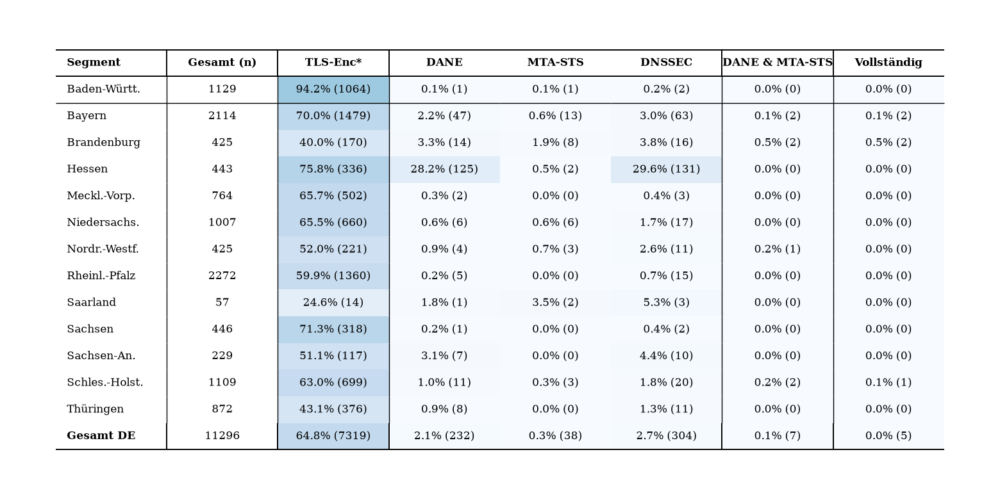

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_transport_region.png


In [13]:
#df_transport_gb = df_joined_gb
df_transport_de = pd.read_csv("security/data/de/transport_data.csv", sep=';', decimal=',', low_memory=False)

metrics_bsi_gr_transport = {
    "TLS-Enc*": lambda d: (
        (d["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2") & 
        (d["tlsVersionData_allValidTlsResult"] == True)
    ),
    
    "DANE": lambda d: ( 
        (d["daneResult_atLeastOneMtaSupportsDane"] == True) & 
        (d["daneResult_hasValidDaneAtLeastOneMta"] == True) & 
        (d["daneResult_hasValidDaneAllMta"] == True)
    ),
    
    "MTA-STS": lambda d: (
        (d["policy_mode"] == "enforce") & 
        (d["mtaStsData_generalErrorType"].isna())
    ),

    "DNSSEC": lambda d: (
        (d["dnssecResult_mxAtLeastOneDNSSEC"] == True) & 
        (d["dnssecResult_mxAllDNSSEC"] == True) & 
        (d["dnssecResult_domainDNSSEC"] == True)
    ),
    "DANE & MTA-STS": lambda d: ( 
            ( 
            # KORREKTUR: Hier stand vorher 'df' statt 'd'
            (d["daneResult_atLeastOneMtaSupportsDane"] == True) & 
            (d["daneResult_hasValidDaneAtLeastOneMta"] == True) & 
            (d["daneResult_hasValidDaneAllMta"] == True)
        ) & 
        (
            (d["policy_mode"] == "enforce") & 
            (d["mtaStsData_generalErrorType"].isna())
        )
    
    ),
    
    "Vollständig": lambda d: (
        (
            (d["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2") & 
            (d["tlsVersionData_allValidTlsResult"] == True)
        ) & 
        ( 
            # KORREKTUR: Hier stand vorher 'df' statt 'd'
            (d["daneResult_atLeastOneMtaSupportsDane"] == True) & 
            (d["daneResult_hasValidDaneAtLeastOneMta"] == True) & 
            (d["daneResult_hasValidDaneAllMta"] == True)
        ) & 
        (
            (d["policy_mode"] == "enforce") & 
            (d["mtaStsData_generalErrorType"].isna())
        ) & 
        (
            (d["dnssecResult_mxAtLeastOneDNSSEC"] == True) & 
            (d["dnssecResult_mxAllDNSSEC"] == True) & 
            (d["dnssecResult_domainDNSSEC"] == True)
        )
    ) 
}

tbl_scores_bsi_gs_transport = generate_tier_summary(
    #df_de=df_transport_de, 
    metrics=metrics_bsi_gr_transport, 
    mode="pct_count",
    df_de=df_transport_de,
    breakdown_gb=False
)

bsi_gs_transport_tier = render_table_to_image(
    tbl_scores_bsi_gs_transport,
    filename="abbildung_bsi_gs_transport.png", 
    divider_rows=[1],
    divider_cols=[0,1,2,5,6],
    dpi=800,
    font_size=12,
)






tbl_scores_bsi_gs_transport_region = generate_region_summary(
    #df_de=df_transport_de, 
    metrics=metrics_bsi_gr_transport, 
    mode="pct_count",
    df_de=df_transport_de,
    breakdown_gb=False
)



# Render-Aufruf für Abbildung in der BA
bsi_gs_transport_region = render_table_to_image(
    tbl_scores_bsi_gs_transport_region,
    filename="abbildung_bsi_gs_transport_region.png", 
    divider_rows=[1],
    divider_cols=[0,1,2,5,6],
    dpi=800,
    font_size=12,
)

## BSI TR

In [ ]:
df_clean_gb = pd.read_csv("security/data/gb/antispoofing_data.csv", sep=';', decimal=',', low_memory=False)
df_clean_de = pd.read_csv("security/data/de/antispoofing_data.csv", sep=';', decimal=',', low_memory=False)
#valid_dmarc = get_valid_dmarc_base(df_clean_gb)
#has_rua = df_clean_gb["dmarcTagValueExplicit_rua"] == True
#has_ruf = df_clean_gb["dmarcTagValueExplicit_ruf"] == True
df_clean_de["dmarc_bsi_grundschutz"] = ((df_clean_de["spfGeneralData_valid"] == True) & 
    (df_clean_de["spfGeneralData_allQualifier"] == "fail")
)
df_clean_de["dmarc_bsi_grundschutz"] = ((get_dmarc_masks(df_clean_de)["4B"])) #  get_dmarc_masks(df_clean_gb)["3B"] 

metrics_bsi_tr_spf_dmarc = {
    "BSI-TR SPF": lambda d: (d["spfGeneralData_valid"] == True) & ((d["spfGeneralData_allQualifier"] == "fail")
    | (d["spfGeneralData_allQualifier"] == "softfail")),
    

    # dmarcTagValues_aspf
    
    "BSI-TR DMARC": lambda d: ((get_dmarc_masks(d)["4B"] == True) 
                              & (d["dmarcTagValues_aspf"] == "s") &  (d["dmarcTagValues_adkim"] == "s" )
                               & (d["dmarcTagValueExplicit_rua"] == True) & (d["dmarcTagValueExplicit_ruf"].isna())
                              ),
    #"GOV.UK DMARC": lambda d: (get_dmarc_masks(d)["4B"] == True),
    "Beides": lambda d: (( (get_dmarc_masks(d)["4B"] == True) 
                               & (d["dmarcTagValues_aspf"] == "s") &  (d["dmarcTagValues_adkim"] == "s" )
                               & (d["dmarcTagValueExplicit_rua"] == True) & (d["dmarcTagValueExplicit_ruf"].isna()))
                            &
                            ((d["spfGeneralData_valid"] == True) & 
    ((d["spfGeneralData_allQualifier"] == "fail") | (d["spfGeneralData_allQualifier"] == "softfail")))
                           )
}
tbl_scores_bsi_tr = generate_tier_summary(
    df_de= df_clean_de, 
    metrics=metrics_bsi_tr_spf_dmarc, 
    mode="pct_count",
    df_gb = df_clean_gb,
    breakdown_gb = False
)

# Render-Aufruf für Abbildung in der BA
govuk_spf_dmarc = render_table_to_image(
    tbl_scores_bsi_tr,
    filename="abbildung_govuk_spf_dmarc_verteilung.png",
    divider_rows=[1],
    dpi=800,
    font_size=12,
)


## GOV.UK DMARC + SPF

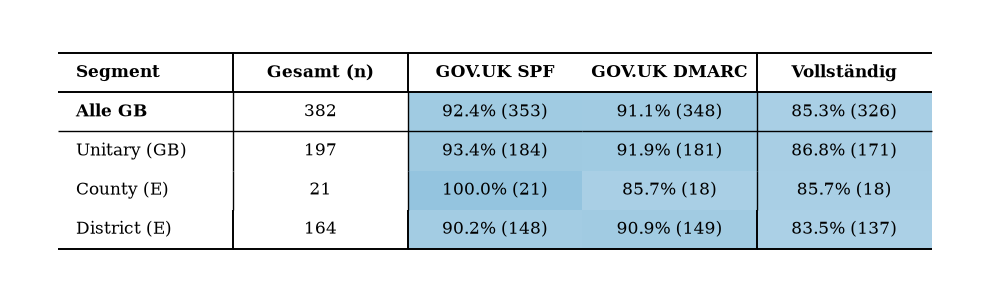

Tabelle erfolgreich gespeichert unter: abbildung_govuk_spf_dmarc_verteilung.png


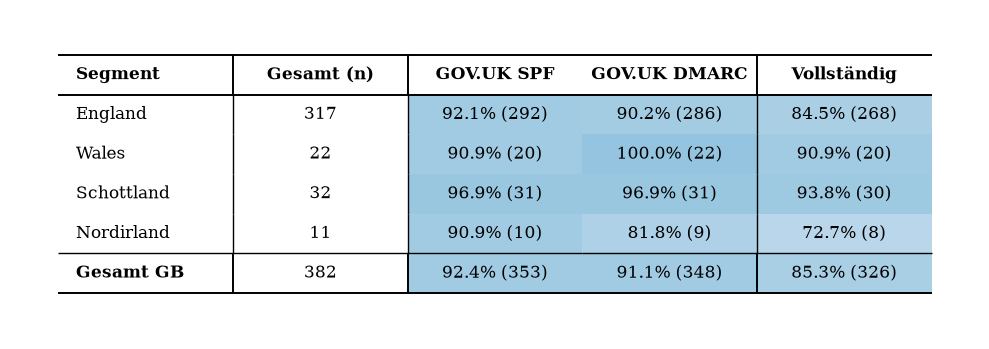

Tabelle erfolgreich gespeichert unter: abbildung_govuk_spf_dmarc_verteilung_region.png


In [175]:
metrics_govuk_spf_dmarc = {
    "GOV.UK SPF": lambda d: (d["spfGeneralData_valid"] == True) & 
    ((d["spfGeneralData_allQualifier"] == "fail")
    | (d["spfGeneralData_allQualifier"] == "softfail")),
    "GOV.UK DMARC": lambda d: ((get_dmarc_masks(d)["3B"] == True) | (get_dmarc_masks(d)["4B"] == True)) ,
    "Vollständig": lambda d: ( ((d["spfGeneralData_valid"] == True) & 
    ((d["spfGeneralData_allQualifier"] == "fail")
    | (d["spfGeneralData_allQualifier"] == "softfail"))) & ((get_dmarc_masks(d)["3B"] == True) | (get_dmarc_masks(d)["4B"] == True)) )
    #"Beides": lambda d: ((d["spf_govuk"] == True) & (d["dmarc_govuk"] == True))
}

tbl_scores_govuk = generate_tier_summary(
    df_gb=df_clean_gb, 
    metrics=metrics_govuk_spf_dmarc, 
    mode="pct_count",
    #df_de= df_clean_de,
    breakdown_de = False
)

# Render-Aufruf für Abbildung in der BA
govuk_spf_dmarc = render_table_to_image(
    tbl_scores_govuk,
    filename="abbildung_govuk_spf_dmarc_verteilung.png",
    divider_rows=[1,4],
    divider_cols=[0,1,3],
    dpi=800,
    font_size=12,
)


tbl_scores_govuk_region = generate_region_summary(
    df_gb=df_clean_gb, 
    metrics=metrics_govuk_spf_dmarc, 
    mode="pct_count",
    #df_de= df_clean_de,
    breakdown_de = False
)

# Render-Aufruf für Abbildung in der BA
govuk_spf_dmarc = render_table_to_image(
    tbl_scores_govuk_region,
    filename="abbildung_govuk_spf_dmarc_verteilung_region.png",
    divider_rows=[4],
    divider_cols=[0,1,3],
    dpi=800,
    font_size=12,
)



## GOV.UK Transport

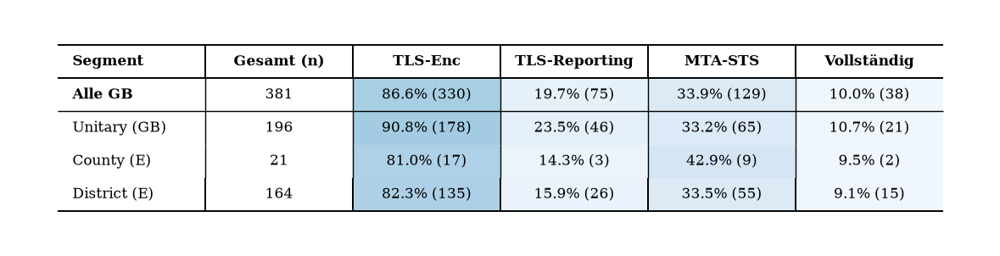

Tabelle erfolgreich gespeichert unter: abbildung_gov_uk_transport_verteilung.png


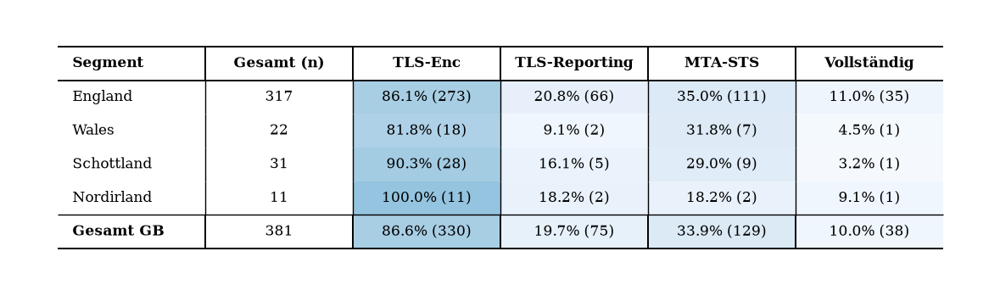

Tabelle erfolgreich gespeichert unter: abbildung_gov_uk_transport_verteilung_region.png


In [176]:
#### df_transport_gb = df_joined_gb
df_transport_de = pd.read_csv("security/data/de/transport_data.csv", sep=';', decimal=',', low_memory=False)


def gov_uk_tls_req(d):
    return ((d["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2") & (d["tlsVersionData_allValidTlsResult"] == True) & (d['recomm_comp'] == True))


def gov_uk_tlsrpt(d):
    return ((d["tlsRptData_hasTlsrptDnsRecord"] == True) & (d["tlsRptData_errorType"].isna()))

def gov_mta_sts(d):
    return ((d["policy_mode"] == "enforce") &  (d["mtaStsData_generalErrorType"].isna()))

metrics_gov_uk_transport = {
    "TLS-Enc": lambda d: (
       gov_uk_tls_req(d)
    )
    ,
    "TLS-Reporting": lambda d: (
       gov_uk_tlsrpt(d)
    )
    ,
    "MTA-STS": lambda d: (
        gov_mta_sts(d)
    )
    ,
    "Vollständig": lambda d: (
        (
            gov_uk_tls_req(d)
        ) 
        & 
        (
            gov_uk_tlsrpt(d)
        )
        &
        (
           gov_mta_sts(d)
        )
    ) 
}

tbl_scores_gov_uk_transport = generate_tier_summary( 
    metrics=metrics_gov_uk_transport, 
    mode="pct_count",
    df_gb=df_transport_gb,
    breakdown_de=False
)




# Render-Aufruf für Abbildung in der BA
gov_uk_transport = render_table_to_image(
    tbl_scores_gov_uk_transport,
    filename="abbildung_gov_uk_transport_verteilung.png", 
    divider_rows=[1],
    divider_cols=[0,1,2,3,4],
    dpi=800,
    font_size=12,
)




tbl_scores_gov_uk_transport_region = generate_region_summary( 
    metrics=metrics_gov_uk_transport, 
    mode="pct_count",
    df_gb=df_transport_gb,
    breakdown_de=False
)




# Render-Aufruf für Abbildung in der BA
gov_uk_transport_region = render_table_to_image(
    tbl_scores_gov_uk_transport_region,
    filename="abbildung_gov_uk_transport_verteilung_region.png", 
    divider_rows=[4],
    divider_cols=[0,1,2,3,4],
    dpi=800,
    font_size=12,
)




In [177]:
from pathlib import Path
from typing import Optional, Union
import pandas as pd

# ==============================================================================
# 1. SAUBERER INNER JOIN BEIDER TABELLEN (NUR GÜLTIGE SCANS IN BEIDEN TABELLEN)
# ==============================================================================
def fix_code_col(series: pd.Series) -> pd.Series:
    """Bereinigt 'code' (entfernt .0 und füllt führende Nullen bei DE-Schlüsseln auf)."""
    s = series.fillna("").astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    def _pad(c):
        if not c.isnumeric():
            return c
        if len(c) in (4, 7):
            return "0" + c
        return c
    return s.apply(_pad)


def build_complete_case_df(
    anti_source: Union[str, Path, pd.DataFrame],
    trans_source: Union[str, Path, pd.DataFrame],
    mx_source: Optional[Union[str, Path, pd.DataFrame]] = None
) -> pd.DataFrame:
    """
    Lädt Anti-Spoofing- und Transport-Daten (als Pfad oder DataFrame),
    filtert beide auf valide Scans und verbindet sie über 'code' (Inner Join).
    Optional wird mx_source für 'recomm_comp' (GOV.UK TLS-Enc) direkt mit-aggregiert.
    """
    df_as = (
        pd.read_csv(anti_source, sep=";", decimal=",", dtype={"code": str, "tier_id": str}, low_memory=False)
        if isinstance(anti_source, (str, Path)) else anti_source.copy()
    )
    df_tr = (
        pd.read_csv(trans_source, sep=";", decimal=",", dtype={"code": str, "tier_id": str}, low_memory=False)
        if isinstance(trans_source, (str, Path)) else trans_source.copy()
    )

    for d in [df_as, df_tr]:
        d["code"] = fix_code_col(d["code"])
        if "region" in d.columns:
            d["region"] = d["region"].replace({"Baden-Wüttemberg": "Baden-Württemberg"})

    # 1. Nur Kommunen behalten, die in BEIDEN Tabellen ein valides Ergebnis haben
    as_valid = df_as[df_as["aggDomainAntiSpoofingMetadata_isValid"] == True].drop_duplicates(subset=["code"]).copy()
    tr_valid = df_tr[df_tr["aggDataTransportMetadata_isValid"] == True].drop_duplicates(subset=["code"]).copy()

    # 2. Doppelte Spalten (name, region, tier_id, dnssecResult_domainDNSSEC) vor dem Merge entfernen
    overlap = [c for c in tr_valid.columns if c in as_valid.columns and c != "code"]
    tr_clean = tr_valid.drop(columns=overlap)

    # 3. Inner Join über 'code'
    df_merged = pd.merge(as_valid, tr_clean, on="code", how="inner")

    # 4. Optional: 'recomm_comp' aus mx_data.csv berechnen, falls noch nicht in trans_source enthalten
    if mx_source is not None and "recomm_comp" not in df_merged.columns:
        df_mx = (
            pd.read_csv(mx_source, sep=";", decimal=",", dtype={"code": str}, low_memory=False)
            if isinstance(mx_source, (str, Path)) else mx_source.copy()
        )
        df_mx["code"] = fix_code_col(df_mx["code"])
        df_mx["recomm_comp"] = (
            (df_mx["tls12Results_Compatibility_RSA_CBC_P-256_isValid"] == True) &
            (
                (df_mx["tls12Results_Recommended_RSA_GCM_P-256_isValid"] == True) |
                (df_mx["tls12Results_Recommended_ECDSA_GCM_P-256_isValid"] == True)
            )
        )
        mx_agg = df_mx.groupby("code", as_index=False).agg({"recomm_comp": "all"})
        df_merged = pd.merge(df_merged, mx_agg, on="code", how="left")
        df_merged["recomm_comp"] = df_merged["recomm_comp"].fillna(False)

    return df_merged


# ==============================================================================
# 2. EINZELRICHTLINIEN (AB ZELLE 154), SUMMEN-SCORE & KOMBINATIONEN BERECHNEN
# ==============================================================================
def add_policy_scores(df: pd.DataFrame) -> pd.DataFrame:
    """
    Prüft alle Einzelrichtlinien für BSI-Grundschutz (6 Kriterien) und GOV.UK (5 Kriterien)
    und erzeugt pro Kommune die Gesamtanzahl ('_score') sowie die Kombination ('_combo').
    """
    d = df.copy()
    dmarc_masks = get_dmarc_masks(d)  # Nutzt deine Funktion aus Zelle 23

    # --- A) BSI-GRUNDSCHUTZ (6 Kriterien aus Zelle 154 & 155) ---
    d["bsi_gs_spf"] = (d["spfGeneralData_valid"] == True) & (d["spfGeneralData_allQualifier"] == "fail")
    d["bsi_gs_dmarc"] = (dmarc_masks["4B"] == True)
    d["bsi_gs_tls"] = (
        (d["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2") &
        (d["tlsVersionData_allValidTlsResult"] == True)
    )
    d["bsi_gs_dane"] = (
        (d["daneResult_atLeastOneMtaSupportsDane"] == True) &
        (d["daneResult_hasValidDaneAtLeastOneMta"] == True) &
        (d["daneResult_hasValidDaneAllMta"] == True)
    )
    d["bsi_gs_mtasts"] = (d["policy_mode"] == "enforce") & (d["mtaStsData_generalErrorType"].isna())
    d["bsi_gs_dnssec"] = (
        (d["dnssecResult_mxAtLeastOneDNSSEC"] == True) &
        (d["dnssecResult_mxAllDNSSEC"] == True) &
        (d["dnssecResult_domainDNSSEC"] == True)
    )


    "Vollständig": lambda d: (
        (
            (d["tlsVersionData_hasTls1_2AtLeastOneMta"] == True) & 
            (d["tlsVersionData_allValidTlsResult"] == True)
        ) & 
        ( 
            # KORREKTUR: Hier stand vorher 'df' statt 'd'
            (d["daneResult_atLeastOneMtaSupportsDane"] == True) & 
            (d["daneResult_hasValidDaneAtLeastOneMta"] == True) & 
            (d["daneResult_hasValidDaneAllMta"] == True)
        ) & 
        (
            (d["policy_mode"] == "enforce") & 
            (d["mtaStsData_generalErrorType"].isna())
        ) & 
        (
            (d["dnssecResult_mxAtLeastOneDNSSEC"] == True) & 
            (d["dnssecResult_mxAllDNSSEC"] == True) & 
            (d["dnssecResult_domainDNSSEC"] == True)
        )




    
    bsi_gs_map = {
        "bsi_gs_spf": "SPF",
        "bsi_gs_dmarc": "DMARC",
        "bsi_gs_tls": "TLS-Enc*",
        "bsi_gs_dane": "DANE",
        "bsi_gs_mtasts": "MTA-STS",
        "bsi_gs_dnssec": "DNSSEC",
    }
    bsi_cols = list(bsi_gs_map.keys())
    d["bsi_gs_score"] = d[bsi_cols].astype(int).sum(axis=1)
    d["bsi_gs_score_label"] = d["bsi_gs_score"].apply(lambda k: "1 Kriterium" if k == 1 else f"{k} Kriterien")
    d["bsi_gs_combo"] = d[bsi_cols].apply(
        lambda r: " + ".join([bsi_gs_map[c] for c in bsi_cols if r[c]]) or "Keine", axis=1
    )

    # --- B) GOV.UK (5 Kriterien aus Zelle 153 & 151) ---
    d["govuk_spf"] = (d["spfGeneralData_valid"] == True) & (
        d["spfGeneralData_allQualifier"].isin(["fail", "softfail"])
    )
    d["govuk_dmarc"] = (dmarc_masks["3B"] == True) | (dmarc_masks["4B"] == True)

    # Nutzt 'recomm_comp' (falls mx_data gejoint wurde), sonst 'tls12Result_partlyValidTls12AllMta'
    tls_cipher_ok = (
        (d["recomm_comp"] == True) if "recomm_comp" in d.columns
        else (d["tls12Result_partlyValidTls12AllMta"] == True)
    )
    d["govuk_tls"] = (
        (d["tlsVersionData_minVersionAtLeastOneMta"] == "tls1_2") &
        (d["tlsVersionData_allValidTlsResult"] == True) &
        tls_cipher_ok
    )
    d["govuk_tlsrpt"] = (d["tlsRptData_hasTlsrptDnsRecord"] == True) & (d["tlsRptData_errorType"].isna())
    d["govuk_mtasts"] = (d["policy_mode"] == "enforce") & (d["mtaStsData_generalErrorType"].isna())

    govuk_map = {
        "govuk_spf": "SPF",
        "govuk_dmarc": "DMARC",
        "govuk_tls": "TLS-Enc",
        "govuk_tlsrpt": "TLS-Reporting",
        "govuk_mtasts": "MTA-STS",
    }
    gov_cols = list(govuk_map.keys())
    d["govuk_score"] = d[gov_cols].astype(int).sum(axis=1)
    d["govuk_score_label"] = d["govuk_score"].apply(lambda k: "1 Kriterium" if k == 1 else f"{k} Kriterien")
    d["govuk_combo"] = d[gov_cols].apply(
        lambda r: " + ".join([govuk_map[c] for c in gov_cols if r[c]]) or "Keine", axis=1
    )

    return d

## Auswertung

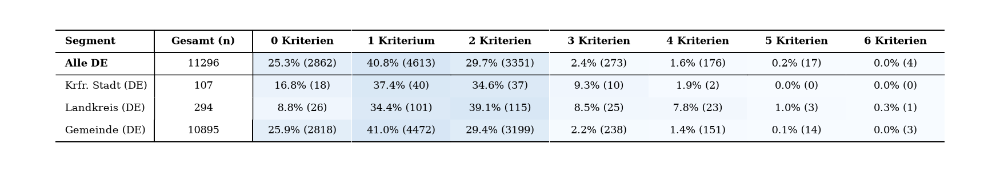

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_score_gesamt.png


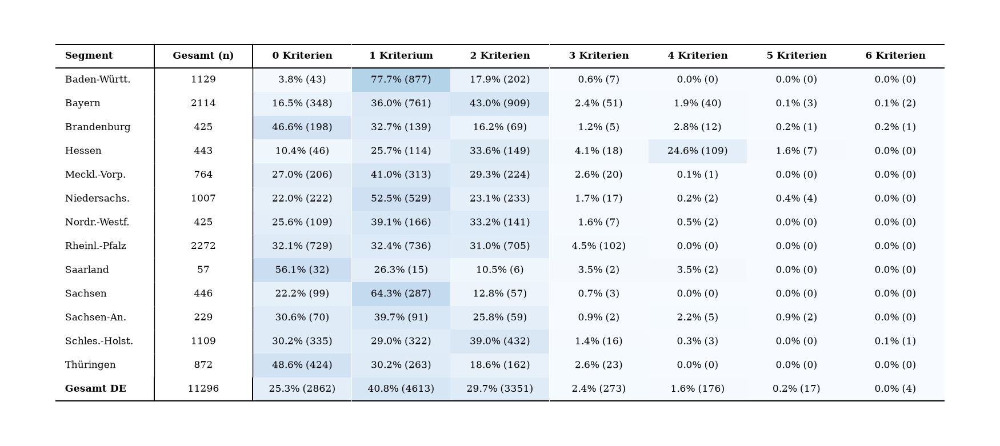

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_score_gesamt_region.png


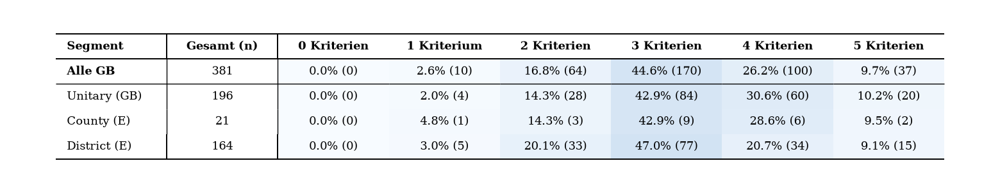

Tabelle erfolgreich gespeichert unter: abbildung_govuk_score_gesamt_tier_uk.png


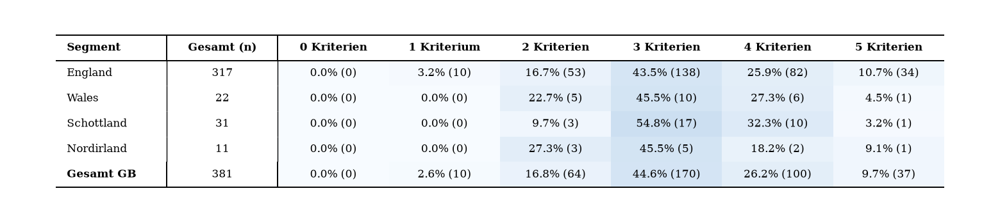

Tabelle erfolgreich gespeichert unter: abbildung_govuk_score_gesamt_region_uk.png


In [184]:
# 1. Beide Länder-Datensätze zusammenführen und Scores berechnen
df_merged_de = add_policy_scores(build_complete_case_df(
    anti_source="security/data/de/antispoofing_data.csv",
    trans_source="security/data/de/transport_data.csv",
    #mx_source="security/data/de/mx_data.csv"  # Optional für 'recomm_comp'
))

df_merged_gb = add_policy_scores(build_complete_case_df(
    anti_source="security/data/gb/antispoofing_data.csv",
    trans_source=df_joined_gb  
))


# 2. Metriken für die Anzahl erfüllter BSI-Grundschutz-Kriterien (0 bis 6)
metrics_bsi_gs_scores = {
    "0 Kriterien": lambda d: d["bsi_gs_score"] == 0,
    "1 Kriterium": lambda d: d["bsi_gs_score"] == 1,
    "2 Kriterien": lambda d: d["bsi_gs_score"] == 2,
    "3 Kriterien": lambda d: d["bsi_gs_score"] == 3,
    "4 Kriterien": lambda d: d["bsi_gs_score"] == 4,
    "5 Kriterien": lambda d: d["bsi_gs_score"] == 5,
    "6 Kriterien": lambda d: d["bsi_gs_score"] == 6,
}

# 3. Bestehende Tier-Summary-Tabelle erzeugen & als Booktabs-Heatmap rendern
tbl_bsi_gs_scores = generate_tier_summary(
    df_de=df_merged_de,
   # df_gb=df_merged_gb,
    metrics=metrics_bsi_gs_scores,
    mode="pct_count",
  #  breakdown_gb=False,
    filter_valid=False  # Bereits durch build_complete_case_df auf valide Complete Cases gefiltert
)

render_table_to_image(
    tbl_bsi_gs_scores,
    filename="abbildung_bsi_gs_score_gesamt.png",
    divider_rows=[1],
    dpi=800,
    font_size=13
)

# 3. Bestehende Tier-Summary-Tabelle erzeugen & als Booktabs-Heatmap rendern
tbl_bsi_gs_scores_region = generate_region_summary(
    df_de=df_merged_de,
   # df_gb=df_merged_gb,
    metrics=metrics_bsi_gs_scores,
    mode="pct_count",
  #  breakdown_gb=False,
    filter_valid=False  # Bereits durch build_complete_case_df auf valide Complete Cases gefiltert
)

render_table_to_image(
    tbl_bsi_gs_scores_region,
    filename="abbildung_bsi_gs_score_gesamt_region.png",
    dpi=800,
    font_size=12
)



# Analog für GOV.UK (0 bis 5 Kriterien):
metrics_govuk_scores = {
    "0 Kriterien": lambda d: d["govuk_score"] == 0,
    "1 Kriterium": lambda d: d["govuk_score"] == 1,
    "2 Kriterien": lambda d: d["govuk_score"] == 2,
    "3 Kriterien": lambda d: d["govuk_score"] == 3,
    "4 Kriterien": lambda d: d["govuk_score"] == 4,
    "5 Kriterien": lambda d: d["govuk_score"] == 5,
}

tbl_govuk_scores = generate_tier_summary(
    df_gb=df_merged_gb,
    #df_de=df_merged_de,
    metrics=metrics_govuk_scores,
    mode="pct_count",
    #breakdown_de=False,
    filter_valid=False
)

tbl_govuk_scores_region = generate_region_summary(
    df_gb=df_merged_gb,
    #df_de=df_merged_de,
    metrics=metrics_govuk_scores,
    mode="pct_count",
    #breakdown_de=False,
    filter_valid=False
)


render_table_to_image(
    tbl_govuk_scores,
    filename="abbildung_govuk_score_gesamt_tier_uk.png",
    divider_rows=[1],
    dpi=800,
    font_size=13
)


render_table_to_image(
    tbl_govuk_scores_region,
    filename="abbildung_govuk_score_gesamt_region_uk.png",
    dpi=800,
    font_size=12
)


## Präsi

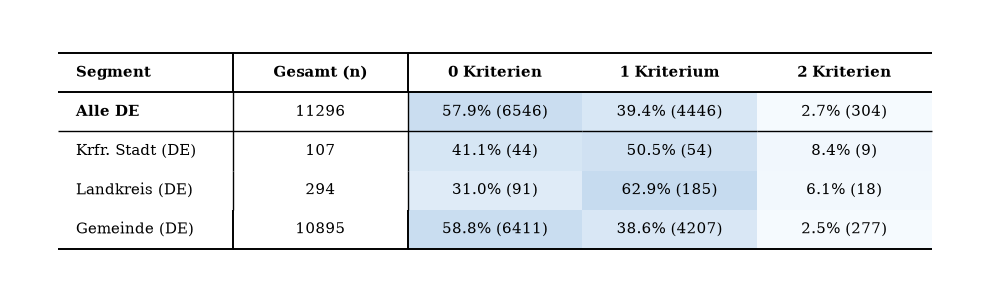

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_auth_score.png


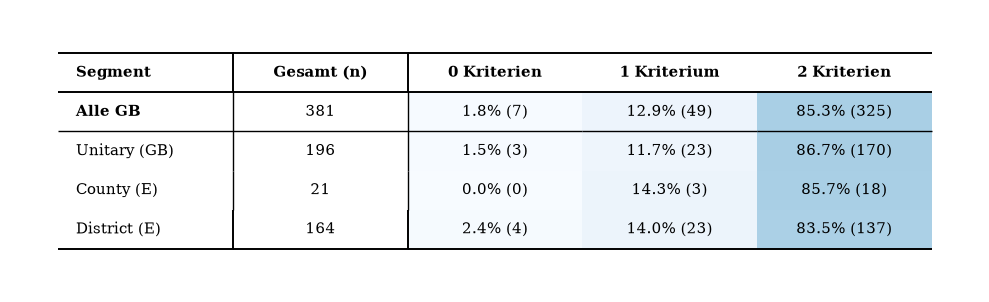

Tabelle erfolgreich gespeichert unter: abbildung_govuk_auth_score.png


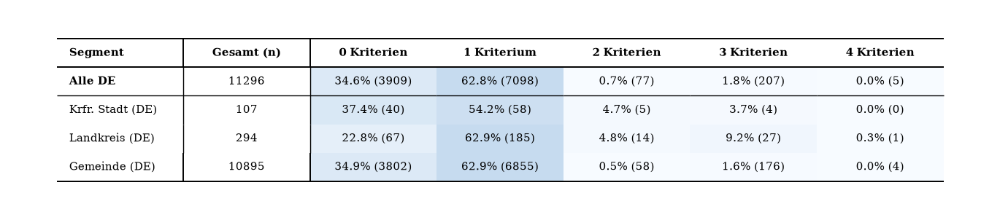

Tabelle erfolgreich gespeichert unter: abbildung_bsi_gs_trans_score.png


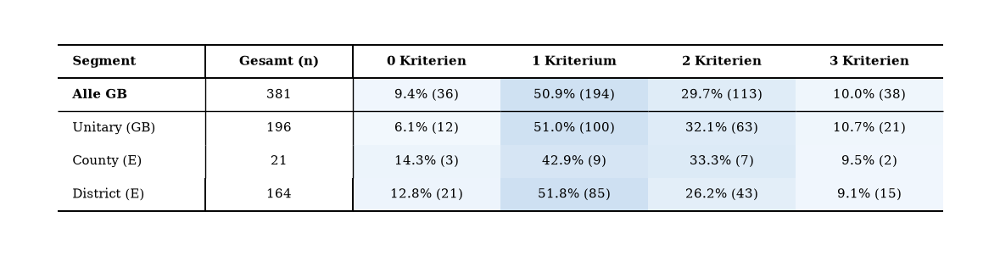

Tabelle erfolgreich gespeichert unter: abbildung_govuk_trans_score.png


In [163]:
# ==============================================================================
# AGGREGIERTE SUB-SCORES: SENDER-AUTHENTIFIZIERUNG & TRANSPORTSICHERHEIT
# (Voraussetzung: Zelle 192 & 194 mit df_merged_de und df_merged_gb wurden ausgeführt)
# ==============================================================================

# 1. Teil-Scores pro Kommune berechnen
# A) Deutschland (BSI-Grundschutz: 2 Auth-Kriterien, 4 Transport-Kriterien)
auth_cols_de  = ["bsi_gs_spf", "bsi_gs_dmarc"]
trans_cols_de = ["bsi_gs_tls", "bsi_gs_dane", "bsi_gs_mtasts", "bsi_gs_dnssec"]

df_merged_de["bsi_auth_score"]  = df_merged_de[auth_cols_de].astype(int).sum(axis=1)
df_merged_de["bsi_trans_score"] = df_merged_de[trans_cols_de].astype(int).sum(axis=1)

# B) Großbritannien (GOV.UK: 2 Auth-Kriterien, 3 Transport-Kriterien)
auth_cols_gb  = ["govuk_spf", "govuk_dmarc"]
trans_cols_gb = ["govuk_tls", "govuk_tlsrpt", "govuk_mtasts"]

df_merged_gb["govuk_auth_score"]  = df_merged_gb[auth_cols_gb].astype(int).sum(axis=1)
df_merged_gb["govuk_trans_score"] = df_merged_gb[trans_cols_gb].astype(int).sum(axis=1)


# 2. Tabellen für Sender-Authentifizierung (0 bis 2 Kriterien)
metrics_auth_de = {
    "0 Kriterien": lambda d: d["bsi_auth_score"] == 0,
    "1 Kriterium": lambda d: d["bsi_auth_score"] == 1,
    "2 Kriterien": lambda d: d["bsi_auth_score"] == 2,
}
metrics_auth_gb = {
    "0 Kriterien": lambda d: d["govuk_auth_score"] == 0,
    "1 Kriterium": lambda d: d["govuk_auth_score"] == 1,
    "2 Kriterien": lambda d: d["govuk_auth_score"] == 2,
}

tbl_auth_de = generate_tier_summary(df_de=df_merged_de, metrics=metrics_auth_de, mode="pct_count", filter_valid=False)
tbl_auth_gb = generate_tier_summary(df_gb=df_merged_gb, metrics=metrics_auth_gb, mode="pct_count", filter_valid=False)

render_table_to_image(tbl_auth_de, filename="abbildung_bsi_gs_auth_score.png", divider_rows=[1], dpi=800, font_size=11)
render_table_to_image(tbl_auth_gb, filename="abbildung_govuk_auth_score.png", divider_rows=[1], dpi=800, font_size=11)


# 3. Tabellen für Transportsicherheit (DE: 0 bis 4 Kriterien | GB: 0 bis 3 Kriterien)
metrics_trans_de = {
    "0 Kriterien": lambda d: d["bsi_trans_score"] == 0,
    "1 Kriterium": lambda d: d["bsi_trans_score"] == 1,
    "2 Kriterien": lambda d: d["bsi_trans_score"] == 2,
    "3 Kriterien": lambda d: d["bsi_trans_score"] == 3,
    "4 Kriterien": lambda d: d["bsi_trans_score"] == 4,
}
metrics_trans_gb = {
    "0 Kriterien": lambda d: d["govuk_trans_score"] == 0,
    "1 Kriterium": lambda d: d["govuk_trans_score"] == 1,
    "2 Kriterien": lambda d: d["govuk_trans_score"] == 2,
    "3 Kriterien": lambda d: d["govuk_trans_score"] == 3,
}

tbl_trans_de = generate_tier_summary(df_de=df_merged_de, metrics=metrics_trans_de, mode="pct_count", filter_valid=False)
tbl_trans_gb = generate_tier_summary(df_gb=df_merged_gb, metrics=metrics_trans_gb, mode="pct_count", filter_valid=False)

render_table_to_image(tbl_trans_de, filename="abbildung_bsi_gs_trans_score.png", divider_rows=[1], dpi=800, font_size=11)
render_table_to_image(tbl_trans_gb, filename="abbildung_govuk_trans_score.png", divider_rows=[1], dpi=800, font_size=11)

Gültige Kommunen GB: N = 382 | DE: N = 11386


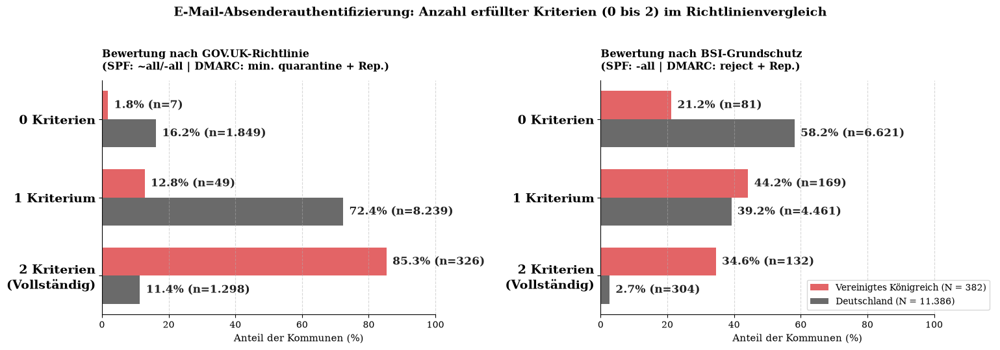

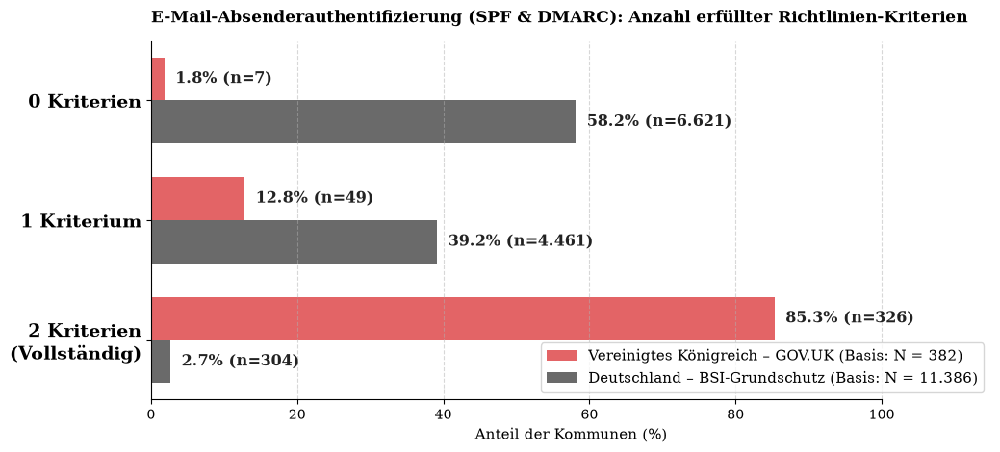

In [173]:
from pathlib import Path
from typing import Union
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. FILTER-FUNKTION FÜR GÜLTIGE SENDER-AUTHENTIFIZIERUNGS-ERGEBNISSE
# ==============================================================================
def prepare_valid_antispoofing_df(
    anti_source: Union[str, Path, pd.DataFrame]
) -> pd.DataFrame:
    """
    Lädt antispoofing_data.csv, filtert alle ungültigen Messergebnisse heraus
    (aggDomainAntiSpoofingMetadata_isValid == True) und berechnet die Erfüllung
    sowie die Anzahl erfüllter Kriterien (0, 1, 2) nach GOV.UK und BSI-Grundschutz.
    """
    df = (
        pd.read_csv(anti_source, sep=";", decimal=",", dtype={"code": str, "tier_id": str}, low_memory=False)
        if isinstance(anti_source, (str, Path)) else anti_source.copy()
    )

    # Tippfehler in Bundesländern bereinigen
    if "region" in df.columns:
        df["region"] = df["region"].replace({"Baden-Wüttemberg": "Baden-Württemberg"})

    # Gemeindeschlüssel bereinigen
    df["code"] = df["code"].fillna("").astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    df["code"] = df["code"].apply(lambda c: "0" + c if c.isnumeric() and len(c) in (4, 7) else c)

    # WICHTIG: Ungültige Ergebnisse für die Senderauthentifizierung herausfiltern
    df_valid = df[df["aggDomainAntiSpoofingMetadata_isValid"] == True].drop_duplicates(subset=["code"]).copy()

    # DMARC-Masken abrufen (nutzt get_dmarc_masks aus Zelle 11)
    dmarc_masks = get_dmarc_masks(df_valid)

    # 1. Generell vorhanden (SPF & DMARC)
    df_valid["spf_present"] = ~df_valid["spfGeneralData_errorType"].fillna("").astype(str).str.startswith("An SPF record does not exist")
    df_valid["dmarc_present"] = dmarc_masks["Nutzen DMARC"] == True

    # 2. GOV.UK Kriterien (SPF: ~all oder -all | DMARC: 3B oder 4B)
    df_valid["govuk_spf"] = (df_valid["spfGeneralData_valid"] == True) & (
        df_valid["spfGeneralData_allQualifier"].isin(["fail", "softfail"])
    )
    df_valid["govuk_dmarc"] = (dmarc_masks["3B"] == True) | (dmarc_masks["4B"] == True)
    df_valid["govuk_auth_score"] = df_valid[["govuk_spf", "govuk_dmarc"]].astype(int).sum(axis=1)

    # 3. BSI-Grundschutz Kriterien (SPF: -all | DMARC: 4B)
    df_valid["bsi_gs_spf"] = (df_valid["spfGeneralData_valid"] == True) & (
        df_valid["spfGeneralData_allQualifier"] == "fail"
    )
    df_valid["bsi_gs_dmarc"] = dmarc_masks["4B"] == True
    df_valid["bsi_gs_auth_score"] = df_valid[["bsi_gs_spf", "bsi_gs_dmarc"]].astype(int).sum(axis=1)

    return df_valid


# ==============================================================================
# 2. DATEN LADEN & BEREINIGEN
# ==============================================================================
df_auth_gb = prepare_valid_antispoofing_df("security/data/gb/antispoofing_data.csv")
df_auth_de = prepare_valid_antispoofing_df("security/data/de/antispoofing_data.csv")

print(f"Gültige Kommunen GB: N = {len(df_auth_gb)} | DE: N = {len(df_auth_de)}")


# ==============================================================================
# 3. BALKENDIAGRAMM A: ANZAHL ERFÜLLTER KRITERIEN (0, 1, 2 KRITERIEN)
#    Links: Bewertung nach GOV.UK | Rechts: Bewertung nach BSI-Grundschutz
# ==============================================================================
COLOR_GB = "#E15759"  # TH-Nürnberg Hellrot (Vereinigtes Königreich)
COLOR_DE = "#555555"  # Kontrastfarbe Dunkelgrau (Deutschland)

base_gb = len(df_auth_gb)
base_de = len(df_auth_de)

cats_score = ["0 Kriterien", "1 Kriterium", "2 Kriterien\n(Vollständig)"]
y = np.arange(len(cats_score))
h = 0.36

# Werte dynamisch aus den gefilterten DataFrames berechnen
gb_govuk_n   = [int((df_auth_gb["govuk_auth_score"] == k).sum()) for k in [0, 1, 2]]
gb_govuk_pct = [(n / base_gb) * 100 for n in gb_govuk_n]

de_govuk_n   = [int((df_auth_de["govuk_auth_score"] == k).sum()) for k in [0, 1, 2]]
de_govuk_pct = [(n / base_de) * 100 for n in de_govuk_n]

gb_bsi_n     = [int((df_auth_gb["bsi_gs_auth_score"] == k).sum()) for k in [0, 1, 2]]
gb_bsi_pct   = [(n / base_gb) * 100 for n in gb_bsi_n]

de_bsi_n     = [int((df_auth_de["bsi_gs_auth_score"] == k).sum()) for k in [0, 1, 2]]
de_bsi_pct   = [(n / base_de) * 100 for n in de_bsi_n]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.2))

for ax, gb_p, gb_n, de_p, de_n, sub_title in [
    (ax1, gb_govuk_pct, gb_govuk_n, de_govuk_pct, de_govuk_n,
     "Bewertung nach GOV.UK-Richtlinie\n(SPF: ~all/-all | DMARC: min. quarantine + Rep.)"),
    (ax2, gb_bsi_pct, gb_bsi_n, de_bsi_pct, de_bsi_n,
     "Bewertung nach BSI-Grundschutz\n(SPF: -all | DMARC: reject + Rep.)")
]:
    ax.barh(y - h/2, gb_p, height=h, color=COLOR_GB, alpha=0.92,
            label=f"Vereinigtes Königreich (N = {base_gb})")
    ax.barh(y + h/2, de_p, height=h, color=COLOR_DE, alpha=0.88,
            label=f"Deutschland (N = {base_de:,})".replace(",", "."))
    ax.set_yticks(y)
    ax.set_yticklabels(cats_score, fontsize=14, fontweight="bold")
    ax.invert_yaxis()
    ax.set_xlabel("Anteil der Kommunen (%)", fontsize=10.5)
    ax.set_xlim(0, 118)
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.spines["bottom"].set_bounds(0, 100)
    ax.set_title(sub_title, fontsize=11.5, fontweight="bold", loc="left", pad=12)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)

    for idx in range(len(cats_score)):
        txt_gb = f"{gb_p[idx]:.1f}% (n={gb_n[idx]:,})".replace(",", ".")
        txt_de = f"{de_p[idx]:.1f}% (n={de_n[idx]:,})".replace(",", ".")
        ax.text(gb_p[idx] + 1.8, idx - h/2, txt_gb, va="center", ha="left",
                fontsize=12.2, color="#222222", fontweight="bold")
        ax.text(de_p[idx] + 1.8, idx + h/2, txt_de, va="center", ha="left",
                fontsize=12.2, color="#222222", fontweight="bold")

ax2.legend(loc="lower right", frameon=True, fontsize=10)
fig.suptitle("E-Mail-Absenderauthentifizierung: Anzahl erfüllter Kriterien (0 bis 2) im Richtlinienvergleich",
             fontsize=13.5, fontweight="bold", y=1.03)

plt.tight_layout()
plt.savefig("abbildung_auth_kriterien_beide_richtlinien.png", dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# 4. BALKENDIAGRAMM B: STAATENSPEZIFISCHER VERGLEICH (1 KOMPAKTES DIAGRAMM)
#    UK nach GOV.UK vs. DE nach BSI-Grundschutz (0, 1, 2 Kriterien)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10.5, 4.8))

ax.barh(y - h/2, gb_govuk_pct, height=h, color=COLOR_GB, alpha=0.92,
        label=f"Vereinigtes Königreich – GOV.UK (Basis: N = {base_gb})")
ax.barh(y + h/2, de_bsi_pct, height=h, color=COLOR_DE, alpha=0.88,
        label=f"Deutschland – BSI-Grundschutz (Basis: N = {base_de:,})".replace(",", "."))

ax.set_yticks(y)
ax.set_yticklabels(cats_score, fontsize=14, fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Anteil der Kommunen (%)", fontsize=10.5)
ax.set_xlim(0, 115)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.spines["bottom"].set_bounds(0, 100)
ax.set_title("E-Mail-Absenderauthentifizierung (SPF & DMARC): Anzahl erfüllter Richtlinien-Kriterien",
             fontsize=12.5, fontweight="bold", loc="left", pad=14)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=True, fontsize=11)

for idx in range(len(cats_score)):
    txt_gb = f"{gb_govuk_pct[idx]:.1f}% (n={gb_govuk_n[idx]:,})".replace(",", ".")
    txt_de = f"{de_bsi_pct[idx]:.1f}% (n={de_bsi_n[idx]:,})".replace(",", ".")
    ax.text(gb_govuk_pct[idx] + 1.5, idx - h/2, txt_gb, va="center", ha="left",
            fontsize=11.5, color="#222222", fontweight="bold")
    ax.text(de_bsi_pct[idx] + 1.5, idx + h/2, txt_de, va="center", ha="left",
            fontsize=11.5, color="#222222", fontweight="bold")

plt.tight_layout()
plt.savefig("abbildung_auth_kriterien_staatenspezifisch.png", dpi=300, bbox_inches="tight")
plt.show()

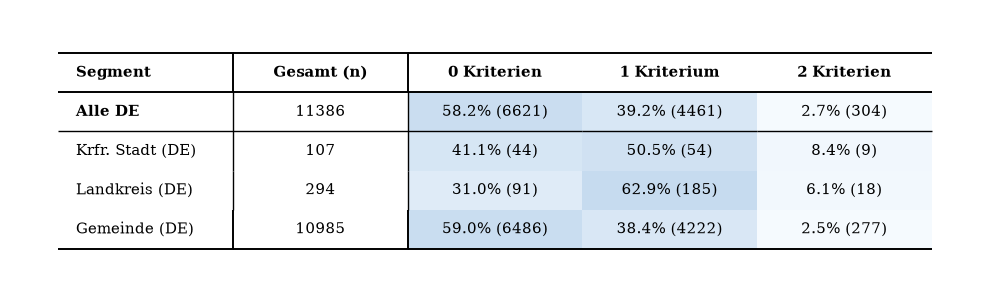

Tabelle erfolgreich gespeichert unter: tabelle_auth_score_de.png


In [167]:
metrics_auth_score_de = {
    "0 Kriterien": lambda d: d["bsi_gs_auth_score"] == 0,
    "1 Kriterium": lambda d: d["bsi_gs_auth_score"] == 1,
    "2 Kriterien": lambda d: d["bsi_gs_auth_score"] == 2,
}
tbl_auth_tiers_de = generate_tier_summary(df_de=df_auth_de, metrics=metrics_auth_score_de, filter_valid=False)
render_table_to_image(tbl_auth_tiers_de, filename="tabelle_auth_score_de.png", divider_rows=[1], dpi=800, font_size=11)

In [ ]:
# 1. Tabelle der Top 3 Kombinationen + Sonstige berechnen (z. B. für 3 bis 6 Kriterien)
plot_df_bsi_1_6 = get_top_k_plus_sonstige(
    df=df_merged_de,
    count_col="bsi_gs_score",
    combo_col="bsi_gs_combo",
    target_counts=[1,2,3, 4, 5, 6],  # Oder [1, 2, 3, 4, 5, 6] für die Gesamttabelle
    top_k=3
)
print(plot_df_bsi_1_6)

# 2. Als Balkendiagramm im TH-Nürnberg-Stil plotten
plot_top_k_plus_sonstige(
    plot_df=plot_df_bsi_1_6,
    total_basis=len(df_merged_de),
    title="Top 3 Kombinationen + Sonstige je Anzahl erfüllter BSI-Grundschutz-Kriterien (für 3 bis 6 Kriterien, DE)",
    unit_short="K",
    bar_color="#E15759",
    save_path="bsi_gs_kombinationen_3_bis_6.png"
)

## GOV UK

In [ ]:
# 1. Tabelle der Top 3 Kombinationen + Sonstige berechnen (z. B. für 3 bis 6 Kriterien)
plot_df_gov_uk_1_6 = get_top_k_plus_sonstige(
    df=df_merged_gb,
    count_col="govuk_score",
    combo_col="govuk_combo",
    target_counts=[1,2,3, 4, 5, 6],  # Oder [1, 2, 3, 4, 5, 6] für die Gesamttabelle
    top_k=3
)


# 2. Als Balkendiagramm im TH-Nürnberg-Stil plotten
plot_top_k_plus_sonstige(
    plot_df=plot_df_gov_uk_1_6,
    total_basis=len(df_merged_gb),
    title="Top 3 Kombinationen + Sonstige je Anzahl erfüllter GOV-UK Kriterien (für 1 bis 6 Kriterien, DE)",
    unit_short="K",
    bar_color="#E15759",
    save_path="bsi_gov_uk_kombinationen_1_bis_6.png"
)

In [ ]:
import pandas as pd

# 1. Daten mit extremen Unterschieden erstellen
import pandas as pd

# 1. Daten erstellen
daten = {
    'n': [11129,294],
    'Microsoft': [793,5],
    'Google': [8,0],
    'AWS': [0,0],
    'Domestic': [9647,281],
    'Foreign':[147,1],
    'Unknown':[534,7],
    'Domestic %': ['86.7%','95,6%'],
    'US %': ['7.2%','1.7%']
}

pd.Index([1, 2, 3])
df_l = pd.DataFrame(daten)
df_l.index = ['Gem & Krf. Stdt', 'Landkr.']

df_l


render_table_to_image(
    df_l,
    filename="provider_lk.png",
    #divider_rows=[3,4, 5],  # Trennstriche nach Alle GB, District (E) und Alle DE
    dpi=800,
   # divider_cols=[1],
   # row_labels= [1,2,3,"","Fehler gesamt"],
    caption_pos = 0.05,
    exclude_color_cols = ["n","Microsoft","AWS", "Google","Domestic","Foreign","Unknown","Domestic %","US %"],

    

)


## BA Präsi

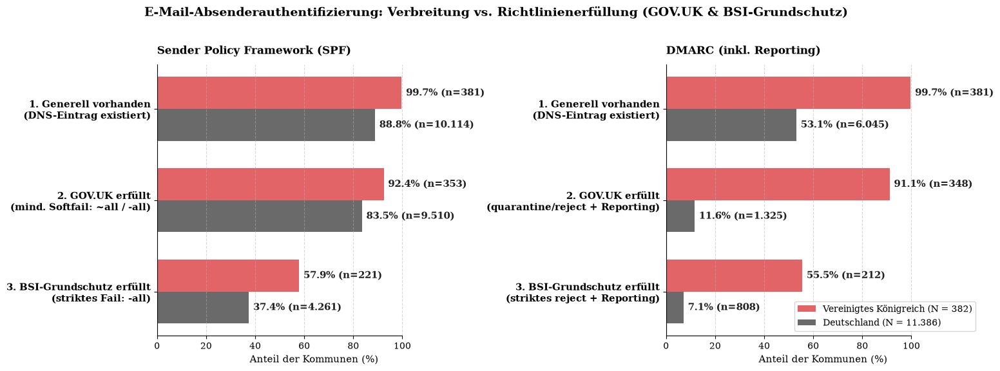

In [73]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. FARBEN & DATENBASIS (TH-Nürnberg Stil)
# ==============================================================================
COLOR_GB = "#E15759"  # TH-Nürnberg Hellrot (Vereinigtes Königreich)
COLOR_DE = "#555555"  # Kontrastfarbe Dunkelgrau (Deutschland)

base_gb = 382
base_de = 11386

# Kategorien und Messwerte für SPF
categories_spf = [
    "1. Generell vorhanden\n(DNS-Eintrag existiert)",
    "2. GOV.UK erfüllt\n(mind. Softfail: ~all / -all)",
    "3. BSI-Grundschutz erfüllt\n(striktes Fail: -all)"
]
spf_gb_pct = [99.7, 92.4, 57.9]
spf_gb_n   = [381, 353, 221]
spf_de_pct = [88.8, 83.5, 37.4]
spf_de_n   = [10114, 9510, 4261]

# Kategorien und Messwerte für DMARC
categories_dmarc = [
    "1. Generell vorhanden\n(DNS-Eintrag existiert)",
    "2. GOV.UK erfüllt\n(quarantine/reject + Reporting)",
    "3. BSI-Grundschutz erfüllt\n(striktes reject + Reporting)"
]
dmarc_gb_pct = [99.7, 91.1, 55.5]
dmarc_gb_n   = [381, 348, 212]
dmarc_de_pct = [53.1, 11.6, 7.1]
dmarc_de_n   = [6045, 1325, 808]

# ==============================================================================
# 2. PLOT ERSTELLEN
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.6))

y = np.arange(3)
h = 0.35

for ax, cats, gb_p, gb_n, de_p, de_n, subtitle in [
    (ax1, categories_spf, spf_gb_pct, spf_gb_n, spf_de_pct, spf_de_n, "Sender Policy Framework (SPF)"),
    (ax2, categories_dmarc, dmarc_gb_pct, dmarc_gb_n, dmarc_de_pct, dmarc_de_n, "DMARC (inkl. Reporting)")
]:
    ax.barh(y - h/2, gb_p, height=h, color=COLOR_GB, alpha=0.92,
            label=f"Vereinigtes Königreich (N = {base_gb})")
    ax.barh(y + h/2, de_p, height=h, color=COLOR_DE, alpha=0.88,
            label=f"Deutschland (N = {base_de:,})".replace(',', '.'))
    
    ax.set_yticks(y)
    ax.set_yticklabels(cats, fontsize=10.5, fontweight='bold')
    ax.invert_yaxis()
    ax.set_xlabel("Anteil der Kommunen (%)", fontsize=10.5)
    ax.set_xlim(0, 128)
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.spines['bottom'].set_bounds(0, 100)
    ax.set_title(subtitle, fontsize=12.5, fontweight='bold', loc='left', pad=12)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.spines[['top', 'right']].set_visible(False)

    # Wertebeschriftung rechts neben den Balken
    for idx in range(3):
        txt_gb = f"{gb_p[idx]:.1f}% (n={gb_n[idx]:,})".replace(',', '.')
        txt_de = f"{de_p[idx]:.1f}% (n={de_n[idx]:,})".replace(',', '.')
        ax.text(gb_p[idx] + 1.8, idx - h/2, txt_gb, va='center', ha='left',
                fontsize=11, color='#222222', fontweight='bold')
        ax.text(de_p[idx] + 1.8, idx + h/2, txt_de, va='center', ha='left',
                fontsize=11, color='#222222', fontweight='bold')

ax2.legend(loc='lower right', frameon=True, fontsize=10)
fig.suptitle("E-Mail-Absenderauthentifizierung: Verbreitung vs. Richtlinienerfüllung (GOV.UK & BSI-Grundschutz)",
             fontsize=13.5, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig("spf_dmarc_richtlinien_vergleich.png", dpi=300, bbox_inches='tight')
plt.show()

## GOV.UK-Richtlinien

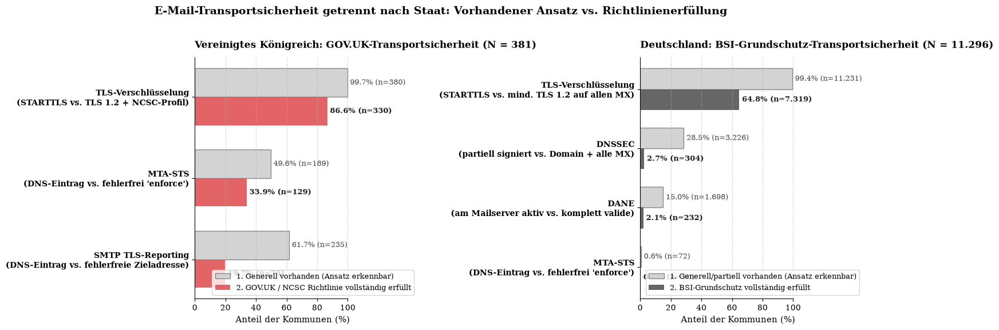

In [86]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. FARBEN & DATENBASIS
# ==============================================================================
COLOR_GB_VALID = "#E15759"     # TH-Nürnberg Hellrot für "Richtlinie erfüllt (GB)"
COLOR_DE_VALID = "#555555"     # Dunkelgrau für "Richtlinie erfüllt (DE)"
COLOR_PRESENT  = "#D3D3D3"     # Hellgrau für "Generell/partiell vorhanden"

fig, (ax_gb, ax_de) = plt.subplots(1, 2, figsize=(15.5, 5.6))
h = 0.35

# --- Links: Vereinigtes Königreich (GOV.UK & NCSC Richtlinie, N = 381) ---
cats_gb = [
    "TLS-Verschlüsselung\n(STARTTLS vs. TLS 1.2 + NCSC-Profil)",
    "MTA-STS\n(DNS-Eintrag vs. fehlerfrei 'enforce')",
    "SMTP TLS-Reporting\n(DNS-Eintrag vs. fehlerfreie Zieladresse)"
]
gb_pres_pct = [99.7, 49.6, 61.7]
gb_pres_n   = [380, 189, 235]
gb_val_pct  = [86.6, 33.9, 19.7]
gb_val_n    = [330, 129, 75]

y_gb = np.arange(len(cats_gb))

ax_gb.barh(y_gb - h/2, gb_pres_pct, height=h, color=COLOR_PRESENT, edgecolor="#888888",
           label="1. Generell vorhanden (Ansatz erkennbar)")
ax_gb.barh(y_gb + h/2, gb_val_pct, height=h, color=COLOR_GB_VALID, alpha=0.92,
           label="2. GOV.UK / NCSC Richtlinie vollständig erfüllt")

ax_gb.set_yticks(y_gb)
ax_gb.set_yticklabels(cats_gb, fontsize=10, fontweight='bold')
ax_gb.invert_yaxis()
ax_gb.set_xlabel("Anteil der Kommunen (%)", fontsize=10.5)
ax_gb.set_xlim(0, 128)
ax_gb.set_xticks([0, 20, 40, 60, 80, 100])
ax_gb.spines['bottom'].set_bounds(0, 100)
ax_gb.set_title("Vereinigtes Königreich: GOV.UK-Transportsicherheit (N = 381)",
                fontsize=12, fontweight='bold', loc='left', pad=12)
ax_gb.grid(axis='x', linestyle='--', alpha=0.5)
ax_gb.spines[['top', 'right']].set_visible(False)
ax_gb.legend(
    loc='lower right',
    bbox_to_anchor=(1.14, 0),
    frameon=True,
    fontsize=9.5
)

for idx in range(len(cats_gb)):
    ax_gb.text(gb_pres_pct[idx] + 1.8, idx - h/2,
               f"{gb_pres_pct[idx]:.1f}% (n={gb_pres_n[idx]})",
               va='center', ha='left', fontsize=9.2, color='#444444')
    ax_gb.text(gb_val_pct[idx] + 1.8, idx + h/2,
               f"{gb_val_pct[idx]:.1f}% (n={gb_val_n[idx]})",
               va='center', ha='left', fontsize=9.2, color='#222222', fontweight='bold')

# --- Rechts: Deutschland (BSI IT-Grundschutz Richtlinie, N = 11.296) ---
cats_de = [
    "TLS-Verschlüsselung\n(STARTTLS vs. mind. TLS 1.2 auf allen MX)",
    "DNSSEC\n(partiell signiert vs. Domain + alle MX)",
    "DANE\n(am Mailserver aktiv vs. komplett valide)",
    "MTA-STS\n(DNS-Eintrag vs. fehlerfrei 'enforce')"
]
de_pres_pct = [99.4, 28.5, 15.0, 0.6]
de_pres_n   = [11231, 3226, 1698, 72]
de_val_pct  = [64.8, 2.7, 2.1, 0.3]
de_val_n    = [7319, 304, 232, 38]

y_de = np.arange(len(cats_de))

ax_de.barh(y_de - h/2 , de_pres_pct, height=h, color=COLOR_PRESENT, edgecolor="#888888",
           label="1. Generell/partiell vorhanden (Ansatz erkennbar)")
ax_de.barh(y_de + h/2 , de_val_pct, height=h, color=COLOR_DE_VALID, alpha=0.90,
           label="2. BSI-Grundschutz vollständig erfüllt")

ax_de.set_yticks(y_de)
ax_de.set_yticklabels(cats_de, fontsize=10, fontweight='bold')
ax_de.invert_yaxis()
ax_de.set_xlabel("Anteil der Kommunen (%)", fontsize=10.5)
ax_de.set_xlim(0, 128)
ax_de.set_xticks([0, 20, 40, 60, 80, 100])
ax_de.spines['bottom'].set_bounds(0, 100)
ax_de.set_title("Deutschland: BSI-Grundschutz-Transportsicherheit (N = 11.296)",
                fontsize=12, fontweight='bold', loc='left', pad=12)
ax_de.grid(axis='x', linestyle='--', alpha=0.5)
ax_de.spines[['top', 'right']].set_visible(False)
ax_de.legend(
    loc='lower right',
    bbox_to_anchor=(1.14, 0),
    frameon=True,
    fontsize=9.5
)

for idx in range(len(cats_de)):
    ax_de.text(de_pres_pct[idx] + 1.8, idx - h/2,
               f"{de_pres_pct[idx]:.1f}% (n={de_pres_n[idx]:,})".replace(',', '.'),
               va='center', ha='left', fontsize=9.2, color='#444444')
    ax_de.text(de_val_pct[idx] + 1.8, idx + h/2,
               f"{de_val_pct[idx]:.1f}% (n={de_val_n[idx]:,})".replace(',', '.'),
               va='center', ha='left', fontsize=9.2, color='#222222', fontweight='bold')

fig.suptitle("E-Mail-Transportsicherheit getrennt nach Staat: Vorhandener Ansatz vs. Richtlinienerfüllung",
             fontsize=13.5, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig("transport_vorhanden_vs_richtlinie_getrennt.png", dpi=300, bbox_inches='tight')
plt.show()